In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timezone

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [ ]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

retrieval_date = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')


sp500_df.to_csv("sp500_tickers.csv", index=False)

print("Retrieval date:", retrieval_date)
print("Total tickers:", len(tickers))

Retrieval date: 2026-11-24 17:48 UTC
Total tickers: 503


In [ ]:
sp500_df.head()

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [ ]:
start = '2021-01-01'
end = '2025-01-01'

stock_data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    actions=True
)

display(stock_data.head())
print("Dataset shape:", stock_data.shape)
stock_data.to_csv("sp500_daily_data.csv")

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/yfinance/utils.py:522: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/usr/local/lib/python3.13/dist-packages/yfinance/utils.py:524: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=True)
[**                     4%                       ]  19 of 503 completed/usr/local/lib/python3.13/dist-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()

Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009132  125.537102  84.219139  139.149994  97.269691   
2021-01-05  114.941261  127.089218  85.090012  148.300003  98.473206   
2021-01-06  118.093216  122.811203  84.354965  142.770004  98.268166   
2021-01-07  121.235603  127.001930  85.257797  151.270004  99.222046   
2021-01-08  122.100464  128.098114  85.705223  149.770004  99.498398   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029343  485.339996  132.622635  42.189480  ...   
2021-01-05  33.319485  233.350296  485.690002  134.993103  43.010098  ...   
2021-01-06  34.783871  235.901581  466.309998  135.601700  44.752834  ...   
2021-01-07  34.460564  238.127274  477.739990  141.332733  44.355225  ...   
2021-01-08  34.650742  238.995865  485.100006  142.359085  44.473652  ...   

Price        Volume                                                          \
Ticker           WY     WYNN      XEL       XOM      XYL       XYZ      YUM   
Date                                                                          
2021-01-04  4859100  3596800  3197100  27764700   814700   9838400  2058200   
2021-01-05  3909000  1814600  1976800  44035100  1005200   9699400  1475300   
2021-01-06  5602100  2433700  2667000  36484800  1015300  12003500  1352700   
2021-01-07  3984700  3846700  2630400  29528100  1539300  10214200  2222900   
2021-01-08  4376000  2812400  2221500  28628200  1632200   9102100  1252200   

Price                                 
Ticker          ZBH    ZBRA      ZTS  
Date                                  
2021-01-04  1265870  432600  1805900  
2021-01-05   998894  374700  1358600  
2021-01-06  1424799  419500  2139800  
2021-01-07  1237648  379900  1710700  
2021-01-08  1259072  348500  1475900  

[5 rows x 4014 columns]

Dataset shape: (1005, 4014)


In [ ]:
benchmark = yf.download(
    "^GSPC",
    start=start,
    end=end,
    auto_adjust=False
)

# Save the benchmark data
benchmark.to_csv("sp500_benchmark.csv")

display(benchmark.head())

/usr/local/lib/python3.13/dist-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
/usr/local/lib/python3.13/dist-packages/yfinance/utils.py:508: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
[*********************100%***********************]  1 of 1 completed
/usr/local/lib/python3.13/dist-packages/yfinance/multi.py:226: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=shared._ISINS, inplace=True)
/usr/local/lib/python3.13/dist-packages/yfinance/mu

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2021-01-04,3700.649902,3700.649902,3769.989990,3662.709961,3764.610107,5015000000
2021-01-05,3726.860107,3726.860107,3737.830078,3695.070068,3698.020020,4591020000
2021-01-06,3748.139893,3748.139893,3783.040039,3705.340088,3712.199951,6064110000
2021-01-07,3803.790039,3803.790039,3811.550049,3764.709961,3764.709961,5099160000
2021-01-08,3824.679932,3824.679932,3826.689941,3783.600098,3815.050049,4773040000


In [ ]:
# Required data fields
fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]

# Create an acquisition summary
acquisition_log = pd.DataFrame(index=tickers)
acquisition_log.index.name = "Ticker"

# Count available observations for each field
for field in fields:
    acquisition_log[field] = (
        stock_data[field].count().reindex(tickers, fill_value=0)
    )

# 2. Assign status based on whether any field has 0 observations
has_missing = (acquisition_log[fields] == 0).any(axis=1)
acquisition_log["Status"] = np.where(
    has_missing, "Investigate missing data", "Pending validation"
)

# 3. Display and save results
display(acquisition_log)
print(acquisition_log["Status"].value_counts())
display(acquisition_log[has_missing])

acquisition_log.to_csv("acquisition_log.csv")

,Open,High,Low,Close,Adj Close,Volume,Status
Ticker,,,,,,,
MMM,1005,1005,1005,1005,1005,1005,Pending validation
AOS,1005,1005,1005,1005,1005,1005,Pending validation
ABT,1005,1005,1005,1005,1005,1005,Pending validation
ABBV,1005,1005,1005,1005,1005,1005,Pending validation
ACN,1005,1005,1005,1005,1005,1005,Pending validation
...,...,...,...,...,...,...,...
XYL,1005,1005,1005,1005,1005,1005,Pending validation
YUM,1005,1005,1005,1005,1005,1005,Pending validation
ZBRA,1005,1005,1005,1005,1005,1005,Pending validation


Status
Pending validation          498
Investigate missing data      5
Name: count, dtype: int64


,Open,High,Low,Close,Adj Close,Volume,Status
Ticker,,,,,,,
FDXF,0,0,0,0,0,0,Investigate missing data
HONA,0,0,0,0,0,0,Investigate missing data
Q,0,0,0,0,0,0,Investigate missing data
SNDK,0,0,0,0,0,0,Investigate missing data
VYLR,0,0,0,0,0,0,Investigate missing data


In [ ]:
available_days = stock_data["Close"].count()
available_days.to_csv("available_days.csv")
print(available_days)

Ticker
A       1005
AAPL    1005
ABBV    1005
ABNB    1005
ABT     1005
        ... 
XYZ     1005
YUM     1005
ZBH     1005
ZBRA    1005
ZTS     1005
Length: 503, dtype: int64


In [ ]:
# Extract historical membership changes
historical_url = "https://en.wikipedia.org/wiki/Historical_components_of_the_S%26P_500"

tables = pd.read_html(
    historical_url,
    storage_options={"User-Agent": "Mozilla/5.0"}
)

changes = next(
    table for table in tables
    if ("Removed", "Ticker") in table.columns
)

changes = changes.iloc[:, :6].copy()

changes.columns = [
    "Date", "Added_Ticker", "Added_Company",
    "Removed_Ticker", "Removed_Company", "Reason"
]

changes["Date"] = pd.to_datetime(
    changes["Date"], format="mixed", errors="coerce"
)

# Standardise ticker symbols
for col in ["Added_Ticker", "Removed_Ticker"]:
    changes[col] = changes[col].str.strip().str.replace(
        ".", "-", regex=False
    )

# Use the retrieval date from Task 1.1
snapshot_date = pd.to_datetime(
    retrieval_date, utc=True
).tz_convert(None).normalize()

changes = changes[changes["Date"] <= snapshot_date]

In [ ]:
group_b = changes[
    (changes["Date"] >= "2021-01-01") &
    (changes["Date"] < "2025-01-01") &
    (changes["Removed_Ticker"].notna()) &
    (~changes["Removed_Ticker"].isin(tickers))
]

display(group_b[["Date", "Removed_Ticker", "Removed_Company", "Reason"]])

print("Group B:", group_b["Removed_Ticker"].nunique())

,Date,Removed_Ticker,Removed_Company,Reason
43,2024-12-23,QRVO,Qorvo,Market capitalization changes.
44,2024-12-23,AMTM,Amentum,Market capitalization changes.
45,2024-12-23,CTLT,Catalent,Novo Holdings A/S acquired Catalent.
46,2024-11-26,MRO,Marathon Oil,ConocoPhillips acquired Marathon Oil.
47,2024-10-01,BBWI,"Bath & Body Works, Inc.",Market capitalization changes.
...,...,...,...,...
116,2021-03-22,XRX,Xerox,Market capitalization changes.
117,2021-03-22,VNT,Vontier,Market capitalization changes.
118,2021-02-12,FTI,TechnipFMC,Corporate spin-off of Technip Energies.
119,2021-01-21,CXO,Concho Resources,ConocoPhillips acquired Concho Resources.


Group B: 69


In [ ]:
post_study = changes[changes["Date"] >= "2025-01-01"]

# Reconstruct the constituent list at the end of 2024
historical_tickers = set(tickers)

for date in sorted(post_study["Date"].unique(), reverse=True):
    events = post_study[post_study["Date"] == date]

    historical_tickers.difference_update(
        events["Added_Ticker"].dropna()
    )

    historical_tickers.update(
        events["Removed_Ticker"].dropna()
    )

# Identify former members absent from the current list
group_c = post_study[
    (post_study["Removed_Ticker"].isin(historical_tickers)) &
    (~post_study["Removed_Ticker"].isin(tickers))
]

display(group_c[["Date", "Removed_Ticker", "Removed_Company", "Reason"]])

print("Group C:", group_c["Removed_Ticker"].nunique())

,Date,Removed_Ticker,Removed_Company,Reason
0,2026-10-30,KVUE,Kenvue,S&P 500 constituent Kimberly-Clark acquired Ke...
1,2026-10-06,WBD,Warner Bros. Discovery,Paramount Skydance acquired Warner Bros. Disco...
2,2026-10-06,CTVA,Corteva,Market capitalization changes.
4,2026-09-21,TAP,Molson Coors,Market capitalization changes.
6,2026-09-21,BLDR,Builders FirstSource,Market capitalization changes.
7,2026-08-18,AVB,AvalonBay Communities,Equity Residential (now Vivmark Residential) a...
8,2026-08-05,EA,Electronic Arts,An investor consortium comprising Saudi Arabia...
9,2026-06-30,CAG,Conagra Brands,Market capitalization changes.
11,2026-06-22,POOL,Pool Corporation,Market capitalization changes.
12,2026-06-22,CPB,Campbell's,Market capitalization changes.


Group C: 36


In [ ]:
omitted_tickers = (
    set(group_b["Removed_Ticker"]) |
    set(group_c["Removed_Ticker"])
)

summary = pd.DataFrame({
    "Category": [
        "Removed during study period",
        "2024 members removed after study period",
        "Total unique omitted tickers"
    ],
    "Count": [
        group_b["Removed_Ticker"].nunique(),
        group_c["Removed_Ticker"].nunique(),
        len(omitted_tickers)
    ]
})

display(summary)

,Category,Count
0,Removed during study period,69
1,2024 members removed after study period,36
2,Total unique omitted tickers,105


# 1.2 Data Validation and Alignment

###checking for Duplicates

In [ ]:
sp500_daily_data = pd.read_csv("sp500_daily_data.csv", header=[0, 1], index_col=0, parse_dates=True)

sp500_benchmark = pd.read_csv("sp500_benchmark.csv", header=[0, 1], index_col=0, parse_dates=True)

# Creating copies of the original data
sp500_benchmark.columns = (
    sp500_benchmark.columns.droplevel(1)
)
stocks = sp500_daily_data.copy()
market = sp500_benchmark.copy()

# Identify duplicate dates
stock_duplicates = stocks[stocks.index.duplicated(keep=False)]
benchmark_duplicates = market[market.index.duplicated(keep=False)]
print("Stock rows with duplicate dates:", len(stock_duplicates))
print("Benchmark rows with duplicate dates:", len(benchmark_duplicates))
display(stock_duplicates)
display(benchmark_duplicates)

Stock rows with duplicate dates: 0
Benchmark rows with duplicate dates: 0


Empty DataFrame
Columns: [(Adj Close, A), (Adj Close, AAPL), (Adj Close, ABBV), (Adj Close, ABNB), (Adj Close, ABT), (Adj Close, ACGL), (Adj Close, ACN), (Adj Close, ADBE), (Adj Close, ADI), (Adj Close, ADM), (Adj Close, ADP), (Adj Close, ADSK), (Adj Close, AEE), (Adj Close, AEP), (Adj Close, AES), (Adj Close, AFL), (Adj Close, AIG), (Adj Close, AIZ), (Adj Close, AJG), (Adj Close, AKAM), (Adj Close, ALB), (Adj Close, ALGN), (Adj Close, ALL), (Adj Close, ALLE), (Adj Close, AMAT), (Adj Close, AMCR), (Adj Close, AMD), (Adj Close, AME), (Adj Close, AMGN), (Adj Close, AMP), (Adj Close, AMT), (Adj Close, AMZN), (Adj Close, ANET), (Adj Close, AON), (Adj Close, AOS), (Adj Close, APA), (Adj Close, APD), (Adj Close, APH), (Adj Close, APO), (Adj Close, APP), (Adj Close, APTV), (Adj Close, ARE), (Adj Close, ARES), (Adj Close, ATO), (Adj Close, AVGO), (Adj Close, AVY), (Adj Close, AWK), (Adj Close, AXON), (Adj Close, AXP), (Adj Close, AZO), (Adj Close, BA), (Adj Close, BAC), (Adj Close, BALL), (Adj Close, BAX), (Adj Close, BBY), (Adj Close, BDX), (Adj Close, BE), (Adj Close, BEN), (Adj Close, BF-B), (Adj Close, BG), (Adj Close, BIIB), (Adj Close, BKNG), (Adj Close, BKR), (Adj Close, BLK), (Adj Close, BMY), (Adj Close, BNY), (Adj Close, BR), (Adj Close, BRK-B), (Adj Close, BRO), (Adj Close, BSX), (Adj Close, BX), (Adj Close, BXP), (Adj Close, C), (Adj Close, CAH), (Adj Close, CARR), (Adj Close, CASY), (Adj Close, CAT), (Adj Close, CB), (Adj Close, CBOE), (Adj Close, CBRE), (Adj Close, CCI), (Adj Close, CCL), (Adj Close, CDNS), (Adj Close, CDW), (Adj Close, CEG), (Adj Close, CF), (Adj Close, CFG), (Adj Close, CHD), (Adj Close, CHRW), (Adj Close, CHTR), (Adj Close, CI), (Adj Close, CIEN), (Adj Close, CINF), (Adj Close, CL), (Adj Close, CLX), (Adj Close, CMCSA), (Adj Close, CME), (Adj Close, CMG), (Adj Close, CMI), (Adj Close, CMS), ...]
Index: []

[0 rows x 4014 columns]

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,


###Comparing individual stock dates against benchmark date to identify missing or unexpected trading dates

In [ ]:
benchmark_dates = market["Close"].dropna().index.sort_values()
print("Benchmark trading days:", len(benchmark_dates))
print("First trading date:", benchmark_dates.min())
print("Last trading date:", benchmark_dates.max())

Benchmark trading days: 1005
First trading date: 2021-01-04 00:00:00
Last trading date: 2024-12-31 00:00:00


In [ ]:
%pip install pandas_market_calendars

In [ ]:
#Compare the benchmark against the official exchange trading schedule
import pandas_market_calendars as mcal
nyse = mcal.get_calendar("NYSE")
expected_dates = nyse.schedule(
    start_date="2021-01-01",
    end_date="2024-12-31").index
print("Expected trading days:", len(expected_dates))
print("Missing benchmark dates:",
      expected_dates.difference(benchmark_dates))
print("Unexpected benchmark dates:",
      benchmark_dates.difference(expected_dates))
print("Calendar package version:", mcal.__version__)

Expected trading days: 1005
Missing benchmark dates: DatetimeIndex([], dtype='datetime64[us]', freq=None)
Unexpected benchmark dates: DatetimeIndex([], dtype='datetime64[us]', freq=None)
Calendar package version: 5.6.1


In [ ]:
assert expected_dates.equals(benchmark_dates), \
    "Investigate benchmark date discrepancies"

In [ ]:
# Identify dates missing from the overall stock dataset
missing_dates = benchmark_dates.difference(stocks.index)
# Identify unexpected dates in the stock dataset
extra_dates = stocks.index.difference(benchmark_dates)
print("Missing dates:", len(missing_dates))
print("Unexpected dates:", len(extra_dates))
print("Missing trading dates:", missing_dates)
print("Unexpected trading dates:", extra_dates)

Missing dates: 0
Unexpected dates: 0
Missing trading dates: DatetimeIndex([], dtype='datetime64[us]', name='Date', freq=None)
Unexpected trading dates: DatetimeIndex([], dtype='datetime64[us]', name='Date', freq=None)


###Aligning the stock data with the benchmark dates.

In [ ]:
fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
columns = pd.MultiIndex.from_product([fields, tickers])
aligned_data = stocks.reindex(
    index=benchmark_dates,
    columns=columns)
total_days = len(benchmark_dates)
display(aligned_data.head())

Open                                                 \
                   MMM        AOS         ABT        ABBV         ACN   
Date                                                                    
2021-01-04  146.321075  54.700001  109.529999  107.180000  261.000000   
2021-01-05  143.821075  53.639999  108.849998  105.410004  256.399994   
2021-01-06  144.414719  54.849998  108.949997  104.750000  259.200012   
2021-01-07  143.444809  56.720001  110.279999  106.110001  260.359985   
2021-01-08  141.446487  57.099998  111.669998  106.839996  263.809998   

                                                                     ...  \
                  ADBE        AMD        AES        AFL           A  ...   
Date                                                                 ...   
2021-01-04  500.299988  92.110001  23.709999  44.599998  118.940002  ...   
2021-01-05  485.880005  92.099998  23.209999  43.330002  118.480003  ...   
2021-01-06  474.100006  91.620003  24.280001  43.910000  118.690002  ...   
2021-01-07  471.000000  91.330002  25.200001  45.180000  124.330002  ...   
2021-01-08  480.000000  95.980003  24.889999  44.919998  126.489998  ...   

              Volume                                                        \
                 WMB      WTW     WDAY     WYNN      XEL      XYL      YUM   
Date                                                                         
2021-01-04  10902400  1654000  3332800  3596800  3197100   814700  2058200   
2021-01-05   9363900  1435000  2773800  1814600  1976800  1005200  1475300   
2021-01-06  10285000  1792300  2292600  2433700  2667000  1015300  1352700   
2021-01-07   8601600  1324300  1939000  3846700  2630400  1539300  2222900   
2021-01-08  13048500   925300  1666600  2812400  2221500  1632200  1252200   

                                      
              ZBRA      ZBH      ZTS  
Date                                  
2021-01-04  432600  1265870  1805900  
2021-01-05  374700   998894  1358600  
2021-01-06  419500  1424799  2139800  
2021-01-07  379900  1237648  1710700  
2021-01-08  348500  1259072  1475900  

[5 rows x 3018 columns]

###checking for missing values

In [ ]:
missing_values = pd.DataFrame(index=tickers)
for field in fields:
    missing_values[field] = aligned_data[field].isna().sum()
display(missing_values)

,Open,High,Low,Close,Adj Close,Volume
MMM,0,0,0,0,0,0
AOS,0,0,0,0,0,0
ABT,0,0,0,0,0,0
ABBV,0,0,0,0,0,0
ACN,0,0,0,0,0,0
...,...,...,...,...,...,...
XYL,0,0,0,0,0,0
YUM,0,0,0,0,0,0
ZBRA,0,0,0,0,0,0
ZBH,0,0,0,0,0,0


In [ ]:
#The total missing values for each price type
print("Total missing values by attribute:")
display(missing_values.sum())

Total missing values by attribute:


Open         9211
High         9211
Low          9211
Close        9211
Adj Close    9211
Volume       9211
dtype: int64

In [ ]:
#Total missing values for each attribute
stocks_with_missing = missing_values[
    missing_values.sum(axis=1) > 0]
print("Stocks containing missing values:",
      len(stocks_with_missing))
display(stocks_with_missing)

Stocks containing missing values: 15


,Open,High,Low,Close,Adj Close,Volume
APP,70,70,70,70,70,70
COIN,69,69,69,69,69,69
CEG,263,263,263,263,263,263
EXE,26,26,26,26,26,26
FDXF,1005,1005,1005,1005,1005,1005
GEHC,492,492,492,492,492,492
GEV,812,812,812,812,812,812
HONA,1005,1005,1005,1005,1005,1005
Q,1005,1005,1005,1005,1005,1005
RDDT,808,808,808,808,808,808


###Investigating unequal trading histories

In [ ]:
#Calculating the historical coverage
adjusted_prices = aligned_data["Adj Close"]
coverage = pd.DataFrame({
    "Expected_Days": total_days,
    "Available_Days": adjusted_prices.count(),
    "Missing_Days": adjusted_prices.isna().sum(),
    "First_Available_Date": adjusted_prices.apply(
        lambda x: x.first_valid_index()
    ),
    "Last_Available_Date": adjusted_prices.apply(
        lambda x: x.last_valid_index()
    )
})
coverage["Coverage_Percentage"] = (
    coverage["Available_Days"] / total_days * 100).round(2)
display(coverage)

,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage
MMM,1005,1005,0,2021-01-04,2024-12-31,100.0
AOS,1005,1005,0,2021-01-04,2024-12-31,100.0
ABT,1005,1005,0,2021-01-04,2024-12-31,100.0
ABBV,1005,1005,0,2021-01-04,2024-12-31,100.0
ACN,1005,1005,0,2021-01-04,2024-12-31,100.0
...,...,...,...,...,...,...
XYL,1005,1005,0,2021-01-04,2024-12-31,100.0
YUM,1005,1005,0,2021-01-04,2024-12-31,100.0
ZBRA,1005,1005,0,2021-01-04,2024-12-31,100.0
ZBH,1005,1005,0,2021-01-04,2024-12-31,100.0


In [ ]:
#Different types of stocks
coverage["Status"] = "Partial history"
coverage.loc[
    coverage["Available_Days"] == total_days,
    "Status"] = "Complete history"
coverage.loc[
    coverage["Available_Days"] == 0,
    "Status"] = "No adjusted price data"
display(coverage)

,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status
MMM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
AOS,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
ABT,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
ABBV,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
ACN,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
...,...,...,...,...,...,...,...
XYL,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
YUM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
ZBRA,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history
ZBH,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history


In [ ]:
#Summary of the coverage results
history_summary = coverage["Status"].value_counts().to_frame("Count")
history_summary["Percentage"] = (
    history_summary["Count"] / len(tickers) * 100).round(2)
display(history_summary)

,Count,Percentage
Status,,
Complete history,488,97.02
Partial history,10,1.99
No adjusted price data,5,0.99


In [ ]:
 # Identify which stocks have a missing history (stocks woth a partial historiy and the ones with no adjusted price data)
incomplete_stocks = coverage[
    coverage["Status"] != "Complete history"]
display(incomplete_stocks.sort_values("Coverage_Percentage"))


,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status
HONA,1005,0,1005,NaT,NaT,0.00,No adjusted price data
FDXF,1005,0,1005,NaT,NaT,0.00,No adjusted price data
SNDK,1005,0,1005,NaT,NaT,0.00,No adjusted price data
Q,1005,0,1005,NaT,NaT,0.00,No adjusted price data
VYLR,1005,0,1005,NaT,NaT,0.00,No adjusted price data
GEV,1005,193,812,2024-03-27,2024-12-31,19.20,Partial history
SOLV,1005,194,811,2024-03-26,2024-12-31,19.30,Partial history
RDDT,1005,197,808,2024-03-21,2024-12-31,19.60,Partial history
VLTO,1005,313,692,2023-10-04,2024-12-31,31.14,Partial history
GEHC,1005,513,492,2022-12-15,2024-12-31,51.04,Partial history


In [ ]:
#Identify missing dates
for ticker in incomplete_stocks.index:
    missing_stock_dates = adjusted_prices.index[
        adjusted_prices[ticker].isna()
    ]
    print("Ticker:", ticker)
    print("Missing days:", len(missing_stock_dates))
    print("First five missing dates:", missing_stock_dates[:5])
    print()

Ticker: APP
Missing days: 70
First five missing dates: DatetimeIndex(['2021-01-04', '2021-01-05', '2021-01-06', '2021-01-07',
               '2021-01-08'],
              dtype='datetime64[us]', name='Date', freq=None)

Ticker: COIN
Missing days: 69
First five missing dates: DatetimeIndex(['2021-01-04', '2021-01-05', '2021-01-06', '2021-01-07',
               '2021-01-08'],
              dtype='datetime64[us]', name='Date', freq=None)

Ticker: CEG
Missing days: 263
First five missing dates: DatetimeIndex(['2021-01-04', '2021-01-05', '2021-01-06', '2021-01-07',
               '2021-01-08'],
              dtype='datetime64[us]', name='Date', freq=None)

Ticker: EXE
Missing days: 26
First five missing dates: DatetimeIndex(['2021-01-04', '2021-01-05', '2021-01-06', '2021-01-07',
               '2021-01-08'],
              dtype='datetime64[us]', name='Date', freq=None)

Ticker: FDXF
Missing days: 1005
First five missing dates: DatetimeIndex(['2021-01-04', '2021-01-05', '2021-01-06', '2021-0

###Checking for nonpositive prices

In [ ]:
#If the prices are either negative or zero they are taken into consideration
price_fields = ["Open", "High", "Low", "Close", "Adj Close"]
invalid_prices = pd.DataFrame(index=tickers)
for field in price_fields:
    invalid_prices[field] = (
        (aligned_data[field] <= 0) |
        np.isinf(aligned_data[field])
    ).sum()
display(invalid_prices)

,Open,High,Low,Close,Adj Close
MMM,0,0,0,0,0
AOS,0,0,0,0,0
ABT,0,0,0,0,0
ABBV,0,0,0,0,0
ACN,0,0,0,0,0
...,...,...,...,...,...
XYL,0,0,0,0,0
YUM,0,0,0,0,0
ZBRA,0,0,0,0,0
ZBH,0,0,0,0,0


In [ ]:
stocks_with_invalid_prices = invalid_prices[
    invalid_prices.sum(axis=1) > 0]
print("Stocks containing invalid prices:",
      len(stocks_with_invalid_prices))
display(stocks_with_invalid_prices)

Stocks containing invalid prices: 0


,Open,High,Low,Close,Adj Close


###Checking for trading volume errors

In [ ]:
volume = aligned_data["Volume"]
volume_check = pd.DataFrame({
    "Missing_Volume": volume.isna().sum(),
    "Negative_Volume": (volume < 0).sum(),
    "Zero_Volume": (volume == 0).sum(),
    "Infinite_Volume": np.isinf(volume).sum()
})
display(volume_check)

,Missing_Volume,Negative_Volume,Zero_Volume,Infinite_Volume
MMM,0,0,0,0
AOS,0,0,0,0
ABT,0,0,0,0
ABBV,0,0,0,0
ACN,0,0,0,0
...,...,...,...,...
XYL,0,0,0,0
YUM,0,0,0,0
ZBRA,0,0,0,0
ZBH,0,0,0,0


In [ ]:
volume_errors = volume_check[
    volume_check.sum(axis=1) > 0]
print("Stocks with volume errors or flags:", len(volume_errors))
display(volume_errors)

Stocks with volume errors or flags: 17


,Missing_Volume,Negative_Volume,Zero_Volume,Infinite_Volume
APP,70,0,0,0
COIN,69,0,0,0
CEG,263,0,0,0
EXE,26,0,0,0
FDXF,1005,0,0,0
FERG,0,0,27,0
GEHC,492,0,0,0
GEV,812,0,0,0
HONA,1005,0,0,0
Q,1005,0,0,0


###Checking corporate actions

In [ ]:
#Checking splits and dividends
action_columns = pd.MultiIndex.from_product([
    ["Stock Splits", "Dividends"], tickers])
action_data = stocks.reindex(
    index=benchmark_dates,
    columns=action_columns)
splits = action_data["Stock Splits"]
dividends = action_data["Dividends"]

In [ ]:
corporate_actions = pd.DataFrame({
    "Stock_Split_Events": (
        splits.notna() & splits.ne(0)
    ).sum(),
    "Dividend_Events": (
        dividends.notna() & dividends.ne(0)
    ).sum(),
    "Missing_Action_Data": (
        splits.isna().sum() + dividends.isna().sum()
    )
})
display(corporate_actions)

,Stock_Split_Events,Dividend_Events,Missing_Action_Data
MMM,1,16,0
AOS,0,16,0
ABT,0,16,0
ABBV,0,16,0
ACN,0,16,0
...,...,...,...
XYL,0,16,0
YUM,0,16,0
ZBRA,0,0,0
ZBH,1,16,0


In [ ]:
#individual stock split events
corporate_actions = pd.DataFrame({
    "Stock_Split_Events": (
        splits.notna() & splits.ne(0)
    ).sum(),
    "Dividend_Events": (
        dividends.notna() & dividends.ne(0)
    ).sum(),
    "Missing_Action_Data": (
        splits.isna().sum() + dividends.isna().sum()
    )
})
display(corporate_actions)

,Stock_Split_Events,Dividend_Events,Missing_Action_Data
MMM,1,16,0
AOS,0,16,0
ABT,0,16,0
ABBV,0,16,0
ACN,0,16,0
...,...,...,...
XYL,0,16,0
YUM,0,16,0
ZBRA,0,0,0
ZBH,1,16,0


In [ ]:
# Identify genuine nonzero stock split events
split_mask = splits.notna() & splits.ne(0)

split_events = splits.where(split_mask).stack().dropna()

display(split_events)

print("Total stock split events:", len(split_events))
print("Stocks with split events:", int(split_mask.any(axis=0).sum()))

Date            
2021-03-05  APH      2.000
2021-04-01  SHW      3.000
2021-06-03  MRK      1.048
2021-06-28  CSGP    10.000
2021-06-29  CSX      3.000
                     ...  
2024-10-03  LRCX    10.000
2024-12-04  ANET     4.000
2024-12-13  ETR      2.000
2024-12-16  PANW     2.000
2024-12-20  TSCO     5.000
Length: 61, dtype: float64

Total stock split events: 61
Stocks with split events: 53


In [ ]:
event_tables = []
for ticker in tickers:
    events = pd.DataFrame({
        "Ticker": ticker,
        "Close": aligned_data["Close"][ticker],
        "Adj_Close": aligned_data["Adj Close"][ticker],
        "Volume": volume[ticker],
        "Stock_Split": splits[ticker],
        "Dividend": dividends[ticker]
    })
    event_mask = (
        (events["Stock_Split"].notna() &
         events["Stock_Split"].ne(0)) |
        (events["Dividend"].notna() &
         events["Dividend"].ne(0))
    )
    event_tables.append(events[event_mask])
corporate_action_review = pd.concat(event_tables)
display(corporate_action_review)
corporate_action_review.to_csv("corporate_action_review.csv")

,Ticker,Close,Adj_Close,Volume,Stock_Split,Dividend
Date,,,,,,
2021-02-11,MMM,148.168900,122.010483,2617326.0,0.0,1.237458
2021-05-20,MMM,168.603683,139.859283,1689350.0,0.0,1.237458
2021-08-20,MMM,162.341141,135.692383,2867290.0,0.0,1.237458
2021-11-18,MMM,149.473251,125.953560,3029229.0,0.0,1.237458
2022-02-17,MMM,124.280937,105.737595,7424409.0,0.0,1.245819
...,...,...,...,...,...,...
2023-10-31,ZTS,157.000000,150.038589,3208900.0,0.0,0.375000
2024-01-18,ZTS,190.500000,182.466095,3832800.0,0.0,0.432000
2024-04-18,ZTS,153.110001,147.071091,4772800.0,0.0,0.432000


###Investigating and trying to recover missing data

In [ ]:

retry_tickers = stocks_with_missing.index.tolist()
if retry_tickers:
    retry_data = yf.download(
        retry_tickers,
        start="2021-01-01",
        end="2025-01-01",
        interval="1d",
        auto_adjust=False,
        actions=True,
        group_by="column",
        progress=False
    )
    display(retry_data.head())

/usr/local/lib/python3.13/dist-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
/usr/local/lib/python3.13/dist-packages/yfinance/utils.py:508: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/usr/local/lib/python3.13/dist-packages/yfinance/utils.py:522: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/usr/local/lib/python3.13/dist-packages/yfinance/utils.py:524: Pandas4Warning: The inplace keyword in DataFrame.sort_index i

Price      Adj Close                                                  ...  \
Ticker           APP CEG COIN        EXE FDXF GEHC GEV HONA HOOD   Q  ...   
Date                                                                  ...   
2021-02-10       NaN NaN  NaN  34.930286  NaN  NaN NaN  NaN  NaN NaN  ...   
2021-02-11       NaN NaN  NaN  33.229965  NaN  NaN NaN  NaN  NaN NaN  ...   
2021-02-12       NaN NaN  NaN  33.004810  NaN  NaN NaN  NaN  NaN NaN  ...   
2021-02-16       NaN NaN  NaN  33.812267  NaN  NaN NaN  NaN  NaN NaN  ...   
2021-02-17       NaN NaN  NaN  34.363514  NaN  NaN NaN  NaN  NaN NaN  ...   

Price      Volume                                             
Ticker       GEHC GEV HONA HOOD   Q RDDT SNDK SOLV VLTO VYLR  
Date                                                          
2021-02-10    NaN NaN  NaN  NaN NaN  NaN  NaN  NaN  NaN  NaN  
2021-02-11    NaN NaN  NaN  NaN NaN  NaN  NaN  NaN  NaN  NaN  
2021-02-12    NaN NaN  NaN  NaN NaN  NaN  NaN  NaN  NaN  NaN  
2021-02-16    NaN NaN  NaN  NaN NaN  NaN  NaN  NaN  NaN  NaN  
2021-02-17    NaN NaN  NaN  NaN NaN  NaN  NaN  NaN  NaN  NaN  

[5 rows x 110 columns]

In [ ]:
#Checking if any missing observations were recovered.
if retry_tickers:
    original_prices = aligned_data["Adj Close"][retry_tickers]
    retried_prices = retry_data.reindex(
        index=benchmark_dates, columns=columns
    )["Adj Close"][retry_tickers]

    recovery_summary = pd.DataFrame({
        "Original_Missing": original_prices.isna().sum(),
        "Recovered_Values": (
            original_prices.isna() & retried_prices.notna()
        ).sum()
    })
    recovery_summary["Remaining_Missing"] = (
        recovery_summary["Original_Missing"] -
        recovery_summary["Recovered_Values"]
    )
    display(recovery_summary)
    recovery_summary.to_csv("recovery_summary.csv")

    original_all = aligned_data.loc[:, pd.IndexSlice[:, retry_tickers]]
    retry_all = retry_data.reindex(
        index=original_all.index, columns=original_all.columns
    )
    recovered_by_field = (original_all.isna() & retry_all.notna()).sum()
    print("Recovered observations by attribute:")
    display(recovered_by_field.groupby(level=0).sum())
else:
    print("No stocks need a missing-value recovery attempt.")

,Original_Missing,Recovered_Values,Remaining_Missing
APP,70,0,70
COIN,69,0,69
CEG,263,0,263
EXE,26,0,26
FDXF,1005,0,1005
GEHC,492,0,492
GEV,812,0,812
HONA,1005,0,1005
Q,1005,0,1005
RDDT,808,0,808


Recovered observations by attribute:


Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

The recovery attempt failed.

In [ ]:
recovery_summary.shape

(15, 3)

###Applying the validation rules

In [ ]:
#The validation checks
validation_log = coverage.copy()
validation_log["Total_Missing_Values"] = missing_values.sum(axis=1)
validation_log["Invalid_Prices"] = invalid_prices.sum(axis=1)
validation_log["Negative_Volume"] = volume_check["Negative_Volume"]
validation_log["Infinite_Volume"] = volume_check["Infinite_Volume"]
validation_log["Zero_Volume"] = volume_check["Zero_Volume"]
validation_log["Stock_Splits"] = corporate_actions["Stock_Split_Events"]
validation_log["Dividends"] = corporate_actions["Dividend_Events"]
validation_log["Missing_Action_Data"] = corporate_actions["Missing_Action_Data"]
display(validation_log)

,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status,Total_Missing_Values,Invalid_Prices,Negative_Volume,Infinite_Volume,Zero_Volume,Stock_Splits,Dividends,Missing_Action_Data
MMM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0
AOS,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0
ABT,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0
ABBV,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0
ACN,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0
YUM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0
ZBRA,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,0,0
ZBH,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0


In [ ]:
#Calculating weekly coverage
def get_weekly_prices(daily_prices):
    return daily_prices.resample("W-FRI").agg(
        lambda x: x.iloc[-1] if len(x) else np.nan
    )

weekly_stock_check = get_weekly_prices(aligned_data["Adj Close"])
benchmark_check = market["Adj Close"].reindex(benchmark_dates)
assert benchmark_check.notna().all()
assert (benchmark_check > 0).all()
assert np.isfinite(benchmark_check).all()
weekly_benchmark_check = get_weekly_prices(benchmark_check)

weekly_stock_check = weekly_stock_check.loc["2021-01-08":"2024-12-27"]
weekly_benchmark_check = weekly_benchmark_check.loc["2021-01-08":"2024-12-27"]
assert weekly_stock_check.index.equals(weekly_benchmark_check.index)

# Keep missing week without filling in.
stock_return_check = weekly_stock_check.pct_change(fill_method=None).iloc[1:]
benchmark_return_check = weekly_benchmark_check.pct_change(fill_method=None).iloc[1:]
assert len(benchmark_return_check) > 0
assert benchmark_return_check.notna().all(), "Investigate missing benchmark returns"

# Count the matched returns obtained.
valid_pairs = stock_return_check.notna().mul(
    benchmark_return_check.notna(), axis=0
).astype(bool)
validation_log["Expected_Weekly_Returns"] = len(benchmark_return_check)
validation_log["Valid_Weekly_Returns"] = valid_pairs.sum()
validation_log["Weekly_Coverage_Percentage"] = (
    validation_log["Valid_Weekly_Returns"] /
    validation_log["Expected_Weekly_Returns"] * 100
)
display(validation_log)

,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status,Total_Missing_Values,Invalid_Prices,Negative_Volume,Infinite_Volume,Zero_Volume,Stock_Splits,Dividends,Missing_Action_Data,Expected_Weekly_Returns,Valid_Weekly_Returns,Weekly_Coverage_Percentage
MMM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0
AOS,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0
ABT,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0
ABBV,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0
ACN,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0
YUM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0
ZBRA,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,0,0,207,207,100.0
ZBH,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0


In [ ]:
#Indentifying the reasons for exclusion
def exclusion_reason(row):
    reasons = []
    if row["Weekly_Coverage_Percentage"] < 95:
        reasons.append("Insufficient weekly return coverage")
    if row["Invalid_Prices"] > 0:
        reasons.append("Invalid prices")
    if row["Negative_Volume"] > 0:
        reasons.append("Negative trading volume")
    if row["Infinite_Volume"] > 0:
        reasons.append("Invalid trading volume")
    return ", ".join(reasons)
validation_log["Reason"] = validation_log.apply(
    exclusion_reason, axis=1)
display(validation_log)

,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status,Total_Missing_Values,Invalid_Prices,Negative_Volume,Infinite_Volume,Zero_Volume,Stock_Splits,Dividends,Missing_Action_Data,Expected_Weekly_Returns,Valid_Weekly_Returns,Weekly_Coverage_Percentage,Reason
MMM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,
AOS,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,
ABT,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,
ABBV,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,
ACN,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,
YUM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,
ZBRA,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,0,0,207,207,100.0,
ZBH,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,


In [ ]:
#Idnetifying the retained and excluded stocks
validation_log["Decision"] = "Retain"
validation_log.loc[
    validation_log["Reason"] != "",
    "Decision"] = "Exclude"

In [ ]:
#Identifying stocks that require further investigation
review_mask = (
    (validation_log["Decision"] == "Retain") &
    (
        (validation_log["Zero_Volume"] > 0) |
        (validation_log["Missing_Action_Data"] > 0) |
        (validation_log["Stock_Splits"] > 0)
    )
)
validation_log.loc[review_mask, "Decision"] = "Review"
validation_log.loc[review_mask, "Reason"] = (
    "Corporate action or volume review")
display(validation_log)

,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status,Total_Missing_Values,Invalid_Prices,Negative_Volume,Infinite_Volume,Zero_Volume,Stock_Splits,Dividends,Missing_Action_Data,Expected_Weekly_Returns,Valid_Weekly_Returns,Weekly_Coverage_Percentage,Reason,Decision
MMM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,Corporate action or volume review,Review
AOS,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,,Retain
ABT,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,,Retain
ABBV,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,,Retain
ACN,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,,Retain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,,Retain
YUM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,16,0,207,207,100.0,,Retain
ZBRA,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,0,0,0,207,207,100.0,,Retain
ZBH,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,Corporate action or volume review,Review


In [ ]:
#Identify which stocks review investigation
stocks_to_review = validation_log[
    validation_log["Decision"] == "Review"
]

split_only_review = stocks_to_review[
    (stocks_to_review["Stock_Splits"] > 0) &
    (stocks_to_review["Zero_Volume"] == 0) &
    (stocks_to_review["Missing_Action_Data"] == 0)
]

other_review = stocks_to_review[
    ~stocks_to_review.index.isin(split_only_review.index)
]

print("Total stocks requiring review:",
      len(stocks_to_review))

print("Stocks flagged only because of splits:",
      len(split_only_review))

print("Stocks with other issues:",
      len(other_review))

display(split_only_review)
display(other_review)

Total stocks requiring review: 56
Stocks flagged only because of splits: 53
Stocks with other issues: 3


,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status,Total_Missing_Values,Invalid_Prices,Negative_Volume,Infinite_Volume,Zero_Volume,Stock_Splits,Dividends,Missing_Action_Data,Expected_Weekly_Returns,Valid_Weekly_Returns,Weekly_Coverage_Percentage,Reason,Decision
MMM,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,Corporate action or volume review,Review
GOOGL,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,3,0,207,207,100.0,Corporate action or volume review,Review
GOOG,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,3,0,207,207,100.0,Corporate action or volume review,Review
AMZN,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,0,0,207,207,100.0,Corporate action or volume review,Review
APH,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,2,16,0,207,207,100.0,Corporate action or volume review,Review
ANET,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,2,0,0,207,207,100.0,Corporate action or volume review,Review
T,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,Corporate action or volume review,Review
BDX,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,Corporate action or volume review,Review
TECH,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,Corporate action or volume review,Review
AVGO,1005,1005,0,2021-01-04,2024-12-31,100.0,Complete history,0,0,0,0,0,1,16,0,207,207,100.0,Corporate action or volume review,Review


,Expected_Days,Available_Days,Missing_Days,First_Available_Date,Last_Available_Date,Coverage_Percentage,Status,Total_Missing_Values,Invalid_Prices,Negative_Volume,Infinite_Volume,Zero_Volume,Stock_Splits,Dividends,Missing_Action_Data,Expected_Weekly_Returns,Valid_Weekly_Returns,Weekly_Coverage_Percentage,Reason,Decision
EXE,1005,979,26,2021-02-10,2024-12-31,97.41,Partial history,156,0,0,0,0,0,15,52,207,202,97.584541,Corporate action or volume review,Review
FERG,1005,1005,0,2021-01-04,2024-12-31,100.00,Complete history,0,0,0,0,27,0,13,0,207,207,100.000000,Corporate action or volume review,Review
SW,1005,1005,0,2021-01-04,2024-12-31,100.00,Complete history,0,0,0,0,424,0,9,0,207,207,100.000000,Corporate action or volume review,Review


In [ ]:
#Checking the price and volume behaviour behind the stock splits (corporate action)
split_checks = []

def positive_window_ratio(series, position, n=5):
    before = series.iloc[max(0, position - n):position]
    after = series.iloc[position:position + n]
    if len(before) != n or len(after) != n:
        return np.nan
    values = pd.concat([before, after])
    if not (np.isfinite(values).all() and (values > 0).all()):
        return np.nan
    return float(after.median() / before.median())

def closer_to_no_split(observed, unadjusted_ratio):
    if not (np.isfinite(observed) and observed > 0 and
            np.isfinite(unadjusted_ratio) and unadjusted_ratio > 0):
        return False
    return abs(np.log(observed)) < abs(
        np.log(observed / unadjusted_ratio)
    )

for ticker in stocks_to_review.index:
    ticker_splits = splits[ticker]
    events = ticker_splits[ticker_splits.notna() & ticker_splits.ne(0)]
    for date, ratio in events.items():
        pos = aligned_data.index.get_loc(date)
        usable_ratio = np.isfinite(ratio) and ratio > 0 and ratio != 1
        close_ratio = positive_window_ratio(aligned_data["Close"][ticker], pos)
        adj_ratio = positive_window_ratio(aligned_data["Adj Close"][ticker], pos)
        volume_ratio = positive_window_ratio(aligned_data["Volume"][ticker], pos)
        price_ok = bool(usable_ratio and
                        closer_to_no_split(close_ratio, 1 / ratio) and
                        closer_to_no_split(adj_ratio, 1 / ratio))
        volume_ok = bool(usable_ratio and
                         closer_to_no_split(volume_ratio, ratio))
        split_checks.append({
            "Ticker": ticker, "Date": date, "Split_Ratio": ratio,
            "Close_Post_Pre_Ratio": close_ratio,
            "Adj_Close_Post_Pre_Ratio": adj_ratio,
            "Volume_Post_Pre_Ratio": volume_ratio,
            "Price_Screen_Passed": price_ok,
            "Volume_Screen_Passed": volume_ok,
            "Screen_Passed": price_ok and volume_ok
        })

split_review_results = pd.DataFrame(split_checks, columns=[
    "Ticker", "Date", "Split_Ratio", "Close_Post_Pre_Ratio",
    "Adj_Close_Post_Pre_Ratio", "Volume_Post_Pre_Ratio",
    "Price_Screen_Passed", "Volume_Screen_Passed", "Screen_Passed"
])
display(split_review_results)
split_review_results.to_csv("split_review_results.csv", index=False)

,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed
0,MMM,2024-04-01,1.196,1.059106,1.059106,1.138869,True,False,False
1,GOOGL,2022-07-18,20.000,1.018183,1.018183,0.987215,True,True,True
2,GOOG,2022-07-18,20.000,1.016432,1.016432,0.957557,True,True,True
3,AMZN,2022-06-06,20.000,0.995858,0.995858,0.846825,True,True,True
4,APH,2021-03-05,2.000,0.987908,0.987908,0.991623,True,True,True
...,...,...,...,...,...,...,...,...,...
56,WRB,2022-03-24,1.500,1.014701,1.014702,1.101965,True,True,True
57,WRB,2024-07-11,1.500,1.023494,1.023494,1.347521,True,False,False
58,WMT,2024-02-26,3.000,1.019155,1.019155,0.469881,True,True,True
59,WSM,2024-07-09,2.000,1.097313,1.097313,0.944060,True,True,True


In [ ]:
#Resolve review decisions using actual result checks
# automatically retains stocks only when recorded splits pass the plausibility screen
observed_day = aligned_data["Adj Close"].notna()
for field in fields:
    observed_day = observed_day | aligned_data[field].notna()

missing_action_on_observed_day = (
    (splits.isna() | dividends.isna()) & observed_day
).sum()
validation_log["Missing_Action_On_Observed_Days"] = (
    missing_action_on_observed_day
)

split_pass_counts = (
    split_review_results.groupby("Ticker")["Screen_Passed"].sum()
    if not split_review_results.empty else pd.Series(dtype=int)
)
validation_log["Split_Screens_Passed"] = (
    split_pass_counts.reindex(validation_log.index, fill_value=0)
)

for ticker in stocks_to_review.index:
    row = validation_log.loc[ticker]
    issues = []
    if row["Zero_Volume"] > 0:
        issues.append("Zero-volume observations require verification")
    if row["Missing_Action_On_Observed_Days"] > 0:
        issues.append("Corporate action data missing on observed days")
    if row["Split_Screens_Passed"] != row["Stock_Splits"]:
        issues.append("Split price/volume screen inconclusive or failed")

    if not issues:
        reason = (
            "Recorded splits passed price/volume plausibility screen; "
            "provider adjustment basis assumed"
            if row["Stock_Splits"] > 0 else
            "No additional flags on observed days"
        )
        if row["Missing_Action_Data"] > 0:
            reason += "; action data unavailable on unobserved days"
        validation_log.loc[ticker, ["Decision", "Reason"]] = [
            "Retain", reason
        ]
    else:
        validation_log.loc[ticker, "Reason"] = "; ".join(issues)

remaining_review = validation_log[
    validation_log["Decision"] == "Review"
].copy()
print("Stocks still requiring review:", len(remaining_review))
display(remaining_review[[
    "Weekly_Coverage_Percentage", "Zero_Volume", "Stock_Splits",
    "Missing_Action_Data", "Missing_Action_On_Observed_Days",
    "Split_Screens_Passed", "Reason"
]])

Stocks still requiring review: 21


,Weekly_Coverage_Percentage,Zero_Volume,Stock_Splits,Missing_Action_Data,Missing_Action_On_Observed_Days,Split_Screens_Passed,Reason
MMM,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
T,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
BDX,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
COO,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
DHR,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
DTE,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
ETR,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
EXC,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed
FERG,100.0,27,0,0,0,0,Zero-volume observations require verification
FLEX,100.0,0,1,0,0,0,Split price/volume screen inconclusive or failed


In [ ]:
#Locate the exact affected dates
for ticker in remaining_review.index:
    print("Ticker:", ticker)
    print("Zero-volume dates:", volume.index[volume[ticker].eq(0)].tolist())
    missing_action_mask = (
        (splits[ticker].isna() | dividends[ticker].isna()) &
        observed_day[ticker]
    )
    print("Missing-action dates on observed days:",
          observed_day.index[missing_action_mask].tolist())
    display(split_review_results[split_review_results["Ticker"] == ticker])

Ticker: MMM
Zero-volume dates: []
Missing-action dates on observed days: []


,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed
0,MMM,2024-04-01,1.196,1.059106,1.059106,1.138869,True,False,False


Ticker: T
Zero-volume dates: []
Missing-action dates on observed days: []


,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed
8,T,2022-04-11,1.324,1.076611,1.085426,1.299496,True,False,False


Ticker: BDX
Zero-volume dates: []
Missing-action dates on observed days: []


,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed
9,BDX,2022-04-01,1.025,1.005122,1.005122,1.175868,True,False,False


... (32 outputs left out)

Ticker: SW
Zero-volume dates: [Timestamp('2021-01-05 00:00:00'), Timestamp('2021-01-06 00:00:00'), Timestamp('2021-01-12 00:00:00'), Timestamp('2021-01-13 00:00:00'), Timestamp('2021-01-19 00:00:00'), Timestamp('2021-01-20 00:00:00'), Timestamp('2021-01-21 00:00:00'), Timestamp('2021-01-22 00:00:00'), Timestamp('2021-01-25 00:00:00'), Timestamp('2021-01-26 00:00:00'), Timestamp('2021-01-27 00:00:00'), Timestamp('2021-01-28 00:00:00'), Timestamp('2021-02-02 00:00:00'), Timestamp('2021-02-03 00:00:00'), Timestamp('2021-02-05 00:00:00'), Timestamp('2021-02-08 00:00:00'), Timestamp('2021-02-09 00:00:00'), Timestamp('2021-02-10 00:00:00'), Timestamp('2021-02-16 00:00:00'), Timestamp('2021-02-18 00:00:00'), Timestamp('2021-02-22 00:00:00'), Timestamp('2021-02-25 00:00:00'), Timestamp('2021-02-26 00:00:00'), Timestamp('2021-03-01 00:00:00'), Timestamp('2021-03-02 00:00:00'), Timestamp('2021-03-03 00:00:00'), Timestamp('2021-03-05 00:00:00'), Timestamp('2021-03-09 00:00:00'), Timestamp('2021-0

,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed


Ticker: WRB
Zero-volume dates: []
Missing-action dates on observed days: []


,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed
56,WRB,2022-03-24,1.5,1.014701,1.014702,1.101965,True,True,True
57,WRB,2024-07-11,1.5,1.023494,1.023494,1.347521,True,False,False


In [ ]:
# Record evidence-based decisions for independently verified stock
verified_retain = {}

for ticker, evidence in verified_retain.items():
    assert ticker in remaining_review.index, "Ticker is not awaiting review"
    assert isinstance(evidence, str) and evidence.strip(), "Evidence required"
    validation_log.loc[ticker, ["Decision", "Reason"]] = [
        "Retain", evidence
    ]

# Finalise unresolved stocks conservatively; preserve the specific flags.
unresolved_mask = validation_log["Decision"].eq("Review")
validation_log.loc[unresolved_mask, "Reason"] = (
    "Excluded: unresolved review — " +
    validation_log.loc[unresolved_mask, "Reason"]
)
validation_log.loc[unresolved_mask, "Decision"] = "Exclude"

# Supply a useful reason for stocks that passed without any review flags.
passed_mask = validation_log["Decision"].eq("Retain") & validation_log["Reason"].eq("")
validation_log.loc[passed_mask, "Reason"] = "Passed numerical and weekly coverage checks"

print("Final review decisions:")
display(validation_log["Decision"].value_counts())
assert not validation_log["Decision"].eq("Review").any()

Final review decisions:


Decision
Retain     468
Exclude     35
Name: count, dtype: int64

In [ ]:
#Seperate the retained and excluded stocks
retained_stocks = validation_log[
    validation_log["Decision"] == "Retain"]
excluded_stocks = validation_log[
    validation_log["Decision"] == "Exclude"]
review_stocks = validation_log[
    validation_log["Decision"] == "Review"]
print("Original number of stocks:", len(tickers))
print("Retained stocks:", len(retained_stocks))
print("Excluded stocks:", len(excluded_stocks))
print("Stocks requiring review:", len(review_stocks))

Original number of stocks: 503
Retained stocks: 468
Excluded stocks: 35
Stocks requiring review: 0


In [ ]:
#Retention and exclusion percentages
selection_summary = validation_log[
    "Decision"].value_counts().to_frame("Count")
selection_summary["Percentage"] = (
    selection_summary["Count"] / len(tickers) * 100).round(2)
display(selection_summary)

,Count,Percentage
Decision,,
Retain,468,93.04
Exclude,35,6.96


In [ ]:
#Display the reasons for excluding each stock
display(
    excluded_stocks[
        [
            "Available_Days",
            "Missing_Days",
            "Coverage_Percentage",
            "Weekly_Coverage_Percentage",
            "Decision",
            "Reason"
        ]
    ])

,Available_Days,Missing_Days,Coverage_Percentage,Weekly_Coverage_Percentage,Decision,Reason
MMM,1005,0,100.00,100.000000,Exclude,Excluded: unresolved review — Split price/volu...
APP,935,70,93.03,93.236715,Exclude,Insufficient weekly return coverage
T,1005,0,100.00,100.000000,Exclude,Excluded: unresolved review — Split price/volu...
BDX,1005,0,100.00,100.000000,Exclude,Excluded: unresolved review — Split price/volu...
COIN,936,69,93.13,93.236715,Exclude,Insufficient weekly return coverage
CEG,742,263,73.83,73.913043,Exclude,Insufficient weekly return coverage
COO,1005,0,100.00,100.000000,Exclude,Excluded: unresolved review — Split price/volu...
DHR,1005,0,100.00,100.000000,Exclude,Excluded: unresolved review — Split price/volu...
DTE,1005,0,100.00,100.000000,Exclude,Excluded: unresolved review — Split price/volu...
ETR,1005,0,100.00,100.000000,Exclude,Excluded: unresolved review — Split price/volu...


In [ ]:
#Create a summary containing all the exclusion resons
exclusion_summary = excluded_stocks["Reason"].value_counts()
display(exclusion_summary)

Reason
Excluded: unresolved review — Split price/volume screen inconclusive or failed    19
Insufficient weekly return coverage                                               14
Excluded: unresolved review — Zero-volume observations require verification        2
Name: count, dtype: int64

In [ ]:
# Completed all the outstanding investingations
assert not validation_log["Decision"].eq("Review").any(), \
    "Complete outstanding investigations first"

retained_stocks = validation_log[validation_log["Decision"] == "Retain"].copy()
excluded_stocks = validation_log[validation_log["Decision"] == "Exclude"].copy()
valid_tickers = retained_stocks.index.tolist()
assert len(valid_tickers) > 0, "No stocks passed validation"
# Retain only validated stocks
validated_data = aligned_data.loc[
    :, pd.IndexSlice[:, valid_tickers]].copy()
print("Original number of stocks:", len(tickers))
print("Number of validated stocks:", len(valid_tickers))
display(validated_data.head())

Original number of stocks: 503
Number of validated stocks: 468


,Open,High,Low,Close,Adj Close,Volume,Open,High,Low,Close,...,Low,Close,Adj Close,Volume,Open,High,Low,Close,Adj Close,Volume
,AOS,AOS,AOS,AOS,AOS,AOS,ABT,ABT,ABT,ABT,...,ZBH,ZBH,ZBH,ZBH,ZTS,ZTS,ZTS,ZTS,ZTS,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,54.700001,55.599998,53.570000,53.919998,48.167683,1484700,109.529999,110.250000,107.260002,109.110001,...,146.407761,148.699036,141.603378,1265870,166.000000,166.240005,160.720001,163.589996,152.952042,1805900
2021-01-05,53.639999,54.580002,53.590000,54.270000,48.480339,755000,108.849998,110.910004,108.300003,110.459999,...,148.291260,151.271851,144.053406,998894,163.149994,165.289993,162.500000,164.729996,154.017899,1358600
2021-01-06,54.849998,56.889999,54.560001,56.139999,50.150837,1386900,108.949997,111.029999,108.589996,110.230003,...,151.116501,155.582520,148.158401,1424799,162.919998,167.910004,162.669998,167.149994,156.280533,2139800
2021-01-07,56.720001,56.970001,55.959999,56.830002,50.767239,1073000,110.279999,111.620003,109.250000,111.300003,...,153.805832,154.660187,147.280060,1237648,167.449997,168.800003,166.699997,167.000000,156.140259,1710700
2021-01-08,57.099998,57.330002,55.480000,56.160000,50.168705,804000,111.669998,112.550003,110.339996,111.610001,...,153.747574,154.320389,146.956436,1259072,167.399994,169.880005,166.690002,168.110001,157.178101,1475900


In [ ]:
#Data quality confirmation
print("Remaining missing values:",
      validated_data.isna().sum().sum())
print("Remaining duplicate dates:",
      validated_data.index.duplicated().sum())
print("Dates aligned with benchmark:",
      validated_data.index.equals(benchmark_dates))
print("Minimum valid weekly return coverage:",
      validation_log.loc[valid_tickers, "Weekly_Coverage_Percentage"].min())
assert (validation_log.loc[
    valid_tickers, "Weekly_Coverage_Percentage"] >= 95).all()

Remaining missing values: 156
Remaining duplicate dates: 0
Dates aligned with benchmark: True
Minimum valid weekly return coverage: 97.58454106280193


In [ ]:
#all the remaining 156 missing values come from the ticker "EXE"
remaining_missing = validated_data.isna().sum()

display(remaining_missing[remaining_missing > 0])

Open       EXE    26
High       EXE    26
Low        EXE    26
Close      EXE    26
Adj Close  EXE    26
Volume     EXE    26
dtype: int64

In [ ]:
#Saving the validation evidence
validation_log.to_csv("validation_log.csv")
excluded_stocks.to_csv("excluded_stocks.csv")
retained_stocks.to_csv("retained_stocks.csv")
coverage.to_csv("historical_coverage.csv")
missing_values.to_csv("missing_values_summary.csv")
validated_data.to_csv("validated_stock_data.csv")

###Resampling and aligning weekly returns

In [ ]:
#Get the adjusted closing prices
stock_adj_close = validated_data["Adj Close"]
benchmark_adj_close = market["Adj Close"].reindex(
    benchmark_dates)

In [ ]:
#Checking availability of benchmark prices
assert benchmark_adj_close.notna().all()
assert (benchmark_adj_close > 0).all()
assert np.isfinite(benchmark_adj_close).all()

In [ ]:
#Resmapling daily data into weekly data
weekly_stock_prices = get_weekly_prices(stock_adj_close)
weekly_benchmark_prices = get_weekly_prices(benchmark_adj_close)
display(weekly_stock_prices.head())

,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,APD,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,50.168705,99.498398,85.705223,238.995865,485.100006,94.580002,20.159027,38.810322,122.100464,247.688324,...,16.291403,188.708893,227.649994,104.901451,54.840778,100.191078,96.210411,405.470001,146.956436,157.178101
2021-01-15,50.767239,99.621780,89.334633,230.271210,458.079987,88.209999,21.887850,40.546276,121.283623,248.702515,...,17.209230,191.498169,222.559998,102.207481,54.173607,96.570839,95.734512,409.220001,148.038193,151.054047
2021-01-22,51.598011,101.000168,89.609451,231.287994,472.440002,92.790001,21.491331,40.502663,121.398979,245.833344,...,16.520864,191.359177,235.529999,103.381271,54.006817,95.731064,96.156540,408.839996,148.861053,152.945618
2021-01-29,48.745396,110.622231,82.835808,219.622391,458.769989,85.639999,19.470243,39.412239,115.479408,231.235931,...,16.237869,188.060211,227.529999,95.761185,53.364685,90.123436,91.128273,387.829987,142.074875,144.442902
2021-02-05,53.862331,111.016068,87.887749,230.171371,492.119995,87.900002,21.442020,39.647762,118.371918,219.438324,...,16.895641,207.492706,263.950012,112.560028,52.906002,91.616333,94.585182,407.109985,147.825562,149.153061


In [ ]:
#Excluding the incomplete first and last calendar weeks
weekly_stock_prices = weekly_stock_prices.loc[
    "2021-01-08":"2024-12-27"]
weekly_benchmark_prices = weekly_benchmark_prices.loc[
    "2021-01-08":"2024-12-27"]

In [ ]:
#Calculating weekly returns missing prices wont be filled
weekly_stock_returns = weekly_stock_prices.pct_change(
    fill_method=None)
weekly_benchmark_returns = weekly_benchmark_prices.pct_change(
    fill_method=None)

In [ ]:
#Aligning stock and benchmark return
aligned_weekly_returns = pd.concat(
    [
        weekly_stock_returns,
        weekly_benchmark_returns.rename("Benchmark")
    ],
    axis=1,
    join="inner")

aligned_weekly_returns = aligned_weekly_returns.iloc[1:]
display(aligned_weekly_returns.head())

,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,APD,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,Benchmark
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,0.004095,...,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007361,-0.038963,-0.014754
2021-01-22,0.016364,0.013836,0.003076,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,-0.011537,...,-0.000726,0.058276,0.011484,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012522,0.019431
2021-01-29,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,-0.059379,...,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052293,-0.051389,-0.045587,-0.055593,-0.033120
2021-02-05,0.104973,0.003560,0.060987,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,-0.051020,...,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609,0.046467
2021-02-12,0.006166,0.033863,-0.039456,0.015501,0.013655,0.066780,0.062174,0.032343,0.038968,0.029232,...,0.015676,0.065959,0.007351,-0.029949,0.009471,0.006033,0.173491,0.009319,0.046648,0.012349


In [ ]:
#Weekly alignment verification
print("Number of aligned weekly dates:",
      len(aligned_weekly_returns))
print("Missing weekly observations:")
display(aligned_weekly_returns.isna().sum())
print("Available weekly observations:")
display(aligned_weekly_returns.count())

Number of aligned weekly dates: 207
Missing weekly observations:


AOS          0
ABT          0
ABBV         0
ACN          0
ADBE         0
            ..
YUM          0
ZBRA         0
ZBH          0
ZTS          0
Benchmark    0
Length: 469, dtype: int64

Available weekly observations:


AOS          207
ABT          207
ABBV         207
ACN          207
ADBE         207
            ... 
YUM          207
ZBRA         207
ZBH          207
ZTS          207
Benchmark    207
Length: 469, dtype: int64

In [ ]:
#Weekly alignment verification
assert weekly_stock_prices.index.equals(
    weekly_benchmark_prices.index)
assert aligned_weekly_returns["Benchmark"].notna().all(), \
    "Investigate missing benchmark returns"

stock_coverage = (
    aligned_weekly_returns[valid_tickers].notna().mean() * 100
)
assert (stock_coverage >= 95).all(), \
    "Stocks with insufficient weekly return coverage"

In [ ]:
#Save aligned weekly returns
aligned_weekly_returns.to_csv("aligned_weekly_returns.csv")

#1.3 Weekly return and weekly beta

###1.3.1 Mean weekly return

In [ ]:
# Saving copies of the prevuous results from 1.2
stock_returns = aligned_weekly_returns[valid_tickers].copy()
benchmark_returns = aligned_weekly_returns["Benchmark"].copy()

#Checking the input data from the previous task
print("Number of retained stocks:", len(valid_tickers))
print("First weekly return date:", stock_returns.index.min())
print("Last weekly return date:", stock_returns.index.max())
print("Expected weekly return observations:", len(stock_returns))

display(aligned_weekly_returns.head())

Number of retained stocks: 468
First weekly return date: 2021-01-15 00:00:00
Last weekly return date: 2024-12-27 00:00:00
Expected weekly return observations: 207


,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,APD,...,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS,Benchmark
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,0.011930,0.001240,0.042348,-0.036505,-0.055700,-0.067350,0.085759,0.044729,-0.006690,0.004095,...,0.014781,-0.022359,-0.025681,-0.012166,-0.036133,-0.004946,0.009249,0.007361,-0.038963,-0.014754
2021-01-22,0.016364,0.013836,0.003076,0.004416,0.031348,0.051922,-0.018116,-0.001076,0.000951,-0.011537,...,-0.000726,0.058276,0.011484,-0.003079,-0.008696,0.004408,-0.000929,0.005558,0.012522,0.019431
2021-01-29,-0.055285,0.095268,-0.075591,-0.050438,-0.028935,-0.077056,-0.094042,-0.026922,-0.048761,-0.059379,...,-0.017240,-0.033966,-0.073709,-0.011890,-0.058577,-0.052293,-0.051389,-0.045587,-0.055593,-0.033120
2021-02-05,0.104973,0.003560,0.060987,0.048032,0.072694,0.026390,0.101271,0.005976,0.025048,-0.051020,...,0.103331,0.160067,0.175424,-0.008595,0.016565,0.037935,0.049713,0.040476,0.032609,0.046467
2021-02-12,0.006166,0.033863,-0.039456,0.015501,0.013655,0.066780,0.062174,0.032343,0.038968,0.029232,...,0.015676,0.065959,0.007351,-0.029949,0.009471,0.006033,0.173491,0.009319,0.046648,0.012349


In [ ]:
#check the weekly date structure
# Full Friday-ending weekly price grid used in Task 1.2
expected_week_labels = pd.date_range(
    start="2021-01-08", end="2024-12-27", freq="W-FRI"
)

# The first weekly price has no preceding retained weekly price
expected_return_labels = expected_week_labels[1:]

assert stock_returns.index.equals(benchmark_returns.index)
assert stock_returns.index.equals(expected_return_labels)
assert weekly_stock_prices.index.equals(expected_week_labels)
assert weekly_benchmark_prices.index.equals(expected_week_labels)
assert stock_returns.columns.is_unique
assert benchmark_returns.notna().all()
assert np.isfinite(benchmark_returns).all()
assert not np.isinf(stock_returns).any().any()

print("Weekly alignment and date checks passed.")

Weekly alignment and date checks passed.


####The stocks and benchmarks use the same weeks. The first has no earlier price, so it doesn't have a return. The returns start from the 2nd Friday onwards

In [ ]:
# Confirm adjusted closing price availability
adjusted_price_check = pd.DataFrame({
    "Available_Daily_Prices":
        validated_data["Adj Close"].count(),

    "Missing_Daily_Prices":
        validated_data["Adj Close"].isna().sum(),

    "Available_Weekly_Prices":
        weekly_stock_prices.count(),

    "Missing_Weekly_Prices":
        weekly_stock_prices.isna().sum()
})

print("Stocks with missing adjusted closing prices:")

display(adjusted_price_check[
    adjusted_price_check["Missing_Daily_Prices"] > 0
])

print("Missing benchmark adjusted closing prices:",
      weekly_benchmark_prices.isna().sum())

Stocks with missing adjusted closing prices:


,Available_Daily_Prices,Missing_Daily_Prices,Available_Weekly_Prices,Missing_Weekly_Prices
EXE,979,26,203,5


Missing benchmark adjusted closing prices: 0


####The full weekly return was calculated earlier using
weekly_stock_returns = weekly_stock_prices.pct_change(
    fill_method=None)
weekly_benchmark_returns = weekly_benchmark_prices.pct_change(
    fill_method=None)

In [ ]:
#Example weekly return calculated for AAPL

example_ticker = "AAPL" if "AAPL" in valid_tickers else valid_tickers[0]

example_prices = weekly_stock_prices[example_ticker]

return_example = pd.DataFrame({
    "Previous_Weekly_Price": example_prices.shift(1),
    "Current_Weekly_Price": example_prices,
    "Weekly_Return": stock_returns[example_ticker]
}).reindex(stock_returns.index)


return_example["Weekly_Return_Percent"] = return_example["Weekly_Return"] * 100
print("Worked return example:", example_ticker)
display(return_example.dropna().head(5).round(4))

Worked return example: AAPL


,Previous_Weekly_Price,Current_Weekly_Price,Weekly_Return,Weekly_Return_Percent
Date,,,,
2021-01-15,128.0981,123.3350,-0.0372,-3.7183
2021-01-22,123.3350,134.9080,0.0938,9.3834
2021-01-29,134.9080,128.0108,-0.0511,-5.1126
2021-02-05,128.0108,132.8654,0.0379,3.7923
2021-02-12,132.8654,131.5150,-0.0102,-1.0164


In [ ]:
#To verify the return calculation, weekly returns for a sample stock (AAPL) is calculated using formula (Pₜ / Pₜ₋₁) − 1 instead of pct_change to compare.
recalc = (return_example["Current_Weekly_Price"] / return_example["Previous_Weekly_Price"]) - 1
assert np.allclose(recalc.dropna(), return_example["Weekly_Return"].dropna())
display(return_example.head(5).round(4))

,Previous_Weekly_Price,Current_Weekly_Price,Weekly_Return,Weekly_Return_Percent
Date,,,,
2021-01-15,128.0981,123.3350,-0.0372,-3.7183
2021-01-22,123.3350,134.9080,0.0938,9.3834
2021-01-29,134.9080,128.0108,-0.0511,-5.1126
2021-02-05,128.0108,132.8654,0.0379,3.7923
2021-02-12,132.8654,131.5150,-0.0102,-1.0164


In [ ]:
#mean weekly return for each stock using arithmetic mean
mean_weekly_return = stock_returns.mean(axis=0, skipna=True)

valid_return_weeks = stock_returns.count()

mean_return_df = pd.DataFrame({
    "Mean_Weekly_Return": mean_weekly_return,
    "Valid_Return_Weeks": valid_return_weeks
})
mean_return_df.index.name = "Ticker"

display(mean_return_df.head(10))

,Mean_Weekly_Return,Valid_Return_Weeks
Ticker,,
AOS,0.001991,207
ABT,0.000971,207
ABBV,0.003749,207
ACN,0.002376,207
ADBE,0.000990,207
AMD,0.003624,207
AES,-0.001420,207
AFL,0.005004,207
A,0.001121,207


In [ ]:
#Display the mean weekly return percentages
mean_return_display = mean_return_df.copy()
mean_return_display["Mean_Weekly_Return_Percent"] = (
    mean_return_display["Mean_Weekly_Return"] * 100
)

display(mean_return_display.head(10).round(4))

,Mean_Weekly_Return,Valid_Return_Weeks,Mean_Weekly_Return_Percent
Ticker,,,
AOS,0.0020,207,0.1991
ABT,0.0010,207,0.0971
ABBV,0.0037,207,0.3749
ACN,0.0024,207,0.2376
ADBE,0.0010,207,0.0990
AMD,0.0036,207,0.3624
AES,-0.0014,207,-0.1420
AFL,0.0050,207,0.5004
A,0.0011,207,0.1121


###1.3.2 Weekly Beta

In [ ]:
# Calculate beta separately for each stock
def calculate_weekly_beta(stock_returns, benchmark_returns):
    results = []

    for ticker in stock_returns.columns:
        # Keep only matched stock and benchmark returns
        paired_returns = pd.concat(
            [stock_returns[ticker].rename("Stock"),
             benchmark_returns.rename("Benchmark")],
            axis=1, join="inner"
        ).dropna()

        paired_weeks = len(paired_returns)
        covariance = paired_returns["Stock"].cov(
            paired_returns["Benchmark"]
        )
        benchmark_variance = paired_returns["Benchmark"].var(ddof=1)

        # Prevent undefined beta calculations
        beta = np.nan
        if (paired_weeks >= 2 and
                np.isfinite(covariance) and
                np.isfinite(benchmark_variance) and
                benchmark_variance > 0):
            beta = covariance / benchmark_variance

        results.append({
            "Ticker": ticker,
            "Weekly_Beta": beta,
            "Paired_Weeks": paired_weeks,
            "Covariance": covariance,
            "Benchmark_Variance": benchmark_variance
        })

    return pd.DataFrame(results).set_index("Ticker")

In [ ]:
beta_df = calculate_weekly_beta(stock_returns, benchmark_returns)

display(beta_df.head(10))

,Weekly_Beta,Paired_Weeks,Covariance,Benchmark_Variance
Ticker,,,,
AOS,1.042805,207,0.000513,0.000492
ABT,0.583543,207,0.000287,0.000492
ABBV,0.425365,207,0.000209,0.000492
ACN,1.143301,207,0.000563,0.000492
ADBE,1.553525,207,0.000765,0.000492
AMD,1.877622,207,0.000924,0.000492
AES,1.143913,207,0.000563,0.000492
AFL,0.707196,207,0.000348,0.000492
A,1.074724,207,0.000529,0.000492


In [ ]:
#The reported covariance, variance and beta
example_pairs = pd.concat(
    [stock_returns[example_ticker].rename("Stock"),
     benchmark_returns.rename("Benchmark")],
    axis=1, join="inner"
).dropna()

print("Example stock:", example_ticker)
print("Number of matched weeks:", len(example_pairs))
print("Stock/benchmark covariance:", beta_df.loc[example_ticker, "Covariance"])
print("Benchmark variance:", beta_df.loc[example_ticker, "Benchmark_Variance"])
print("Weekly beta:", beta_df.loc[example_ticker, "Weekly_Beta"])

display(example_pairs.head(5))

Example stock: AAPL
Number of matched weeks: 207
Stock/benchmark covariance: 0.0005782347576732928
Benchmark variance: 0.0004921832477954451
Weekly beta: 1.1748363242009636


,Stock,Benchmark
Date,,
2021-01-15,-0.037183,-0.014754
2021-01-22,0.093834,0.019431
2021-01-29,-0.051126,-0.033120
2021-02-05,0.037923,0.046467
2021-02-12,-0.010164,0.012349


In [ ]:
#Checking data completeness and observation matches
expected_weeks = len(expected_return_labels)

feature_checks = mean_return_df.join(beta_df[["Paired_Weeks"]])
feature_checks["Expected_Weeks"] = expected_weeks
feature_checks["Missing_Return_Weeks"] = (
    expected_weeks - feature_checks["Paired_Weeks"]
)
feature_checks["Weekly_Coverage_Percentage"] = (
    feature_checks["Paired_Weeks"] / expected_weeks * 100
)

assert (feature_checks["Valid_Return_Weeks"] ==
        feature_checks["Paired_Weeks"]).all()
assert (feature_checks["Weekly_Coverage_Percentage"] >= 95).all()

# Reconcile feature calculation counts with the validation log
assert (feature_checks["Paired_Weeks"] ==
        validation_log.loc[valid_tickers, "Valid_Weekly_Returns"]).all()

print("Expected weekly return observations:", expected_weeks)
print("Minimum matched observations:", feature_checks["Paired_Weeks"].min())
print("Maximum matched observations:", feature_checks["Paired_Weeks"].max())
print("Minimum weekly coverage (%):",
      feature_checks["Weekly_Coverage_Percentage"].min())

display(feature_checks.sort_values("Weekly_Coverage_Percentage").head(10))

Expected weekly return observations: 207
Minimum matched observations: 202
Maximum matched observations: 207
Minimum weekly coverage (%): 97.58454106280193


,Mean_Weekly_Return,Valid_Return_Weeks,Paired_Weeks,Expected_Weeks,Missing_Return_Weeks,Weekly_Coverage_Percentage
Ticker,,,,,,
EXE,0.006216,202,202,207,5,97.584541
XYL,0.001358,207,207,207,0,100.000000
XEL,0.001174,207,207,207,0,100.000000
WYNN,0.000740,207,207,207,0,100.000000
WDAY,0.002049,207,207,207,0,100.000000
WTW,0.002894,207,207,207,0,100.000000
WMB,0.006078,207,207,207,0,100.000000
WSM,0.008501,207,207,207,0,100.000000
WY,0.000600,207,207,207,0,100.000000


In [ ]:
#Independently calculate the weekly return, mean and beta
#independent computational cross-check
check_tickers = list(dict.fromkeys([
    example_ticker,
    feature_checks["Weekly_Coverage_Percentage"].idxmin()
]))

for ticker in check_tickers:
    # weekly return calculation from the original weekly prices
    prices = weekly_stock_prices[ticker]
    manual_returns = (prices / prices.shift(1) - 1).reindex(
        stock_returns.index
    )

    # Compare every weekly return
    assert np.allclose(manual_returns.to_numpy(),
                       stock_returns[ticker].to_numpy(), equal_nan=True)

    manual_valid = manual_returns.dropna()
    manual_mean = manual_valid.sum() / len(manual_valid)

    # Independent beta check using regression slope
    pairs = pd.concat(
        [manual_returns.rename("Stock"),
         benchmark_returns.rename("Benchmark")],
        axis=1, join="inner"
    ).dropna()

    slope, intercept = np.polyfit(
        pairs["Benchmark"], pairs["Stock"], 1
    )

    assert np.isclose(manual_mean,
                      mean_return_df.loc[ticker, "Mean_Weekly_Return"])
    assert np.isclose(slope, beta_df.loc[ticker, "Weekly_Beta"])

    print(ticker, "— independent mean return and beta checks passed")
    print("Matched weeks:", len(pairs))
    print("Independent mean weekly return:", manual_mean)
    print("Independent regression beta:", slope)

AAPL — independent mean return and beta checks passed
Matched weeks: 207
Independent mean weekly return: 0.0039297999470328205
Independent regression beta: 1.1748363242009638
EXE — independent mean return and beta checks passed
Matched weeks: 202
Independent mean weekly return: 0.006215752867095463
Independent regression beta: 0.8432938958350927


In [ ]:
#Combine mean weekly return and weekly beta
#Risk and return feature table

risk_return_summary = mean_return_df.join(beta_df)
risk_return_summary["Expected_Weeks"] = expected_weeks
risk_return_summary["Weekly_Coverage_Percentage"] = (
    risk_return_summary["Paired_Weeks"] / expected_weeks * 100
)

risk_return_features = risk_return_summary[[
    "Mean_Weekly_Return", "Weekly_Beta"
]].copy()

print("Risk and return feature table shape:", risk_return_features.shape)
print("Missing final feature values:")
display(risk_return_features.isna().sum())

assert risk_return_features.index.is_unique
assert risk_return_features.index.tolist() == list(valid_tickers)
assert np.isfinite(risk_return_features.to_numpy()).all(), \
    "Investigate nonfinite final features before clustering"

display(risk_return_summary.head(10))
display(risk_return_features.head(10))

Risk and return feature table shape: (468, 2)
Missing final feature values:


Mean_Weekly_Return    0
Weekly_Beta           0
dtype: int64

,Mean_Weekly_Return,Valid_Return_Weeks,Weekly_Beta,Paired_Weeks,Covariance,Benchmark_Variance,Expected_Weeks,Weekly_Coverage_Percentage
Ticker,,,,,,,,
AOS,0.001991,207,1.042805,207,0.000513,0.000492,207,100.0
ABT,0.000971,207,0.583543,207,0.000287,0.000492,207,100.0
ABBV,0.003749,207,0.425365,207,0.000209,0.000492,207,100.0
ACN,0.002376,207,1.143301,207,0.000563,0.000492,207,100.0
ADBE,0.000990,207,1.553525,207,0.000765,0.000492,207,100.0
AMD,0.003624,207,1.877622,207,0.000924,0.000492,207,100.0
AES,-0.001420,207,1.143913,207,0.000563,0.000492,207,100.0
AFL,0.005004,207,0.707196,207,0.000348,0.000492,207,100.0
A,0.001121,207,1.074724,207,0.000529,0.000492,207,100.0


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
AOS,0.001991,1.042805
ABT,0.000971,0.583543
ABBV,0.003749,0.425365
ACN,0.002376,1.143301
ADBE,0.000990,1.553525
AMD,0.003624,1.877622
AES,-0.001420,1.143913
AFL,0.005004,0.707196
A,0.001121,1.074724


In [ ]:
#Crete a risk and return feature summary
print("Risk and return feature summary:")
display(risk_return_features.describe().round(4))

# The tickers with missing weekly observations
print("Stocks with fewer than the expected number of weekly returns:")
display(risk_return_summary.loc[
    risk_return_summary["Paired_Weeks"] < expected_weeks,
    ["Mean_Weekly_Return", "Weekly_Beta", "Paired_Weeks",
     "Weekly_Coverage_Percentage"]
])

Risk and return feature summary:


,Mean_Weekly_Return,Weekly_Beta
count,468.0000,468.0000
mean,0.0029,0.9802
std,0.0027,0.4090
min,-0.0045,0.0555
25%,0.0012,0.6780
50%,0.0027,0.9572
75%,0.0042,1.1917
max,0.0178,3.7786


Stocks with fewer than the expected number of weekly returns:


,Mean_Weekly_Return,Weekly_Beta,Paired_Weeks,Weekly_Coverage_Percentage
Ticker,,,,
EXE,0.006216,0.843294,202,97.584541


In [ ]:
#Saving the results to csv
risk_return_features.to_csv("risk_return_features.csv")
risk_return_summary.to_csv("risk_return_calculation_evidence.csv")


# 1.4 Adapted RFM Calculations

In [ ]:
# defining the observationsn and extracting daily close and volume
# using daily data and not weekly data

rfm_close = validated_data["Close"][valid_tickers].copy()
rfm_volume = validated_data["Volume"][valid_tickers].copy()

# The dates and tickers should match
# exactly the same training days for volume and close
# No training day appears twice
assert rfm_close.index.equals(rfm_volume.index)
assert rfm_close.index.equals(benchmark_dates)
assert rfm_close.columns.equals(rfm_volume.columns)
assert rfm_close.index.is_unique
assert rfm_close.index.is_monotonic_increasing
assert rfm_close.columns.is_unique

study_dates = benchmark_dates[
    (benchmark_dates >= "2021-01-01") &
    (benchmark_dates < "2025-01-01")
]
assert len(study_dates) >= 80
observation_date = study_dates[-1]

rfm_close = rfm_close.loc[study_dates]
rfm_volume = rfm_volume.loc[study_dates]

# Last 60 trading sessions
rfm_dates = study_dates[-60:]
# 20 additional sessions
baseline_dates = study_dates[-80:-60]

print("Observation date:", observation_date.date())
print("Study trading sessions:", len(study_dates))
print("RFM window start:", rfm_dates[0].date())
print("RFM window end:", rfm_dates[-1].date())
print("Number of sessions in RFM window:", len(rfm_dates))
print("Additional baseline sessions:", len(baseline_dates))

assert len(rfm_dates) == 60
assert len(baseline_dates) == 20

Observation date: 2024-12-31
Study trading sessions: 1005
RFM window start: 2024-10-07
RFM window end: 2024-12-31
Number of sessions in RFM window: 60
Additional baseline sessions: 20


In [ ]:
#Checking data availability for RFM
# Invalid observations are considered unavailable be used for RFM calculations

rfm_close = rfm_close.where(
    np.isfinite(rfm_close) & (rfm_close > 0)
)
rfm_volume = rfm_volume.where(
    np.isfinite(rfm_volume) & (rfm_volume >= 0)
)

rfm_validation = pd.DataFrame(index=valid_tickers)
rfm_validation.index.name = "Ticker"

rfm_validation["Missing_Volume_History"] = rfm_volume.isna().sum()
rfm_validation["Missing_Volume_Last_80"] = (
    rfm_volume.tail(80).isna().sum()
)
rfm_validation["Missing_Volume_Last_60"] = (
    rfm_volume.loc[rfm_dates].isna().sum()
)
rfm_validation["Missing_Close_Last_60"] = (
    rfm_close.loc[rfm_dates].isna().sum()
)

print("Stocks with unavailable or invalid RFM inputs:")
display(rfm_validation[rfm_validation.sum(axis=1) > 0])

Stocks with unavailable or invalid RFM inputs:


,Missing_Volume_History,Missing_Volume_Last_80,Missing_Volume_Last_60,Missing_Close_Last_60
Ticker,,,,
EXE,26,0,0,0


In [ ]:
#Calculating the rolling high-volume threshold to identify high volume events
#exclude today's volume
previous_20_mean = rfm_volume.shift(1).rolling(
    window=20, min_periods=20
).mean()

volume_threshold = 2 * previous_20_mean


valid_event_day = (
    rfm_volume.notna() & volume_threshold.notna()
)

# True = high-volume event;
#False = evaluated non-event;
# <NA> = event cannot be evaluated
high_volume_events = (rfm_volume > volume_threshold).astype("boolean")
high_volume_events = high_volume_events.where(valid_event_day)

print("High-volume event flags:")
display(high_volume_events.tail())

High-volume event flags:


,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,APD,...,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2024-12-24,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-26,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-27,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-30,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-12-31,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### 1.4.1 Recency

In [ ]:
recency_results = []

for ticker in valid_tickers:
    flags = high_volume_events[ticker]
    event_dates = flags.index[flags.eq(True).fillna(False)]
    latest_event = pd.NaT
    recency = np.nan
    unknown_after_event = np.nan

    if len(event_dates) == 0:
        # No confirmed event in the evaluable history
        if flags.iloc[20:].isna().any():
            reason = "No confirmed event; incomplete event history"
        else:
            reason = "No qualifying event in valid study history"
    else:
        latest_event = event_dates[-1]
        unknown_after_event = flags.loc[latest_event:].isna().sum()

        # Cannot certify the latest event if later events are unknown
        if unknown_after_event > 0:
            reason = "Possible later event hidden by missing volume data"
        else:
            recency = (observation_date - latest_event).days
            reason = "Valid"

    recency_results.append({
        "Ticker": ticker,
        "Latest_Known_Event": latest_event,
        "Unknown_Sessions_After_Event": unknown_after_event,
        "R": recency,
        "Recency_Status": reason
    })

recency_table = pd.DataFrame(recency_results).set_index("Ticker")

print("Recency results (calendar days):")
display(recency_table.head())

print("\nObservation date:", observation_date.date())
print("Total stocks evaluated:", len(recency_table))
print("Stocks with valid Recency:", recency_table["R"].notna().sum())
print("Stocks with unavailable Recency:", recency_table["R"].isna().sum())
print("Stocks with Recency equal to zero:", (recency_table["R"] == 0).sum())

print("\nStocks with unavailable Recency:")
display(recency_table[recency_table["R"].isna()])

Recency results (calendar days):


,Latest_Known_Event,Unknown_Sessions_After_Event,R,Recency_Status
Ticker,,,,
AOS,2024-12-20,0,11,Valid
ABT,2024-12-20,0,11,Valid
ABBV,2024-12-20,0,11,Valid
ACN,2024-12-20,0,11,Valid
ADBE,2024-12-13,0,18,Valid



Observation date: 2024-12-31
Total stocks evaluated: 468
Stocks with valid Recency: 468
Stocks with unavailable Recency: 0
Stocks with Recency equal to zero: 0

Stocks with unavailable Recency:


,Latest_Known_Event,Unknown_Sessions_After_Event,R,Recency_Status
Ticker,,,,


### 1.4.2 Frequency

In [ ]:
frequency_flags = high_volume_events.loc[rfm_dates]

# Count evaluable event days
valid_frequency_days = frequency_flags.notna().sum()

# Count true flags
frequency = frequency_flags.sum(min_count=60).astype(float)
frequency = frequency.where(valid_frequency_days == 60)

frequency_table = pd.DataFrame({
    "Evaluable_Frequency_Days": valid_frequency_days,
    "F": frequency
})
frequency_table["Frequency_Status"] = np.where(
    frequency_table["F"].notna(), "Valid",
    "Incomplete 20-session baseline or 60-session volume window"
)

display(frequency_table.head())
print("Stocks with unavailable Frequency:", frequency_table["F"].isna().sum())
display(frequency_table[frequency_table["F"].isna()])

,Evaluable_Frequency_Days,F,Frequency_Status
AOS,60,2.0,Valid
ABT,60,1.0,Valid
ABBV,60,3.0,Valid
ACN,60,2.0,Valid
ADBE,60,3.0,Valid


Stocks with unavailable Frequency: 0


,Evaluable_Frequency_Days,F,Frequency_Status


### 1.4.3 Monetary

In [ ]:
# Confirm the price and volume basis
rfm_split_evidence = split_review_results[
    split_review_results["Ticker"].isin(valid_tickers)
].copy()

print("Retained-stock split screening evidence:")
display(rfm_split_evidence)

print("Relevant split events within the latest 80 sessions:")
display(rfm_split_evidence[
    rfm_split_evidence["Date"].isin(study_dates[-80:])
])

Retained-stock split screening evidence:


,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed
1,GOOGL,2022-07-18,20.000,1.018183,1.018183,0.987215,True,True,True
2,GOOG,2022-07-18,20.000,1.016432,1.016432,0.957557,True,True,True
3,AMZN,2022-06-06,20.000,0.995858,0.995858,0.846825,True,True,True
4,APH,2021-03-05,2.000,0.987908,0.987908,0.991623,True,True,True
5,APH,2024-06-12,2.000,1.035264,1.035264,1.039645,True,True,True
6,ANET,2021-11-18,4.000,0.972253,0.972253,1.229425,True,True,True
7,ANET,2024-12-04,4.000,1.037592,1.037592,0.996644,True,True,True
10,TECH,2022-11-30,4.000,1.018919,1.018919,0.897586,True,True,True
11,AVGO,2024-07-15,10.000,0.926089,0.926090,0.695982,True,True,True
12,CMG,2024-06-26,50.000,0.970782,0.970782,0.772225,True,True,True


Relevant split events within the latest 80 sessions:


,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed
7,ANET,2024-12-04,4.0,1.037592,1.037592,0.996644,True,True,True
13,CTAS,2024-09-12,4.0,1.018739,1.018739,0.795116,True,True,True
20,DECK,2024-09-17,6.0,1.006669,1.006669,1.282611,True,True,True
37,LRCX,2024-10-03,10.0,0.993898,0.993898,0.526578,True,True,True
52,SMCI,2024-10-01,10.0,0.989899,0.989899,0.448010,True,True,True
55,TSCO,2024-12-20,5.0,0.989971,0.989971,0.566808,True,True,True


In [ ]:
# Populate with actual unresolved or incompatible basis issues found
rfm_basis_issues = {}

# Previously failed/inconclusive screens on retained stocks require evidence
flagged_splits = rfm_split_evidence[
    rfm_split_evidence["Screen_Passed"].ne(True)
]

print("Retained stocks with inconclusive/failed split screens:",
      flagged_splits["Ticker"].nunique())
display(flagged_splits)

# Record unresolved flags by default
for ticker in flagged_splits["Ticker"].unique():
    rfm_basis_issues.setdefault(ticker, "Unresolved split-basis screen")

# If a displayed flag has been independently resolved, enter its evidence here.
rfm_basis_resolutions = {}

for ticker, evidence in rfm_basis_resolutions.items():
    if ticker in rfm_basis_issues and str(evidence).strip():
        rfm_basis_issues.pop(ticker)

Retained stocks with inconclusive/failed split screens: 0


,Ticker,Date,Split_Ratio,Close_Post_Pre_Ratio,Adj_Close_Post_Pre_Ratio,Volume_Post_Pre_Ratio,Price_Screen_Passed,Volume_Screen_Passed,Screen_Passed


In [ ]:
#Calculate daily traided value and total moonetary

close_60 = rfm_close.loc[rfm_dates]
volume_60 = rfm_volume.loc[rfm_dates]

daily_traded_value = (close_60 * volume_60).where(
    np.isfinite(close_60 * volume_60)
)

valid_monetary_days = daily_traded_value.notna().sum()


monetary = daily_traded_value.sum(min_count=60)
monetary = monetary.where(
    (valid_monetary_days == 60) & np.isfinite(monetary)
)

monetary_table = pd.DataFrame({
    "Valid_Monetary_Days": valid_monetary_days,
    "M": monetary
})
monetary_table["Monetary_Status"] = np.where(
    monetary_table["M"].notna(), "Valid inputs; provider basis assumed",
    "Incomplete or invalid Close-Volume pairs"
)

display(monetary_table.head())
print("Stocks with unavailable Monetary:",
      monetary_table["M"].isna().sum())
display(monetary_table[monetary_table["M"].isna()])

,Valid_Monetary_Days,M,Monetary_Status
AOS,60,4.748980e+09,Valid inputs; provider basis assumed
ABT,60,3.523027e+10,Valid inputs; provider basis assumed
ABBV,60,6.837054e+10,Valid inputs; provider basis assumed
ACN,60,5.199430e+10,Valid inputs; provider basis assumed
ADBE,60,1.030403e+11,Valid inputs; provider basis assumed


Stocks with unavailable Monetary: 0


,Valid_Monetary_Days,M,Monetary_Status


In [ ]:
#Combine all calculations to identify eligible stocks
rfm_summary = rfm_validation.join(recency_table).join(
    frequency_table
).join(monetary_table)

rfm_summary["Basis_Issue"] = pd.Series(
    rfm_basis_issues, dtype="object"
).reindex(rfm_summary.index).fillna("")

# Preserve the computed evidence, but withhold unreliable final features
# where the price/volume basis has not been resolved.
rfm_summary["Basis_Resolution_Evidence"] = pd.Series(
    rfm_basis_resolutions, dtype="object"
).reindex(rfm_summary.index).fillna("")
rfm_summary["Decision"] = "Retain"
rfm_summary["Reason"] = ""

for ticker in rfm_summary.index:
    row = rfm_summary.loc[ticker]
    reasons = []
    if pd.isna(row["R"]):
        reasons.append(row["Recency_Status"])
    if pd.isna(row["F"]):
        reasons.append(row["Frequency_Status"])
    if pd.isna(row["M"]):
        reasons.append(row["Monetary_Status"])
    if row["Basis_Issue"] != "":
        reasons.append(row["Basis_Issue"])
    if reasons:
        rfm_summary.loc[ticker, "Decision"] = "Exclude"
        rfm_summary.loc[ticker, "Reason"] = "; ".join(reasons)

rfm_retained = rfm_summary[rfm_summary["Decision"] == "Retain"]
rfm_excluded = rfm_summary[rfm_summary["Decision"] == "Exclude"]
rfm_features = rfm_retained[["R", "F", "M"]].copy()

# Final eligible features must contain no missing or infinite values
assert np.isfinite(rfm_features.to_numpy()).all()
assert (rfm_features["R"] >= 0).all()
assert rfm_features["F"].between(0, 60).all()
assert (rfm_features["F"] % 1 == 0).all()
assert (rfm_features["R"] % 1 == 0).all()
assert (rfm_features["M"] >= 0).all()
assert (rfm_retained["Evaluable_Frequency_Days"] == 60).all()
assert (rfm_retained["Valid_Monetary_Days"] == 60).all()
assert (rfm_retained.loc[:, ["Missing_Volume_Last_80",
                            "Missing_Close_Last_60"]] == 0).all().all()

print("Stocks before RFM validation:", len(valid_tickers))
print("Stocks with valid RFM features:", len(rfm_features))
print("Stocks excluded from RFM:", len(rfm_excluded))
display(rfm_excluded[["R", "F", "M", "Reason"]])
display(rfm_features.head())

Stocks before RFM validation: 468
Stocks with valid RFM features: 468
Stocks excluded from RFM: 0


,R,F,M,Reason
Ticker,,,,


,R,F,M
Ticker,,,
AOS,11,2.0,4.748980e+09
ABT,11,1.0,3.523027e+10
ABBV,11,3.0,6.837054e+10
ACN,11,2.0,5.199430e+10
ADBE,18,3.0,1.030403e+11


In [ ]:
#Actual event and monetary calculations for AAPL
assert len(rfm_features) > 0, "Investigate: no valid RFM shares"
example_ticker = "AAPL" if "AAPL" in rfm_features.index else rfm_features.index[0]

example_events = pd.DataFrame({
    "Volume": rfm_volume[example_ticker],
    "Previous_20_Mean": previous_20_mean[example_ticker],
    "Threshold": volume_threshold[example_ticker],
    "High_Volume_Event": high_volume_events[example_ticker],
    "Close": rfm_close[example_ticker]
})

example_60 = example_events.loc[rfm_dates].copy()
example_60["Daily_Traded_Value_USD"] = daily_traded_value[example_ticker]

print("Worked example:", example_ticker)
print("Observation date:", observation_date.date())
print("Most recent event:", recency_table.loc[example_ticker, "Latest_Known_Event"])
print("Recency (calendar days):", rfm_features.loc[example_ticker, "R"])
print("Frequency (days):", rfm_features.loc[example_ticker, "F"])
print("Monetary (USD):", rfm_features.loc[example_ticker, "M"])

display(example_60.head())
display(example_60.tail())
print("Qualifying days in the 60-session window:",
      example_60["High_Volume_Event"].fillna(False).sum())
display(example_60[example_60["High_Volume_Event"].fillna(False)])

Worked example: AAPL
Observation date: 2024-12-31
Most recent event: 2024-12-20 00:00:00
Recency (calendar days): 11
Frequency (days): 2.0
Monetary (USD): 623303377706.5842


,Volume,Previous_20_Mean,Threshold,High_Volume_Event,Close,Daily_Traded_Value_USD
Date,,,,,,
2024-10-07,39505400,61024170.0,122048340.0,False,221.690002,8.757952e+09
2024-10-08,31855700,59640440.0,119280880.0,False,225.770004,7.192062e+09
2024-10-09,33591100,58653675.0,117307350.0,False,229.539993,7.710501e+09
2024-10-10,28183500,58103875.0,116207750.0,False,229.039993,6.455149e+09
2024-10-11,31759200,57640270.0,115280540.0,False,227.550003,7.226806e+09


,Volume,Previous_20_Mean,Threshold,High_Volume_Event,Close,Daily_Traded_Value_USD
Date,,,,,,
2024-12-24,23234700,50408480.0,100816960.0,False,258.200012,5.999200e+09
2024-12-26,27237100,47062575.0,94125150.0,False,259.019989,7.054953e+09
2024-12-27,42355300,46125120.0,92250240.0,False,255.589996,1.082559e+10
2024-12-30,35557500,46567965.0,93135930.0,False,252.199997,8.967601e+09
2024-12-31,39480700,46921770.0,93843540.0,False,250.419998,9.886757e+09


Qualifying days in the 60-session window: 2


,Volume,Previous_20_Mean,Threshold,High_Volume_Event,Close,Daily_Traded_Value_USD
Date,,,,,,
2024-11-25,90152800,43820740.0,87641480.0,True,232.869995,2.099388e+10
2024-12-20,147495300,45004605.0,90009210.0,True,254.490005,3.753608e+10


####AAPL experienced 2 high-volume trading events during the last 60 trading sessions

In [ ]:
latest_date = recency_table.loc[example_ticker, "Latest_Known_Event"]
position = study_dates.get_loc(latest_date)
previous_20 = rfm_volume[example_ticker].iloc[position-20:position]

print("Selected stock:", example_ticker)
print("Most recent high-volume event date:", latest_date.date())

print("Trading volumes of the 20 sessions preceding the latest high-volume event:")
display(previous_20.to_frame("Volume"))

print("Average trading volume of the previous 20 sessions:", previous_20.mean())
print("High-volume event threshold (2 × previous 20-session mean):", 2 * previous_20.mean())
print("Actual trading volume on the latest event date:", example_events.loc[latest_date, "Volume"])
print("High-volume event confirmed:", example_events.loc[latest_date, "High_Volume_Event"])

print("Complete trading details of the most recent high-volume event:")
display(example_events.loc[[latest_date]])

Selected stock: AAPL
Most recent high-volume event date: 2024-12-20
Trading volumes of the 20 sessions preceding the latest high-volume event:


,Volume
Date,
2024-11-21,42108300
2024-11-22,38168300
2024-11-25,90152800
2024-11-26,45986200
2024-11-27,33498400
2024-11-29,28481400
2024-12-02,48137100
2024-12-03,38861000
2024-12-04,44383900


Average trading volume of the previous 20 sessions: 45004605.0
High-volume event threshold (2 × previous 20-session mean): 90009210.0
Actual trading volume on the latest event date: 147495300
High-volume event confirmed: True
Complete trading details of the most recent high-volume event:


,Volume,Previous_20_Mean,Threshold,High_Volume_Event,Close
Date,,,,,
2024-12-20,147495300,45004605.0,90009210.0,True,254.490005


In [ ]:
#Checking the worked example
example_volume = rfm_volume[example_ticker]
manual_flags = pd.Series(pd.NA, index=study_dates, dtype="boolean")

for i in range(20, len(study_dates)):
    previous_values = example_volume.iloc[i-20:i]
    current_volume = example_volume.iloc[i]
    if previous_values.notna().all() and pd.notna(current_volume):
        manual_threshold = 2 * previous_values.mean()
        manual_flags.iloc[i] = current_volume > manual_threshold

# Confirm exact agreement, treating unknown flags as unknown
pd.testing.assert_series_equal(
    manual_flags, high_volume_events[example_ticker],
    check_names=False
)

manual_latest = manual_flags.index[manual_flags.fillna(False)][-1]
manual_r = (observation_date - manual_latest).days
manual_f = sum(bool(x) for x in manual_flags.loc[rfm_dates])
manual_m = 0.0
for date in rfm_dates:
    manual_m += (rfm_close.loc[date, example_ticker] *
                 rfm_volume.loc[date, example_ticker])

manual_check = pd.DataFrame({
    "Independent_Calculation": [manual_r, manual_f, manual_m],
    "Feature_Table": rfm_features.loc[example_ticker, ["R", "F", "M"]].values
}, index=["R", "F", "M"])
display(manual_check)
assert np.allclose(manual_check["Independent_Calculation"],
                   manual_check["Feature_Table"], rtol=1e-10, atol=1e-8)
print("Worked example: all three independent calculations agree.")

,Independent_Calculation,Feature_Table
R,1.100000e+01,1.100000e+01
F,2.000000e+00,2.000000e+00
M,6.233034e+11,6.233034e+11


Worked example: all three independent calculations agree.


In [ ]:
#Checking for boundary cases
#These are artificial examples used to test only the logic and not actual observations from the dataset
# Two times the preceding mean = 200; equality is not enough
for current_volume, expected_flag in [(200, False), (201, True)]:
    test_volume = pd.Series([100] * 20 + [current_volume])
    test_threshold = 2 * test_volume.shift(1).rolling(20, min_periods=20).mean()
    assert bool(test_volume.iloc[-1] > test_threshold.iloc[-1]) == expected_flag
    assert test_threshold.iloc[:20].isna().all()

# A missing baseline observation makes the threshold unavailable
missing_test = pd.Series([100] * 20 + [300], dtype=float)
missing_test.iloc[4] = np.nan
assert pd.isna(missing_test.shift(1).rolling(20, min_periods=20).mean().iloc[-1])

# Test no events vs an unknown event in a full window
no_events = pd.Series([False] * 60, dtype="boolean")
assert no_events.sum(min_count=60) == 0
assert len(no_events.index[no_events.fillna(False)]) == 0
unknown_event = no_events.copy()
unknown_event.iloc[0] = pd.NA
assert pd.isna(unknown_event.sum(min_count=60))

# A same-day event gives zero; weekends count for Recency
assert (observation_date - observation_date).days == 0
assert (pd.Timestamp("2024-12-09") - pd.Timestamp("2024-12-06")).days == 3

# Monetary must contain all 60 values
amounts = pd.Series([100.0] * 60)
assert amounts.sum(min_count=60) == 6000
amounts.iloc[0] = np.nan
assert pd.isna(amounts.sum(min_count=60))
print("Boundary checks passed.")

Boundary checks passed.


In [ ]:
print("RFM feature summary in original units:")
display(rfm_features.describe().round(2))

print("Stocks with the most recent high-volume events:")
display(rfm_features.sort_values("R").head())

print("Stocks with the highest high-volume frequency:")
display(rfm_features.sort_values("F", ascending=False).head())

print("Stocks with the highest approximate traded value:")
display(rfm_features.sort_values("M", ascending=False).head())

RFM feature summary in original units:


,R,F,M
count,468.00,468.00,4.680000e+02
mean,20.33,2.97,4.001406e+10
std,21.46,1.34,1.315209e+11
min,4.00,0.00,1.297483e+09
25%,11.00,2.00,1.025241e+10
50%,11.00,3.00,1.668382e+10
75%,14.00,4.00,3.210048e+10
max,222.00,8.00,1.847697e+12


Stocks with the most recent high-volume events:


,R,F,M
Ticker,,,
NRG,4,3.0,1.428106e+10
AJG,4,6.0,2.824304e+10
SRE,5,3.0,1.713184e+10
KLAC,11,4.0,4.601549e+10
MA,11,2.0,7.792300e+10


Stocks with the highest high-volume frequency:


,R,F,M
Ticker,,,
HSY,20,8.0,2.273531e+10
CI,13,8.0,3.789504e+10
FOXA,11,7.0,9.388144e+09
UNH,14,7.0,1.513083e+11
XEL,11,7.0,1.504183e+10


Stocks with the highest approximate traded value:


,R,F,M
Ticker,,,
TSLA,50,5.0,1.847697e+12
NVDA,222,0.0,1.825337e+12
AAPL,11,2.0,6.233034e+11
MSFT,11,2.0,5.348982e+11
AMZN,11,5.0,4.681770e+11


In [ ]:
#Save the RFM results and prepare the common valid set
rfm_features.to_csv("rfm_features.csv")
rfm_summary.to_csv("rfm_calculation_evidence.csv")
rfm_excluded.to_csv("rfm_excluded_stocks.csv")
rfm_retained.to_csv("rfm_retained_stocks.csv")
high_volume_events.to_csv("rfm_high_volume_event_flags.csv")
volume_threshold.to_csv("rfm_rolling_volume_thresholds.csv")
example_60.to_csv("rfm_worked_example_60_sessions.csv")
rfm_split_evidence.to_csv("rfm_split_basis_evidence.csv", index=False)
pd.DataFrame({"Observation_Date": [observation_date],
              "Window_Start": [rfm_dates[0]],
              "Window_End": [rfm_dates[-1]],
              "Frequency_Sessions": [60],
              "Baseline_Sessions": [20],
              "Threshold_Multiplier": [2],
              "Monetary_Currency": ["USD"],
              "Price_Basis": ["Provider Close and Volume; compatible split basis assumed unless corroborated"]
             }).to_csv("rfm_window_metadata.csv", index=False)

#1.5 Metric interpretation and supporting evidence

In [ ]:
#The worked RFM example

print("Worked RFM example:", example_ticker)
print("Observation date:", observation_date.date())
print("60-session window:", rfm_dates[0].date(), "to", rfm_dates[-1].date())

print("Latest qualifying event and its threshold:")
latest_date = recency_table.loc[example_ticker, "Latest_Known_Event"]
display(example_events.loc[[latest_date]])

print("Qualifying days in the final 60 trading sessions:",
      example_60["High_Volume_Event"].sum())
display(example_60[example_60["High_Volume_Event"].fillna(False)])

print("Example daily traded values (USD):")
display(example_60[["Close", "Volume", "Daily_Traded_Value_USD"]].head())

print("Final RFM values and independent calculation check:")
display(manual_check)

Worked RFM example: AAPL
Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
Latest qualifying event and its threshold:


,Volume,Previous_20_Mean,Threshold,High_Volume_Event,Close
Date,,,,,
2024-12-20,147495300,45004605.0,90009210.0,True,254.490005


Qualifying days in the final 60 trading sessions: 2


,Volume,Previous_20_Mean,Threshold,High_Volume_Event,Close,Daily_Traded_Value_USD
Date,,,,,,
2024-11-25,90152800,43820740.0,87641480.0,True,232.869995,2.099388e+10
2024-12-20,147495300,45004605.0,90009210.0,True,254.490005,3.753608e+10


Example daily traded values (USD):


,Close,Volume,Daily_Traded_Value_USD
Date,,,
2024-10-07,221.690002,39505400,8.757952e+09
2024-10-08,225.770004,31855700,7.192062e+09
2024-10-09,229.539993,33591100,7.710501e+09
2024-10-10,229.039993,28183500,6.455149e+09
2024-10-11,227.550003,31759200,7.226806e+09


Final RFM values and independent calculation check:


,Independent_Calculation,Feature_Table
R,1.100000e+01,1.100000e+01
F,2.000000e+00,2.000000e+00
M,6.233034e+11,6.233034e+11


In [ ]:
#Summarise the five feature distributions
#mean weekly return can be expressed as a percentage for display, beta is unitless, R is calendar days, F is qualifying trading days, and M is USD
# Make a reporting copy; retain original decimal returns for clustering
risk_display = risk_return_features.copy()
risk_display["Mean_Weekly_Return"] *= 100
risk_display = risk_display.rename(columns={
    "Mean_Weekly_Return": "Mean_Weekly_Return_Percent"
})

print("Risk and return feature summary:")
display(risk_display.describe().round(4))

print("RFM feature summary (M in USD):")
display(rfm_features.describe().round(2))

print("Stocks with positive mean weekly return:",
      (risk_return_features["Mean_Weekly_Return"] > 0).sum())
print("Stocks with negative mean weekly return:",
      (risk_return_features["Mean_Weekly_Return"] < 0).sum())
print("Stocks with beta greater than 1:",
      (risk_return_features["Weekly_Beta"] > 1).sum())
print("Stocks with Recency equal to zero:", (rfm_features["R"] == 0).sum())
print("Stocks with Frequency equal to zero:", (rfm_features["F"] == 0).sum())

Risk and return feature summary:


,Mean_Weekly_Return_Percent,Weekly_Beta
count,468.0000,468.0000
mean,0.2874,0.9802
std,0.2663,0.4090
min,-0.4468,0.0555
25%,0.1204,0.6780
50%,0.2668,0.9572
75%,0.4207,1.1917
max,1.7772,3.7786


RFM feature summary (M in USD):


,R,F,M
count,468.00,468.00,4.680000e+02
mean,20.33,2.97,4.001406e+10
std,21.46,1.34,1.315209e+11
min,4.00,0.00,1.297483e+09
25%,11.00,2.00,1.025241e+10
50%,11.00,3.00,1.668382e+10
75%,14.00,4.00,3.210048e+10
max,222.00,8.00,1.847697e+12


Stocks with positive mean weekly return: 416
Stocks with negative mean weekly return: 52
Stocks with beta greater than 1: 210
Stocks with Recency equal to zero: 0
Stocks with Frequency equal to zero: 10


In [ ]:
#Implementation of the summary using example
print("Highest mean weekly returns:")
display(risk_display.nlargest(3, "Mean_Weekly_Return_Percent"))
print("Highest beta values:")
display(risk_display.nlargest(3, "Weekly_Beta"))
print("Most recent unusual-volume events:")
display(rfm_features.nsmallest(3, "R"))
print("Highest high-volume frequency:")
display(rfm_features.nlargest(3, "F"))
print("Highest approximate traded value:")
display(rfm_features.nlargest(3, "M"))

Highest mean weekly returns:


,Mean_Weekly_Return_Percent,Weekly_Beta
Ticker,,
SMCI,1.777248,1.783662
NVDA,1.362391,2.125953
VRT,1.258316,2.001479


Highest beta values:


,Mean_Weekly_Return_Percent,Weekly_Beta
Ticker,,
CVNA,1.096359,3.778560
XYZ,-0.155359,2.504520
COHR,0.388675,2.139305


Most recent unusual-volume events:


,R,F,M
Ticker,,,
AJG,4,6.0,2.824304e+10
NRG,4,3.0,1.428106e+10
SRE,5,3.0,1.713184e+10


Highest high-volume frequency:


,R,F,M
Ticker,,,
CI,13,8.0,3.789504e+10
HSY,20,8.0,2.273531e+10
FOXA,11,7.0,9.388144e+09


Highest approximate traded value:


,R,F,M
Ticker,,,
TSLA,50,5.0,1.847697e+12
NVDA,222,0.0,1.825337e+12
AAPL,11,2.0,6.233034e+11


In [ ]:
#Establishing a valid share set for clustering
assert risk_return_features.index.is_unique
assert rfm_features.index.is_unique

# Only compare stocks with all five valid features
common_features = risk_return_features.join(rfm_features, how="inner")
common_features = common_features.replace([np.inf, -np.inf], np.nan).dropna()
common_tickers = common_features.index.tolist()

common_selection_log = pd.DataFrame(index=valid_tickers)
common_selection_log["Risk_Return_Available"] = (
    common_selection_log.index.isin(
        risk_return_features.replace([np.inf, -np.inf], np.nan).dropna().index
    )
)
common_selection_log["RFM_Available"] = common_selection_log.index.isin(rfm_features.index)
common_selection_log["Included_In_Common_Set"] = common_selection_log.index.isin(common_tickers)
common_selection_log["RFM_Exclusion_Reason"] = rfm_summary["Reason"]

print("Shares in risk-return table:", len(risk_return_features))
print("Shares in RFM table:", len(rfm_features))
print("Shares in common valid set:", len(common_tickers))
display(common_selection_log[~common_selection_log["Included_In_Common_Set"]])

common_features.to_csv("common_stock_features.csv")
common_selection_log.to_csv("common_feature_selection_log.csv")

Shares in risk-return table: 468
Shares in RFM table: 468
Shares in common valid set: 468


,Risk_Return_Available,RFM_Available,Included_In_Common_Set,RFM_Exclusion_Reason


In [ ]:
#Validate the final stock selection
assert len(common_features) > 0, "Investigate: no common eligible stocks"
assert common_features.shape[1] == 5
assert np.isfinite(common_features.to_numpy()).all()
assert common_features.index.is_unique

print("Common features shape:", common_features.shape)
print("Stocks excluded at common-set selection:",
      (~common_selection_log["Included_In_Common_Set"]).sum())
display(common_features.head())

Common features shape: (468, 5)
Stocks excluded at common-set selection: 0


,Mean_Weekly_Return,Weekly_Beta,R,F,M
Ticker,,,,,
AOS,0.001991,1.042805,11,2.0,4.748980e+09
ABT,0.000971,0.583543,11,1.0,3.523027e+10
ABBV,0.003749,0.425365,11,3.0,6.837054e+10
ACN,0.002376,1.143301,11,2.0,5.199430e+10
ADBE,0.000990,1.553525,18,3.0,1.030403e+11


#Task 2 : Stock segmentation and sensitivity analysis

###2.1 Feature preparation

In [ ]:
from sklearn.preprocessing import StandardScaler

# Select the two sets of features required by the coursework
risk_columns = ["Mean_Weekly_Return", "Weekly_Beta"]
rfm_columns = ["R", "F", "M"]

# Keep the original values for interpretation and cluster profiling
risk_return_original = common_features[risk_columns].copy()
rfm_original = common_features[rfm_columns].copy()

print("Risk-return matrix shape:", risk_return_original.shape)
print("RFM matrix shape:", rfm_original.shape)
print("Number of common stocks:", len(common_tickers))

print("Risk-return matrix (original units):")
display(risk_return_original.head())
print("RFM matrix (original units):")
display(rfm_original.head())

Risk-return matrix shape: (468, 2)
RFM matrix shape: (468, 3)
Number of common stocks: 468
Risk-return matrix (original units):


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
AOS,0.001991,1.042805
ABT,0.000971,0.583543
ABBV,0.003749,0.425365
ACN,0.002376,1.143301
ADBE,0.000990,1.553525


RFM matrix (original units):


,R,F,M
Ticker,,,
AOS,11,2.0,4.748980e+09
ABT,11,1.0,3.523027e+10
ABBV,11,3.0,6.837054e+10
ACN,11,2.0,5.199430e+10
ADBE,18,3.0,1.030403e+11


In [ ]:
# Both matrices should contain same stocks in same order
assert risk_return_original.index.equals(rfm_original.index)
assert risk_return_original.index.tolist() == common_tickers
assert risk_return_original.index.is_unique
assert rfm_original.index.is_unique
assert risk_return_original.shape[1] == 2
assert rfm_original.shape[1] == 3
assert len(common_tickers) >= 3, "Too few stocks for meaningful clustering"

# No missing or infinite features should remain
assert np.isfinite(risk_return_original.to_numpy()).all()
assert np.isfinite(rfm_original.to_numpy()).all()
assert (rfm_original["R"] >= 0).all()
assert rfm_original["F"].between(0, 60).all()
assert (rfm_original["M"] >= 0).all()

print("Identical stock index:",
      risk_return_original.index.equals(rfm_original.index))
print("Missing risk-return values:", risk_return_original.isna().sum().sum())
print("Missing RFM values:", rfm_original.isna().sum().sum())
print("Stocks excluded at common-set selection:",
      (~common_selection_log["Included_In_Common_Set"]).sum())
print("Common sample validation passed.")

Identical stock index: True
Missing risk-return values: 0
Missing RFM values: 0
Stocks excluded at common-set selection: 0
Common sample validation passed.


In [ ]:
#Inspecting feature distributions and skewness before transformations
# Combine for diagnostic summeries

feature_diagnostics = risk_return_original.join(rfm_original)

print("Descriptive statistics in original units:")
display(feature_diagnostics.describe().T.round(6))

skew_before = feature_diagnostics.skew()
print("Skewness before transformation:")
display(skew_before.to_frame("Skewness" ).round(3))

Descriptive statistics in original units:


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,468.0,2.874000e-03,2.663000e-03,-4.468000e-03,1.204000e-03,2.668000e-03,4.207000e-03,1.777200e-02
Weekly_Beta,468.0,9.802430e-01,4.090270e-01,5.545400e-02,6.780090e-01,9.571870e-01,1.191702e+00,3.778560e+00
R,468.0,2.032692e+01,2.145884e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.400000e+01,2.220000e+02
F,468.0,2.965812e+00,1.339127e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,468.0,4.001406e+10,1.315209e+11,1.297483e+09,1.025241e+10,1.668382e+10,3.210048e+10,1.847697e+12


Skewness before transformation:


,Skewness
Mean_Weekly_Return,0.887
Weekly_Beta,1.109
R,3.702
F,0.460
M,11.475


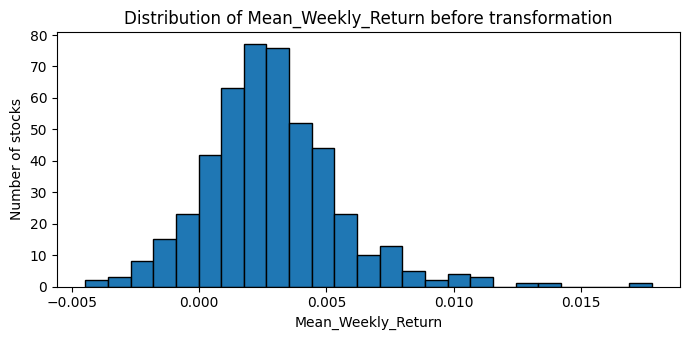

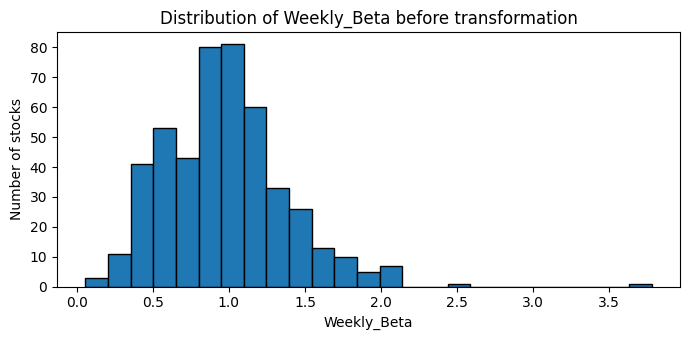

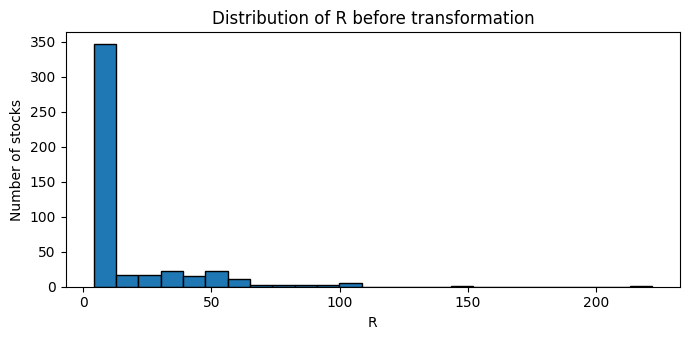

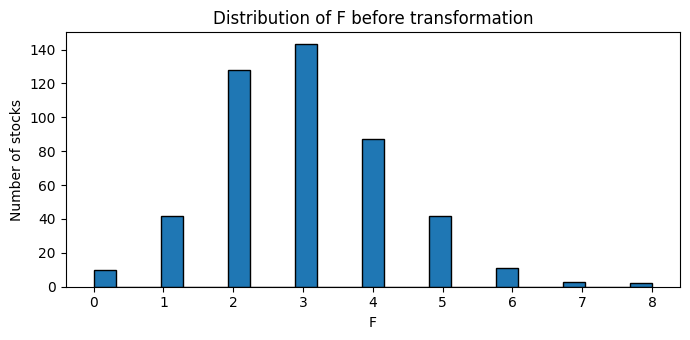

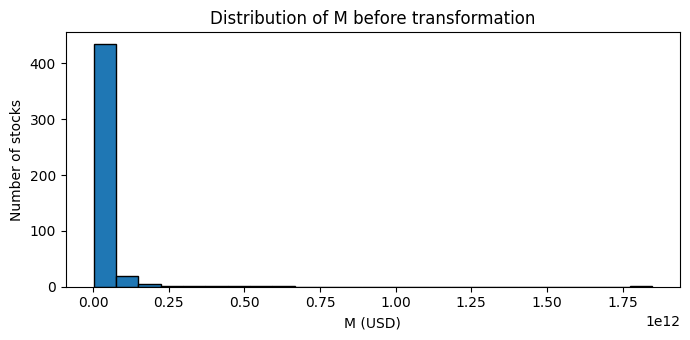

In [ ]:
# Visual inspection of the five original distributions

for feature in feature_diagnostics.columns:
    plt.figure(figsize=(7, 3.5))
    plt.hist(feature_diagnostics[feature], bins=25, edgecolor="black")
    plt.title("Distribution of " + feature + " before transformation")
    plt.xlabel(feature + (" (USD)" if feature == "M" else ""))
    plt.ylabel("Number of stocks")
    plt.tight_layout()
    plt.show()

In [ ]:
#Detect outliers
q1 = feature_diagnostics.quantile(0.25)
q3 = feature_diagnostics.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outlier_flags = (feature_diagnostics.lt(lower_fence) |
                 feature_diagnostics.gt(upper_fence))

outlier_summary = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Lower_Fence": lower_fence,
    "Upper_Fence": upper_fence,
    "Flagged_Stocks": outlier_flags.sum(),
    "Flagged_Percentage": outlier_flags.mean() * 100
})

print("IQR outlier summary:")
display(outlier_summary.round(6))

flagged_tickers = outlier_flags.index[outlier_flags.any(axis=1)]
print("Unique stocks flagged in at least one feature:", len(flagged_tickers))
print("Features with zero IQR:", iqr.index[iqr.eq(0)].tolist())

print("Original feature values for flagged stocks:")
display(feature_diagnostics.loc[flagged_tickers])

IQR outlier summary:


,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Flagged_Stocks,Flagged_Percentage
Mean_Weekly_Return,1.204000e-03,4.207000e-03,3.003000e-03,-3.301000e-03,8.712000e-03,15,3.205128
Weekly_Beta,6.780090e-01,1.191702e+00,5.136940e-01,-9.253200e-02,1.962243e+00,9,1.923077
R,1.100000e+01,1.400000e+01,3.000000e+00,6.500000e+00,1.850000e+01,113,24.145299
F,2.000000e+00,4.000000e+00,2.000000e+00,-1.000000e+00,7.000000e+00,2,0.427350
M,1.025241e+10,3.210048e+10,2.184807e+10,-2.251969e+10,6.487258e+10,45,9.615385


Unique stocks flagged in at least one feature: 152
Features with zero IQR: []
Original feature values for flagged stocks:


,Mean_Weekly_Return,Weekly_Beta,R,F,M
Ticker,,,,,
ABBV,0.003749,0.425365,11,3.0,6.837054e+10
ADBE,0.000990,1.553525,18,3.0,1.030403e+11
AMD,0.003624,1.877622,18,4.0,3.131659e+11
AES,-0.001420,1.143913,54,3.0,1.119578e+10
APD,0.001183,0.708584,85,1.0,2.662261e+10
...,...,...,...,...,...
WEC,0.001375,0.384708,151,0.0,1.081689e+10
WFC,0.005090,1.015733,11,3.0,7.270194e+10
WYNN,0.000740,0.998868,47,2.0,1.373834e+10


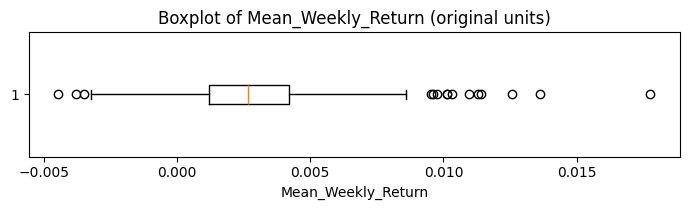

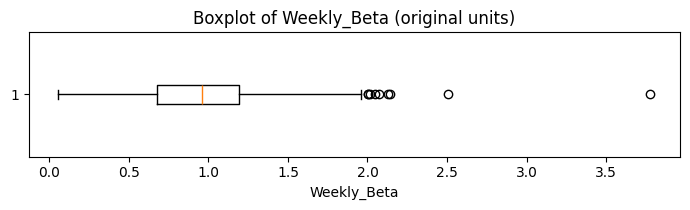

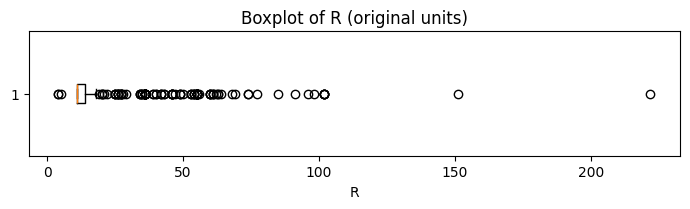

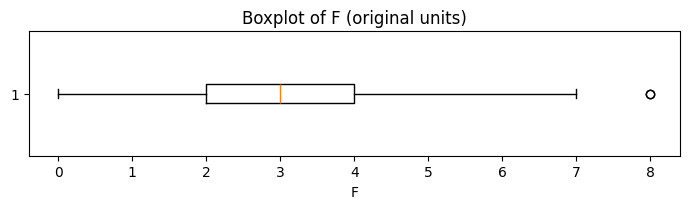

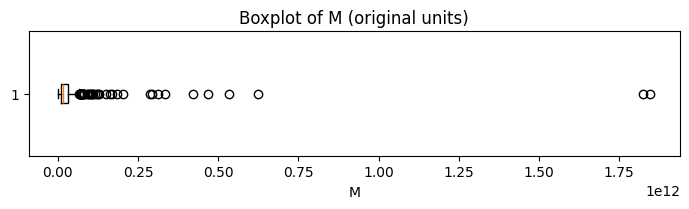

In [ ]:
#Visualise outliers using box plots
for feature in feature_diagnostics.columns:
    plt.figure(figsize=(7, 2.2))
    plt.boxplot(feature_diagnostics[feature], vert=False, whis=1.5)
    plt.title("Boxplot of " + feature + " (original units)")
    plt.xlabel(feature)
    plt.tight_layout()
    plt.show()

In [ ]:
#Review the flagged stocks against previous calculation evidence

outlier_review = feature_diagnostics.loc[flagged_tickers].join(
    outlier_flags.loc[flagged_tickers].add_suffix("_IQR_Flag")
)
outlier_review = outlier_review.join(
    risk_return_summary[["Paired_Weeks", "Weekly_Coverage_Percentage"]]
)
outlier_review = outlier_review.join(
    rfm_summary[["Recency_Status", "Frequency_Status", "Monetary_Status",
                 "Basis_Issue"]]
)

print("Flagged stock review:")
display(outlier_review)

Flagged stock review:


,Mean_Weekly_Return,Weekly_Beta,R,F,M,Mean_Weekly_Return_IQR_Flag,Weekly_Beta_IQR_Flag,R_IQR_Flag,F_IQR_Flag,M_IQR_Flag,Paired_Weeks,Weekly_Coverage_Percentage,Recency_Status,Frequency_Status,Monetary_Status,Basis_Issue
Ticker,,,,,,,,,,,,,,,,
ABBV,0.003749,0.425365,11,3.0,6.837054e+10,False,False,False,False,True,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,
ADBE,0.000990,1.553525,18,3.0,1.030403e+11,False,False,False,False,True,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,
AMD,0.003624,1.877622,18,4.0,3.131659e+11,False,False,False,False,True,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,
AES,-0.001420,1.143913,54,3.0,1.119578e+10,False,False,True,False,False,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,
APD,0.001183,0.708584,85,1.0,2.662261e+10,False,False,True,False,False,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
WEC,0.001375,0.384708,151,0.0,1.081689e+10,False,False,True,False,False,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,
WFC,0.005090,1.015733,11,3.0,7.270194e+10,False,False,False,False,True,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,
WYNN,0.000740,0.998868,47,2.0,1.373834e+10,False,False,True,False,False,207,100.0,Valid,Valid,Valid inputs; provider basis assumed,


In [ ]:
#Log transformation to monetary

risk_return_input = risk_return_original.copy()
rfm_input = rfm_original.copy()

# log transformation of Monetary
rfm_input["Log_M"] = np.log1p(rfm_input["M"])

# Log transformation of Recency due to its strong positive skew
rfm_input["Log_R"] = np.log1p(rfm_input["R"])
rfm_input = rfm_input[["Log_R", "F", "Log_M"]]

print("RFM features after log transformation:")
display(rfm_input.head())

RFM features after log transformation:


,Log_R,F,Log_M
Ticker,,,
AOS,2.484907,2.0,22.281196
ABT,2.484907,1.0,24.285172
ABBV,2.484907,3.0,24.948208
ACN,2.484907,2.0,24.674400
ADBE,2.944439,3.0,25.358386


Monetary skewness before and after log1p:


,Skewness
M_Original,11.475
Log_M,1.090


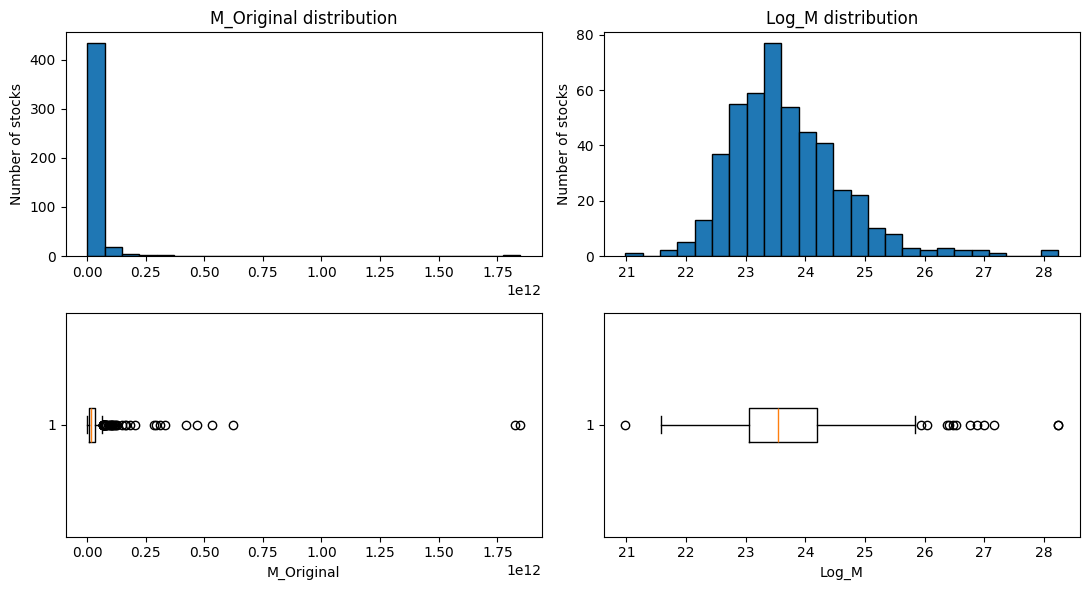

In [ ]:
#Comparing distributions before vs after transformations
monetary_comparison = pd.DataFrame({
    "M_Original": rfm_original["M"],
    "Log_M": rfm_input["Log_M"]
})

print("Monetary skewness before and after log1p:")
display(monetary_comparison.skew().to_frame("Skewness").round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for i, feature in enumerate(monetary_comparison.columns):
    axes[0, i].hist(monetary_comparison[feature], bins=25, edgecolor="black")
    axes[0, i].set_title(feature + " distribution")
    axes[0, i].set_ylabel("Number of stocks")
    axes[1, i].boxplot(monetary_comparison[feature], vert=False, whis=1.5)
    axes[1, i].set_xlabel(feature)
plt.tight_layout()
plt.show()

In [ ]:
#Comparing IQR before vs after transformation
m_q1 = monetary_comparison.quantile(0.25)
m_q3 = monetary_comparison.quantile(0.75)
m_iqr = m_q3 - m_q1
m_flags = (monetary_comparison.lt(m_q1 - 1.5 * m_iqr) |
           monetary_comparison.gt(m_q3 + 1.5 * m_iqr))

m_diagnostics = pd.DataFrame({
    "Skewness": monetary_comparison.skew(),
    "IQR_Flagged_Stocks": m_flags.sum(),
    "IQR_Flagged_Percentage": m_flags.mean() * 100
})
display(m_diagnostics.round(3))

,Skewness,IQR_Flagged_Stocks,IQR_Flagged_Percentage
M_Original,11.475,45,9.615
Log_M,1.090,13,2.778


Recency skewness before and after log1p:


,Skewness
R_Original,3.702
Log_R,1.613


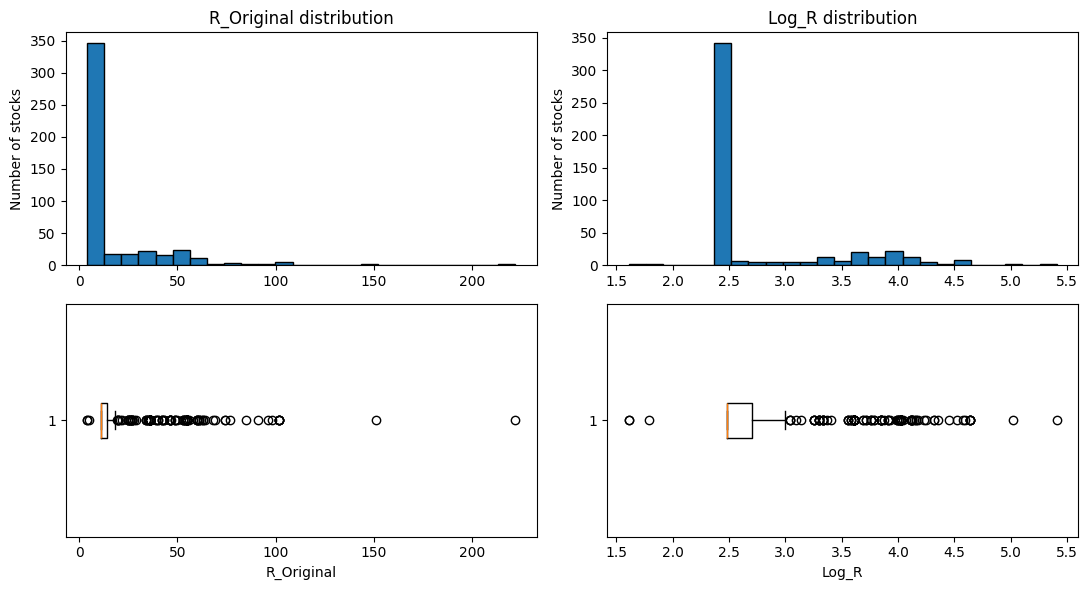

In [ ]:
recency_comparison = pd.DataFrame({
    "R_Original": rfm_original["R"],
    "Log_R": rfm_input["Log_R"]
})

print("Recency skewness before and after log1p:")
display(recency_comparison.skew().to_frame("Skewness").round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for i, feature in enumerate(recency_comparison.columns):
    axes[0, i].hist(recency_comparison[feature], bins=25, edgecolor="black")
    axes[0, i].set_title(feature + " distribution")
    axes[0, i].set_ylabel("Number of stocks")
    axes[1, i].boxplot(recency_comparison[feature], vert=False, whis=1.5)
    axes[1, i].set_xlabel(feature)
plt.tight_layout()
plt.show()

In [ ]:
# Compare IQR flags before and after transformation
r_q1 = recency_comparison.quantile(0.25)
r_q3 = recency_comparison.quantile(0.75)
r_iqr = r_q3 - r_q1
r_flags = (recency_comparison.lt(r_q1 - 1.5 * r_iqr) |
           recency_comparison.gt(r_q3 + 1.5 * r_iqr))

r_diagnostics = pd.DataFrame({
    "Skewness": recency_comparison.skew(),
    "IQR_Flagged_Stocks": r_flags.sum(),
    "IQR_Flagged_Percentage": r_flags.mean() * 100
})
display(r_diagnostics.round(3))

,Skewness,IQR_Flagged_Stocks,IQR_Flagged_Percentage
R_Original,3.702,113,24.145
Log_R,1.613,112,23.932


In [ ]:
#Standardising the two feature matrices


print("Risk-return standard deviations before scaling:")
print(risk_return_input.std(ddof=0))
print("RFM standard deviations before scaling:")
print(rfm_input.std(ddof=0))

assert (risk_return_input.std(ddof=0) > 0).all(), "Investigate constant risk-return feature"
assert (rfm_input.std(ddof=0) > 0).all(), "Investigate constant RFM feature"

# Risk and return features
risk_return_scaler = StandardScaler()
risk_return_scaled = pd.DataFrame(
    risk_return_scaler.fit_transform(risk_return_input),
    index=risk_return_input.index,
    columns=risk_return_input.columns
)

# RFM features (Log_R and Log_M rather than original R and M)
rfm_scaler = StandardScaler()
rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_input),
    index=rfm_input.index,
    columns=rfm_input.columns
)

print("Standardised risk-return features:")
display(risk_return_scaled.head())
print("Standardised RFM features:")
display(rfm_scaled.head())

Risk-return standard deviations before scaling:
Mean_Weekly_Return    0.00266
Weekly_Beta           0.40859
dtype: float64
RFM standard deviations before scaling:
Log_R    0.614797
F        1.337696
Log_M    0.947734
dtype: float64
Standardised risk-return features:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
AOS,-0.332082,0.153117
ABT,-0.715269,-0.970899
ABBV,0.328974,-1.358030
ACN,-0.187081,0.399076
ADBE,-0.708246,1.403074


Standardised RFM features:


,Log_R,F,Log_M
Ticker,,,
AOS,-0.520084,-0.721997,-1.481350
ABT,-0.520084,-1.469551,0.633142
ABBV,-0.520084,0.025557,1.332744
ACN,-0.520084,-0.721997,1.043836
ADBE,0.227370,0.025557,1.765543


In [ ]:
#Verifying the results

scaling_check = pd.DataFrame({
    "Mean_After_Scaling": pd.concat([
        risk_return_scaled.mean(), rfm_scaled.mean()
    ]),
    "Std_After_Scaling": pd.concat([
        risk_return_scaled.std(ddof=0), rfm_scaled.std(ddof=0)
    ])
})

print("Scaling validation (expected mean 0 and standard deviation 1):")
display(scaling_check.round(6))

for matrix in [risk_return_scaled, rfm_scaled]:
    assert np.isfinite(matrix.to_numpy()).all()
    assert np.allclose(matrix.mean(), 0, atol=1e-8)
    assert np.allclose(matrix.std(ddof=0), 1, atol=1e-8)

assert risk_return_scaled.index.equals(rfm_scaled.index)
assert risk_return_scaled.index.equals(common_features.index)
assert risk_return_scaled.shape == risk_return_original.shape
assert rfm_scaled.shape == rfm_original.shape
print("Both matrices passed the standardisation and common-sample checks.")

Scaling validation (expected mean 0 and standard deviation 1):


,Mean_After_Scaling,Std_After_Scaling
Mean_Weekly_Return,-0.0,1.0
Weekly_Beta,0.0,1.0
Log_R,-0.0,1.0
F,-0.0,1.0
Log_M,0.0,1.0


Both matrices passed the standardisation and common-sample checks.


In [ ]:
pd.testing.assert_frame_equal(risk_return_original, common_features[risk_columns])
pd.testing.assert_frame_equal(rfm_original, common_features[rfm_columns])
assert np.allclose(np.expm1(rfm_input["Log_M"]), rfm_original["M"])
assert np.allclose(np.expm1(rfm_input["Log_R"]), rfm_original["R"])
print("Original feature values preserved; both log transformations verified.")

Original feature values preserved; both log transformations verified.


In [ ]:
#Investigating how the transformations affect the distances

scaled_diagnostics = risk_return_scaled.join(rfm_scaled)
z_summary = pd.DataFrame({
    "Maximum_Absolute_Z": scaled_diagnostics.abs().max(),
    "Stocks_With_Abs_Z_Above_3": (scaled_diagnostics.abs() > 3).sum()
})
print("Remaining large standardised values:")
display(z_summary.round(3))

Remaining large standardised values:


,Maximum_Absolute_Z,Stocks_With_Abs_Z_Above_3
Mean_Weekly_Return,5.601,6
Weekly_Beta,6.849,2
Log_R,4.233,2
F,3.763,5
Log_M,4.811,7


In [ ]:
#Worked comparison of distance contributions for two actual shares
# Select contrasting shares from the actual data
m_order = rfm_original["M"].sort_values(kind="stable")
stock_a = m_order.index[-1]
stock_b = m_order.index[len(m_order) // 2]
print("Largest-M stock:", stock_a)
print("Middle-ranked M stock:", stock_b)
display(rfm_original.loc[[stock_a, stock_b]])

# Diagnostic comparison: standardisation without logarithm
rfm_scaled_no_log = pd.DataFrame(
    StandardScaler().fit_transform(rfm_original),
    index=rfm_original.index,
    columns=rfm_original.columns
)

# Same stock pair at each preparation stage
raw_diff = (rfm_original.loc[stock_a] - rfm_original.loc[stock_b]) ** 2
scaled_diff = (rfm_scaled_no_log.loc[stock_a] -
               rfm_scaled_no_log.loc[stock_b]) ** 2
final_diff = (rfm_scaled.loc[stock_a] - rfm_scaled.loc[stock_b]) ** 2

# Relabel Log_R as R and Log_M as M for this comparison table only
final_diff = final_diff.rename({"Log_R": "R", "Log_M": "M"})
distance_contributions = pd.DataFrame({
    "Raw_Features": raw_diff,
    "Scaled_Without_Log": scaled_diff,
    "Log_R_M_Then_Scaled": final_diff
})

# Percent of squared distance; leave identical pairs undefined
contribution_totals = distance_contributions.sum()
distance_percent = distance_contributions.div(
    contribution_totals.replace(0, np.nan), axis=1
) * 100

print("Contribution to squared distance (%) for the selected pair:")
display(distance_percent.round(2))
print("Euclidean distance after scaling, without log:",
      round(np.sqrt(contribution_totals["Scaled_Without_Log"]), 4))
print("Euclidean distance after log and scaling:",
      round(np.sqrt(contribution_totals["Log_R_M_Then_Scaled"]), 4))

Largest-M stock: TSLA
Middle-ranked M stock: HPE


,R,F,M
Ticker,,,
TSLA,50,5.0,1.847697e+12
HPE,11,3.0,1.670905e+10


Contribution to squared distance (%) for the selected pair:


,Raw_Features,Scaled_Without_Log,Log_R_M_Then_Scaled
R,0.0,1.66,17.08
F,0.0,1.12,6.89
M,100.0,97.22,76.03


Euclidean distance after scaling, without log: 14.1341
Euclidean distance after log and scaling: 5.6946


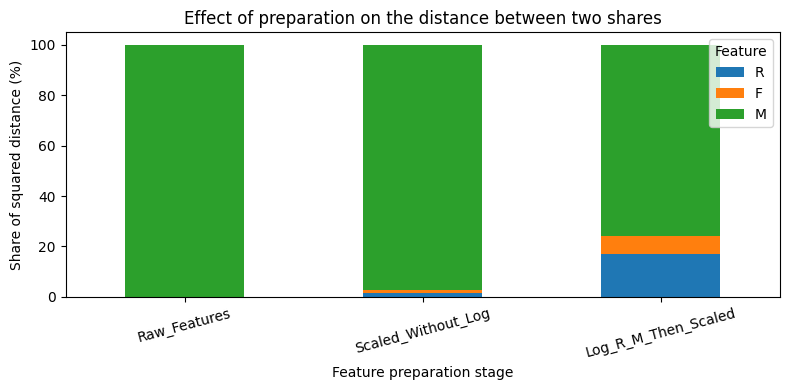

In [ ]:
distance_percent.T.plot(kind="bar", stacked=True, figsize=(8, 4))
plt.ylabel("Share of squared distance (%)")
plt.xlabel("Feature preparation stage")
plt.title("Effect of preparation on the distance between two shares")
plt.xticks(rotation=15)
plt.legend(title="Feature")
plt.tight_layout()
plt.show()

In [ ]:
#Saving the results
# Save the original features for later cluster profiling
risk_return_original.to_csv("risk_return_original_common.csv")
rfm_original.to_csv("rfm_original_common.csv")

# Save the transformed but unscaled and the final standardised features
rfm_input.to_csv("rfm_log_transformed.csv")
risk_return_scaled.to_csv("risk_return_scaled.csv")
rfm_scaled.to_csv("rfm_scaled.csv")

# Record the fitted scaling parameters
risk_scaling_parameters = pd.DataFrame({
    "Mean": risk_return_scaler.mean_,
    "Scale": risk_return_scaler.scale_
}, index=risk_return_input.columns)
rfm_scaling_parameters = pd.DataFrame({
    "Mean": rfm_scaler.mean_,
    "Scale": rfm_scaler.scale_
}, index=rfm_input.columns)

risk_scaling_parameters.to_csv("risk_return_scaling_parameters.csv")
rfm_scaling_parameters.to_csv("rfm_scaling_parameters.csv")
outlier_summary.to_csv("feature_outlier_summary.csv")
outlier_review.to_csv("feature_outlier_review.csv")
m_diagnostics.to_csv("monetary_transformation_diagnostics.csv")
r_diagnostics.to_csv("recency_transformation_diagnostics.csv")
scaling_check.to_csv("feature_scaling_check.csv")
distance_percent.to_csv("feature_distance_contributions.csv")
print("Distance diagnostic pair:", stock_a, stock_b)
print("Task 2.1 feature matrices and evidence saved.")

Distance diagnostic pair: TSLA HPE
Task 2.1 feature matrices and evidence saved.


###2.2 Agglomerative clustering

In [ ]:

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score


ward_matrices = {
    "Risk_Return": risk_return_scaled,
    "RFM": rfm_scaled
}
ward_original = {
    "Risk_Return": risk_return_original,
    "RFM": rfm_original
}

# Check that the same stocks are used in both clustering problems
assert risk_return_scaled.index.equals(rfm_scaled.index)
assert risk_return_scaled.index.equals(risk_return_original.index)
assert rfm_scaled.index.equals(rfm_original.index)
assert risk_return_scaled.index.is_unique
assert np.isfinite(risk_return_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()
assert risk_return_scaled.shape[1] == 2
assert rfm_scaled.shape[1] == 3
assert rfm_scaled.columns.tolist() == ["Log_R", "F", "Log_M"], (
    "RFM must use standardised Log_R, F and Log_M from revised Task 2.1"
)
assert np.allclose(np.expm1(rfm_input["Log_R"]), rfm_original["R"])
assert np.allclose(np.expm1(rfm_input["Log_M"]), rfm_original["M"])
assert len(risk_return_scaled) >= 9, "Too few stocks to compare k = 2 to 8"

print("Common stocks:", len(risk_return_scaled))
print("Risk-return dimensions:", risk_return_scaled.shape)
print("RFM dimensions:", rfm_scaled.shape)
print("Risk-return columns:", risk_return_scaled.columns.tolist())
print("RFM columns:", rfm_scaled.columns.tolist())
print("Identical stock order:", risk_return_scaled.index.equals(rfm_scaled.index))

Common stocks: 468
Risk-return dimensions: (468, 2)
RFM dimensions: (468, 3)
Risk-return columns: ['Mean_Weekly_Return', 'Weekly_Beta']
RFM columns: ['Log_R', 'F', 'Log_M']
Identical stock order: True


In [ ]:
#hierarchichal clustering for risk return and RFM


ward_linkages = {}

for name, features in ward_matrices.items():
    ward_linkages[name] = linkage(
        features.to_numpy(),
        method="ward",
        metric="euclidean"
    )
    print(name, "Ward linkage shape:", ward_linkages[name].shape)
    print(name, "last five merge heights:",
          np.round(ward_linkages[name][-5:, 2], 3))


for name, features in ward_matrices.items():
    assert ward_linkages[name].shape == (len(features) - 1, 4)

print("Both Ward hierarchies fitted successfully.")

Risk_Return Ward linkage shape: (467, 4)
Risk_Return last five merge heights: [11.152 12.086 14.015 14.282 25.661]
RFM Ward linkage shape: (467, 4)
RFM last five merge heights: [12.501 13.619 15.966 21.529 29.3  ]
Both Ward hierarchies fitted successfully.


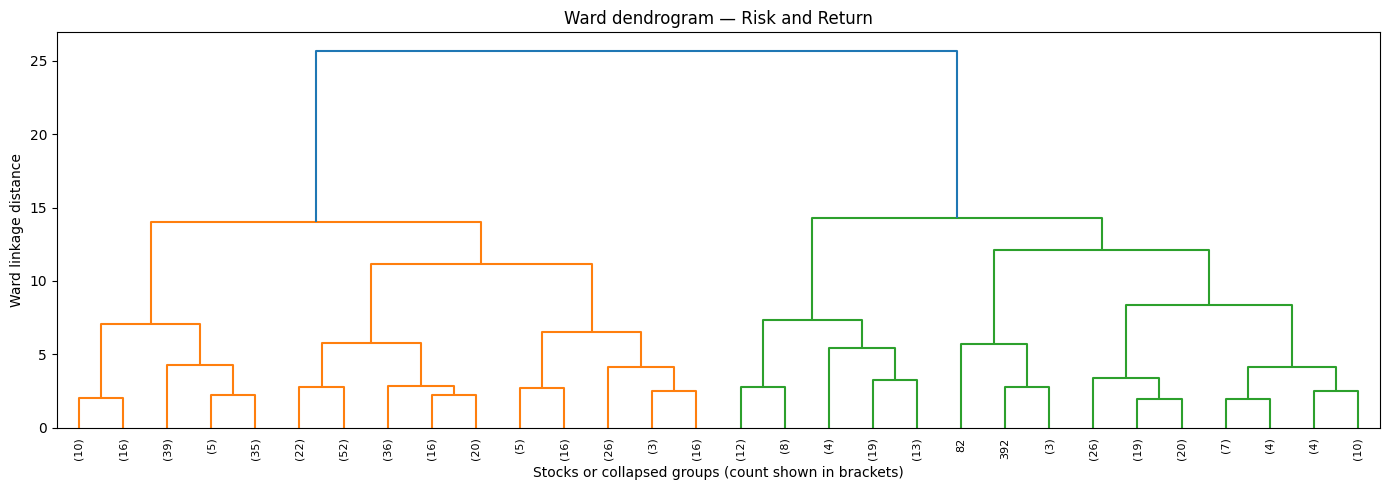

In [ ]:
#Visualising the risk return dendrogram
plt.figure(figsize=(14, 5))
dendrogram(
    ward_linkages["Risk_Return"],
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Ward dendrogram — Risk and Return")
plt.xlabel("Stocks or collapsed groups (count shown in brackets)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("ward_dendrogram_risk_return.png", dpi=200)
plt.show()

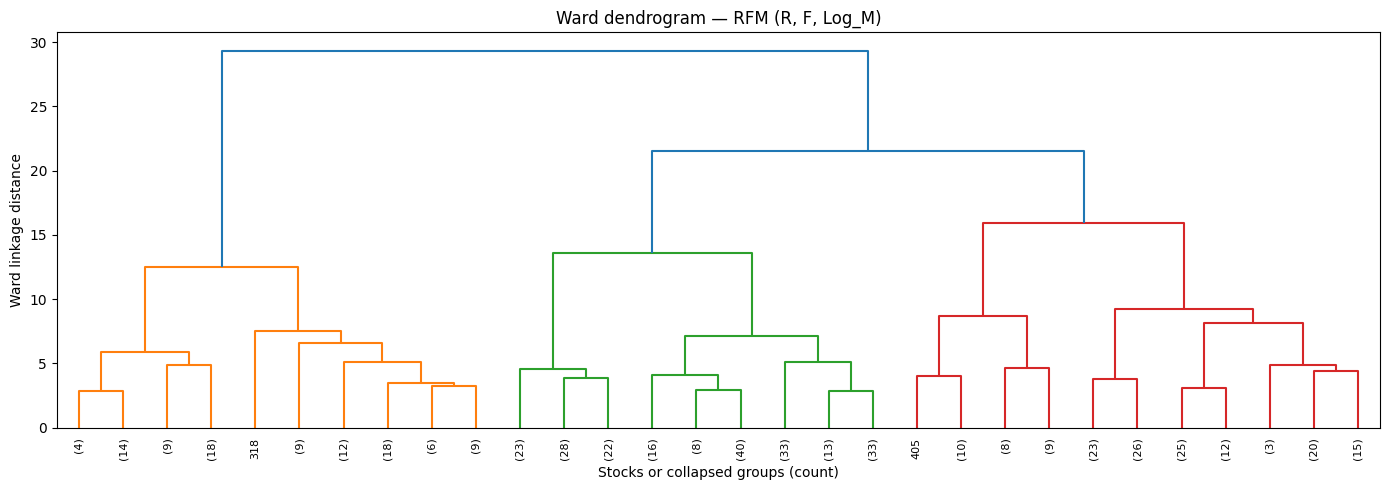

In [ ]:
#Visualising the RFM dendogram
plt.figure(figsize=(14, 5))
dendrogram(
    ward_linkages["RFM"],
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Ward dendrogram — RFM (R, F, Log_M)")
plt.xlabel("Stocks or collapsed groups (count)")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("ward_dendrogram_rfm.png", dpi=200)
plt.show()

In [ ]:
#Evaluating different cluster counts
#Calculating silhoutte scores and cluster sizes
k_values = range(2, 9)
ward_labels_by_k = {"Risk_Return": {}, "RFM": {}}
ward_records = []

for name, features in ward_matrices.items():
    for k in k_values:
        labels = cut_tree(
            ward_linkages[name], n_clusters=k
        ).ravel() + 1     # Show cluster numbers from 1 to k

        ward_labels_by_k[name][k] = labels
        sizes = pd.Series(labels).value_counts().sort_index()
        silhouette = silhouette_score(
            features.to_numpy(), labels, metric="euclidean"
        )

        ward_records.append({
            "Matrix": name,
            "k": k,
            "Silhouette": silhouette,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Largest_Cluster_Percent": 100 * sizes.max() / len(features),
            "Singleton_Clusters": (sizes == 1).sum(),
            "Cluster_Sizes": ", ".join(str(size) for size in sizes.tolist())
        })

ward_diagnostics = pd.DataFrame(ward_records)

print("Ward diagnostics for all feasible cluster counts:")
display(ward_diagnostics.round(3))

Ward diagnostics for all feasible cluster counts:


,Matrix,k,Silhouette,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Percent,Singleton_Clusters,Cluster_Sizes
0,Risk_Return,2,0.376,151,317,67.735,0,"317, 151"
1,Risk_Return,3,0.361,56,317,67.735,0,"317, 56, 95"
2,Risk_Return,4,0.304,56,212,45.299,0,"212, 105, 56, 95"
3,Risk_Return,5,0.316,5,212,45.299,0,"212, 105, 56, 90, 5"
4,Risk_Return,6,0.324,5,146,31.197,0,"146, 105, 56, 66, 90, 5"
5,Risk_Return,7,0.321,5,146,31.197,0,"146, 105, 56, 66, 65, 25, 5"
6,Risk_Return,8,0.335,5,146,31.197,0,"146, 105, 36, 20, 66, 65, 25, 5"
7,RFM,2,0.405,100,368,78.632,0,"368, 100"
8,RFM,3,0.322,100,216,46.154,0,"216, 152, 100"
9,RFM,4,0.326,28,216,46.154,0,"216, 124, 28, 100"


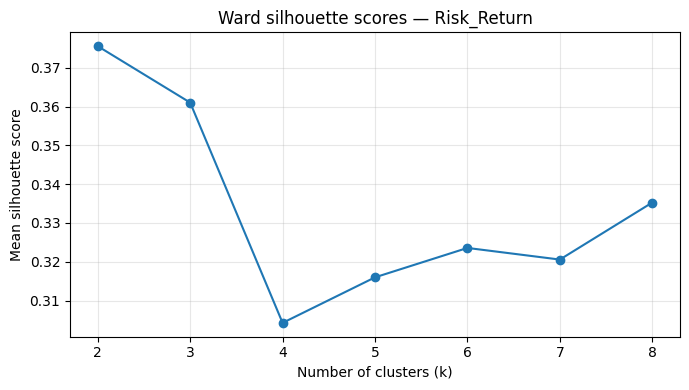

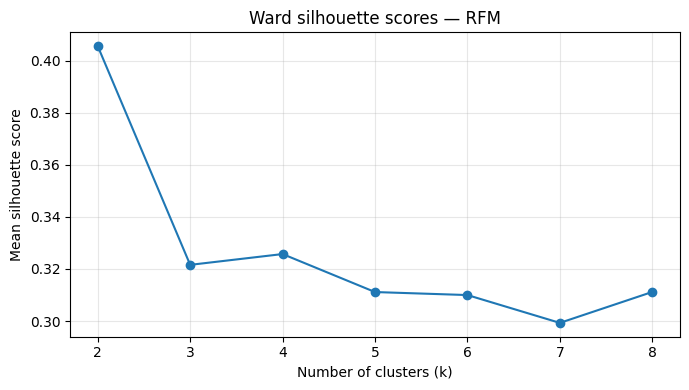

In [ ]:
#Comparing feasible cluster counts from 2 to 8
for name in ward_matrices:
    results = ward_diagnostics[ward_diagnostics["Matrix"] == name]

    plt.figure(figsize=(7, 4))
    plt.plot(results["k"], results["Silhouette"], marker="o")
    plt.xticks(list(k_values))
    plt.title("Ward silhouette scores — " + name)
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Mean silhouette score")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("ward_silhouette_" + name.lower() + ".png", dpi=200)
    plt.show()

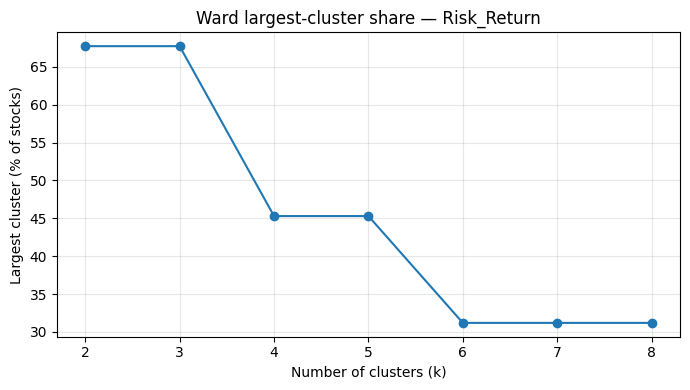

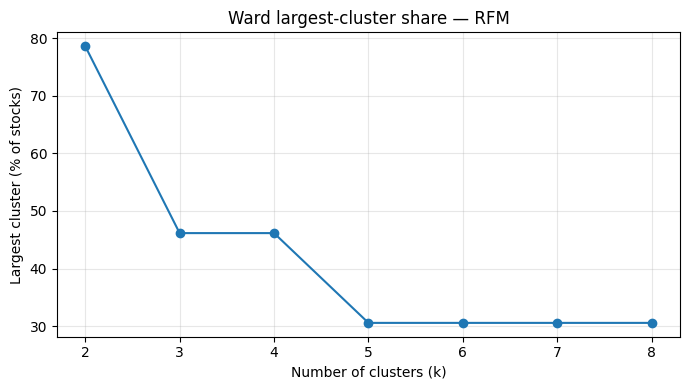

In [ ]:
#Plot largest-cluster percentages across k = 2 to 8
for name in ward_matrices:
    results = ward_diagnostics[ward_diagnostics["Matrix"] == name]

    plt.figure(figsize=(7, 4))
    plt.plot(results["k"], results["Largest_Cluster_Percent"], marker="o")
    plt.xticks(list(k_values))
    plt.title("Ward largest-cluster share — " + name)
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Largest cluster (% of stocks)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("ward_largest_cluster_" + name.lower() + ".png", dpi=200)
    plt.show()

In [ ]:
#Exploring different profiles
# Medians are less sensitive to extreme stocks than means
def ward_profile(name, k):
    original = ward_original[name].copy()
    original["Cluster"] = ward_labels_by_k[name][k]
    groups = original.groupby("Cluster")
    sizes = groups.size()

    profile = pd.DataFrame({
        "Stocks": sizes,
        "Stock_Percent": 100 * sizes / len(original)
    })

    if name == "Risk_Return":
        profile["Median_Weekly_Return_Percent"] = (
            groups["Mean_Weekly_Return"].median() * 100
        )
        profile["Median_Beta"] = groups["Weekly_Beta"].median()
    else:
        profile["Median_R_Days"] = groups["R"].median()
        profile["Median_F_Events"] = groups["F"].median()
        profile["Median_M_USD_Billions"] = (
            groups["M"].median() / 1e9
        )

    return profile.round(3)

In [ ]:
#what are the three strongest silhouette candidates for each matrix
#These candidates should be investigated
ward_shortlist = {}

for name in ward_matrices:
    results = ward_diagnostics[ward_diagnostics["Matrix"] == name]
    best_three = results.sort_values(
        "Silhouette", ascending=False
    )["k"].head(3).tolist()

    ward_shortlist[name] = best_three
    print("\n", name, "— candidate k values:", best_three)

    for k in best_three:
        print("\n", name, "cluster profiles for k =", k)
        display(ward_profile(name, k))


 Risk_Return — candidate k values: [2, 3, 8]

 Risk_Return cluster profiles for k = 2


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,317,67.735,0.199,0.824
2,151,32.265,0.463,1.337



 Risk_Return cluster profiles for k = 3


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,317,67.735,0.199,0.824
2,56,11.966,0.267,1.554
3,95,20.299,0.547,1.179



 Risk_Return cluster profiles for k = 8


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,146,31.197,0.240,0.962
2,105,22.436,0.305,0.530
3,36,7.692,0.165,1.480
4,20,4.274,0.460,1.770
5,66,14.103,-0.038,0.823
6,65,13.889,0.483,1.139
7,25,5.342,0.794,1.258
8,5,1.068,1.258,2.003


... (2 outputs left out)


 RFM cluster profiles for k = 4


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,216,46.154,11.0,3.0,10.791
2,124,26.496,11.0,3.0,35.824
3,28,5.983,11.0,5.0,61.087
4,100,21.368,46.5,2.0,19.886



 RFM cluster profiles for k = 3


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,216,46.154,11.0,3.0,10.791
2,152,32.479,11.0,3.0,37.427
3,100,21.368,46.5,2.0,19.886


In [ ]:
#Inspecting the real tickers inside these clusters.


inspect_name = "RFM"
inspect_k = 4
inspect_cluster = 1

inspect_labels = pd.Series(
    ward_labels_by_k[inspect_name][inspect_k],
    index=ward_matrices[inspect_name].index,
    name="Cluster"
)

inspect_stocks = inspect_labels[inspect_labels == inspect_cluster].index
print("Stocks in selected cluster:", len(inspect_stocks))
print("Showing up to 20 stock rows:")
display(ward_original[inspect_name].loc[inspect_stocks].head(20))

Stocks in selected cluster: 216
Showing up to 20 stock rows:


,R,F,M
Ticker,,,
AOS,11,2.0,4.748980e+09
AFL,11,2.0,1.328456e+10
A,11,2.0,1.400180e+10
ALB,11,2.0,1.313103e+10
ARE,11,1.0,8.493121e+09
ALGN,11,4.0,1.067663e+10
ALLE,11,2.0,7.110592e+09
AMCR,11,6.0,7.685901e+09
AEE,11,4.0,7.567405e+09


In [ ]:
#Inspecting the real tickers inside these clusters.

inspect_name = "RFM"
inspect_k = 4
inspect_cluster = 2

inspect_labels = pd.Series(
    ward_labels_by_k[inspect_name][inspect_k],
    index=ward_matrices[inspect_name].index,
    name="Cluster"
)

inspect_stocks = inspect_labels[inspect_labels == inspect_cluster].index

print("Stocks in selected cluster:", len(inspect_stocks))
print("Showing up to 20 stock rows:")

display(ward_original[inspect_name].loc[inspect_stocks].head(20))

Stocks in selected cluster: 124
Showing up to 20 stock rows:


,R,F,M
Ticker,,,
ABT,11,1.0,3.523027e+10
ABBV,11,3.0,6.837054e+10
ACN,11,2.0,5.199430e+10
ADBE,18,3.0,1.030403e+11
ABNB,11,3.0,3.652850e+10
MO,11,2.0,2.454050e+10
AXP,11,3.0,4.437482e+10
AMT,11,3.0,2.976519e+10
AMGN,11,4.0,5.655089e+10


In [ ]:
#Inspecting the real tickers inside these clusters.

inspect_name = "RFM"
inspect_k = 4
inspect_cluster = 3

inspect_labels = pd.Series(
    ward_labels_by_k[inspect_name][inspect_k],
    index=ward_matrices[inspect_name].index,
    name="Cluster"
)

inspect_stocks = inspect_labels[inspect_labels == inspect_cluster].index

print("Stocks in selected cluster:", len(inspect_stocks))
print("Showing up to 20 stock rows:")

display(ward_original[inspect_name].loc[inspect_stocks].head(20))

Stocks in selected cluster: 28
Showing up to 20 stock rows:


,R,F,M
Ticker,,,
AMD,18,4.0,3.131659e+11
GOOGL,20,5.0,2.943802e+11
GOOG,11,5.0,2.028245e+11
AMZN,11,5.0,4.681770e+11
AJG,4,6.0,2.824304e+10
BX,11,5.0,3.538247e+10
BA,11,5.0,1.276863e+11
AVGO,11,6.0,3.340388e+11
CI,13,8.0,3.789504e+10


In [ ]:
#Inspecting the real tickers inside these clusters.

inspect_name = "RFM"
inspect_k = 4
inspect_cluster = 4

inspect_labels = pd.Series(
    ward_labels_by_k[inspect_name][inspect_k],
    index=ward_matrices[inspect_name].index,
    name="Cluster"
)

inspect_stocks = inspect_labels[inspect_labels == inspect_cluster].index

print("Stocks in selected cluster:", len(inspect_stocks))
print("Showing up to 20 stock rows:")

display(ward_original[inspect_name].loc[inspect_stocks].head(20))

Stocks in selected cluster: 100
Showing up to 20 stock rows:


,R,F,M
Ticker,,,
AES,54,3.0,1.119578e+10
APD,85,1.0,2.662261e+10
AKAM,53,1.0,1.032339e+10
LNT,60,2.0,5.708137e+09
ALL,36,3.0,1.743433e+10
APH,77,1.0,2.778599e+10
ADI,36,1.0,3.849918e+10
AON,22,3.0,2.280256e+10
ANET,53,3.0,4.614568e+10


In [ ]:
#Inspecting the real tickers inside these clusters.

inspect_name = "Risk_Return"
inspect_k = 3
inspect_cluster = 1

inspect_labels = pd.Series(
    ward_labels_by_k[inspect_name][inspect_k],
    index=ward_matrices[inspect_name].index,
    name="Cluster"
)

inspect_stocks = inspect_labels[inspect_labels == inspect_cluster].index

print("Stocks in selected cluster:", len(inspect_stocks))
print("Showing up to 20 stock rows:")

display(ward_original[inspect_name].loc[inspect_stocks].head(20))

Stocks in selected cluster: 317
Showing up to 20 stock rows:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
AOS,0.001991,1.042805
ABT,0.000971,0.583543
ABBV,0.003749,0.425365
ACN,0.002376,1.143301
AES,-0.001420,1.143913
AFL,0.005004,0.707196
A,0.001121,1.074724
APD,0.001183,0.708584
AKAM,0.000436,0.853553


In [ ]:
#Inspecting the real tickers inside these clusters.

inspect_name = "Risk_Return"
inspect_k = 3
inspect_cluster = 2

inspect_labels = pd.Series(
    ward_labels_by_k[inspect_name][inspect_k],
    index=ward_matrices[inspect_name].index,
    name="Cluster"
)

inspect_stocks = inspect_labels[inspect_labels == inspect_cluster].index

print("Stocks in selected cluster:", len(inspect_stocks))
print("Showing up to 20 stock rows:")

display(ward_original[inspect_name].loc[inspect_stocks].head(20))

Stocks in selected cluster: 56
Showing up to 20 stock rows:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
ADBE,0.000990,1.553525
AMD,0.003624,1.877622
ABNB,0.001475,1.472709
ALB,-0.000899,1.622591
ALGN,-0.002564,1.835953
AMZN,0.002681,1.386667
AMAT,0.004506,1.782156
ADSK,0.000913,1.687834
BLK,0.002785,1.405853


In [ ]:
#Inspecting the real tickers inside these clusters.

inspect_name = "Risk_Return"
inspect_k = 3
inspect_cluster = 3

inspect_labels = pd.Series(
    ward_labels_by_k[inspect_name][inspect_k],
    index=ward_matrices[inspect_name].index,
    name="Cluster"
)

inspect_stocks = inspect_labels[inspect_labels == inspect_cluster].index

print("Stocks in selected cluster:", len(inspect_stocks))
print("Showing up to 20 stock rows:")

display(ward_original[inspect_name].loc[inspect_stocks].head(20))

Stocks in selected cluster: 95
Showing up to 20 stock rows:


,Mean_Weekly_Return,Weekly_Beta
Ticker,,
GOOGL,0.004621,1.220894
GOOG,0.004629,1.209198
AXP,0.005443,1.212779
AMP,0.005768,1.278280
APH,0.004323,1.198753
APO,0.007845,1.355792
AAPL,0.003930,1.174836
ARES,0.008111,1.544043
ANET,0.010310,1.419564


In [ ]:
#Selecting the final k for each matrix
selected_k_risk = 3
selected_k_rfm = 4

if selected_k_risk is None or selected_k_rfm is None:
    print("Select both k values from 2 to 8 after reviewing Steps 3–5.")
else:
    assert selected_k_risk in k_values
    assert selected_k_rfm in k_values

    ward_risk_labels = pd.Series(
        ward_labels_by_k["Risk_Return"][selected_k_risk],
        index=risk_return_scaled.index,
        name="Ward_Risk_Cluster"
    )
    ward_rfm_labels = pd.Series(
        ward_labels_by_k["RFM"][selected_k_rfm],
        index=rfm_scaled.index,
        name="Ward_RFM_Cluster"
    )

    ward_selected_labels = pd.concat(
        [ward_risk_labels, ward_rfm_labels], axis=1
    )

    print("Selected risk-return k:", selected_k_risk)
    print("Selected RFM k:", selected_k_rfm)
    print("Final Ward cluster sizes:")
    display(ward_risk_labels.value_counts().sort_index().to_frame("Stocks"))
    display(ward_rfm_labels.value_counts().sort_index().to_frame("Stocks"))

    print("Final risk-return profile (original units):")
    display(ward_profile("Risk_Return", selected_k_risk))
    print("Final RFM profile (original units):")
    display(ward_profile("RFM", selected_k_rfm))

Selected risk-return k: 3
Selected RFM k: 4
Final Ward cluster sizes:


,Stocks
Ward_Risk_Cluster,
1,317
2,56
3,95


,Stocks
Ward_RFM_Cluster,
1,216
2,124
3,28
4,100


Final risk-return profile (original units):


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,317,67.735,0.199,0.824
2,56,11.966,0.267,1.554
3,95,20.299,0.547,1.179


Final RFM profile (original units):


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,216,46.154,11.0,3.0,10.791
2,124,26.496,11.0,3.0,35.824
3,28,5.983,11.0,5.0,61.087
4,100,21.368,46.5,2.0,19.886


In [ ]:
#Saving the results

ward_diagnostics.to_csv("ward_k_selection_diagnostics.csv", index=False)

# Save original candidate profiles
candidate_profiles = []
for name in ward_matrices:
    for k in ward_shortlist[name]:
        table = ward_profile(name, k).reset_index()
        table.insert(0, "k", k)
        table.insert(0, "Matrix", name)
        candidate_profiles.append(table)

pd.concat(candidate_profiles, ignore_index=True).to_csv(
    "ward_candidate_original_unit_profiles.csv", index=False
)

if selected_k_risk is not None and selected_k_rfm is not None:
    # Confirm every original ticker has exactly one label in each solution
    assert ward_selected_labels.index.equals(risk_return_scaled.index)
    assert not ward_selected_labels.isna().any().any()
    assert ward_risk_labels.nunique() == selected_k_risk
    assert ward_rfm_labels.nunique() == selected_k_rfm

    ward_selected_labels.to_csv("ward_selected_cluster_labels.csv")
    ward_profile("Risk_Return", selected_k_risk).to_csv(
        "ward_risk_final_profile.csv"
    )
    ward_profile("RFM", selected_k_rfm).to_csv(
        "ward_rfm_final_profile.csv"
    )

    pd.DataFrame({
        "Matrix": ["Risk_Return", "RFM"],
        "Selected_k": [selected_k_risk, selected_k_rfm],
        "Method": ["Ward", "Ward"],
        "Distance": ["Euclidean", "Euclidean"],
        "Stocks": [len(risk_return_scaled), len(rfm_scaled)]
    }).to_csv("ward_selected_settings.csv", index=False)

    print("All final Ward labels, profiles and selection evidence saved.")
else:
    print("Candidate results saved. Final labels await your selected k values.")

All final Ward labels, profiles and selection evidence saved.


###2.3 K-means Clustering

In [ ]:
#Reusing previous metrics
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

kmeans_matrices = {
    "Risk_Return": risk_return_scaled,
    "RFM": rfm_scaled
}

kmeans_original = {
    "Risk_Return": risk_return_original,
    "RFM": rfm_original
}

assert risk_return_scaled.index.equals(rfm_scaled.index)
assert risk_return_scaled.index.equals(risk_return_original.index)
assert rfm_scaled.index.equals(rfm_original.index)
assert risk_return_scaled.index.is_unique
assert np.isfinite(risk_return_scaled.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()
assert risk_return_scaled.columns.tolist() == ["Mean_Weekly_Return", "Weekly_Beta"]
assert rfm_scaled.columns.tolist() == ["Log_R", "F", "Log_M"]
assert len(risk_return_scaled) >= 9

print("Common stocks:", len(risk_return_scaled))
print("Risk-return matrix:", risk_return_scaled.shape)
print("RFM matrix:", rfm_scaled.shape)
print("Identical stock order:", risk_return_scaled.index.equals(rfm_scaled.index))

Common stocks: 468
Risk-return matrix: (468, 2)
RFM matrix: (468, 3)
Identical stock order: True


In [ ]:
# Fit K-means for every k from 2 to 8
#Calculating silhouettes, inertia and group sizes
k_values = range(2, 9)
kmeans_seed = 42
kmeans_n_init = 20

kmeans_models = {"Risk_Return": {}, "RFM": {}}
kmeans_labels_by_k = {"Risk_Return": {}, "RFM": {}}
kmeans_records = []

for name, features in kmeans_matrices.items():
    x = features.to_numpy()

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=kmeans_n_init,
            random_state=kmeans_seed,
            max_iter=300
        )
        labels = model.fit_predict(x) + 1  # Show clusters numbered 1 to k

        kmeans_models[name][k] = model
        kmeans_labels_by_k[name][k] = labels

        sizes = pd.Series(labels).value_counts().sort_index()
        score = silhouette_score(x, labels, metric="euclidean")

        kmeans_records.append({
            "Matrix": name,
            "k": k,
            "Silhouette": score,
            "Inertia": model.inertia_,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Largest_Cluster_Percent": 100 * sizes.max() / len(features),
            "Singleton_Clusters": (sizes == 1).sum(),
            "Iterations": model.n_iter_,
            "Cluster_Sizes": ", ".join(str(v) for v in sizes.tolist())
        })

kmeans_diagnostics = pd.DataFrame(kmeans_records)

print("K-means diagnostics for k = 2 to 8 on both matrices:")
display(kmeans_diagnostics.round(3))

K-means diagnostics for k = 2 to 8 on both matrices:


,Matrix,k,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Percent,Singleton_Clusters,Iterations,Cluster_Sizes
0,Risk_Return,2,0.381,602.363,140,328,70.085,0,9,"328, 140"
1,Risk_Return,3,0.322,450.106,116,191,40.812,0,20,"161, 116, 191"
2,Risk_Return,4,0.324,358.722,40,159,33.974,0,12,"128, 40, 159, 141"
3,Risk_Return,5,0.338,298.031,27,162,34.615,0,25,"27, 120, 108, 51, 162"
4,Risk_Return,6,0.338,256.139,5,156,33.333,0,9,"104, 5, 156, 51, 117, 35"
5,Risk_Return,7,0.333,220.607,5,151,32.265,0,20,"72, 77, 63, 49, 151, 51, 5"
6,Risk_Return,8,0.351,188.693,5,130,27.778,0,19,"130, 75, 74, 28, 40, 43, 73, 5"
7,RFM,2,0.424,960.493,89,379,80.983,0,6,"89, 379"
8,RFM,3,0.346,713.849,86,251,53.632,0,6,"251, 86, 131"
9,RFM,4,0.360,539.109,79,191,40.812,0,14,"191, 85, 79, 113"


In [ ]:
#Verify all fitted models and their memberships
assert len(kmeans_diagnostics) == 14

for name, features in kmeans_matrices.items():
    for k in k_values:
        labels = kmeans_labels_by_k[name][k]
        assert len(labels) == len(features)
        assert np.unique(labels).size == k
        assert np.isfinite(kmeans_models[name][k].inertia_)
        assert (kmeans_models[name][k].n_iter_ <= 300)

print("All 14 K-means fits produced valid cluster assignments.")
print("Seed:", kmeans_seed, "| Initialisations per fit:", kmeans_n_init)

All 14 K-means fits produced valid cluster assignments.
Seed: 42 | Initialisations per fit: 20


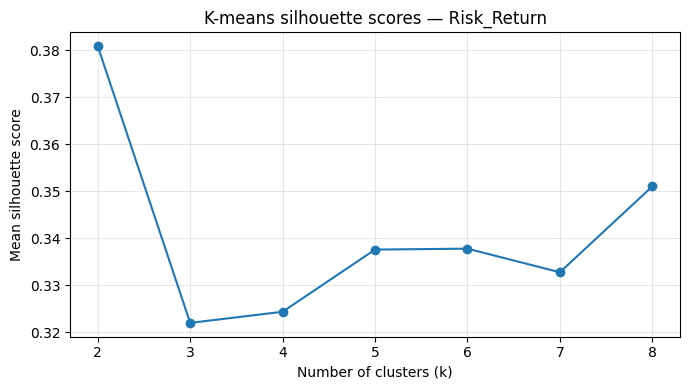

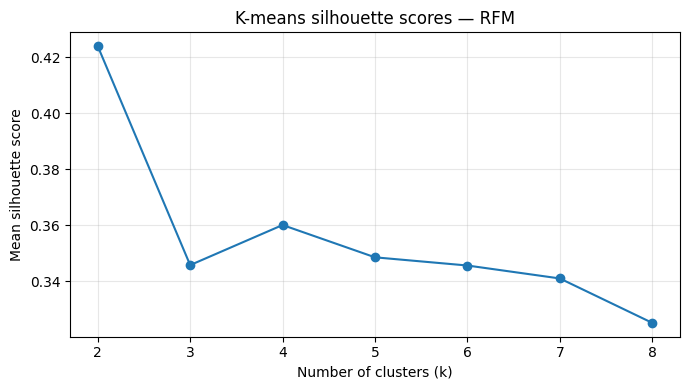

In [ ]:
# Plotting silhouette scores for each matrix
for name in kmeans_matrices:
    results = kmeans_diagnostics[kmeans_diagnostics["Matrix"] == name]

    plt.figure(figsize=(7, 4))
    plt.plot(results["k"], results["Silhouette"], marker="o")
    plt.xticks(list(k_values))
    plt.title("K-means silhouette scores — " + name)
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Mean silhouette score")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("kmeans_silhouette_" + name.lower() + ".png", dpi=200)
    plt.show()

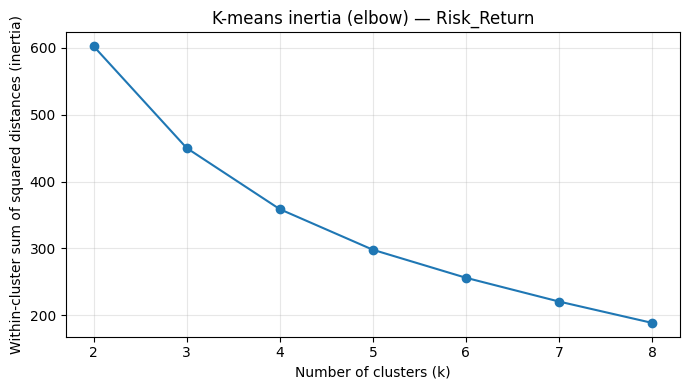

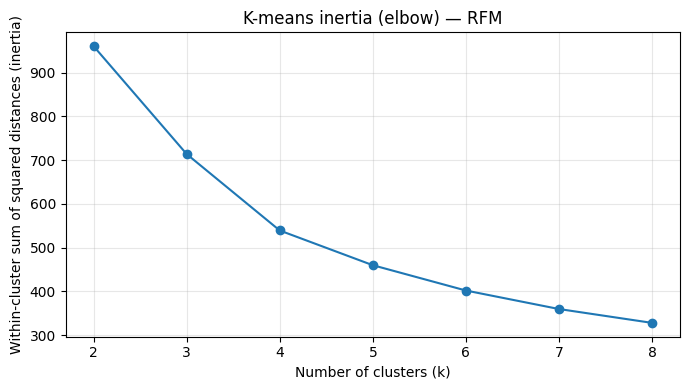

In [ ]:
# Plotting the Plot the inertia curves
for name in kmeans_matrices:
    results = kmeans_diagnostics[kmeans_diagnostics["Matrix"] == name]

    plt.figure(figsize=(7, 4))
    plt.plot(results["k"], results["Inertia"], marker="o")
    plt.xticks(list(k_values))
    plt.title("K-means inertia (elbow) — " + name)
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Within-cluster sum of squared distances (inertia)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("kmeans_inertia_" + name.lower() + ".png", dpi=200)
    plt.show()

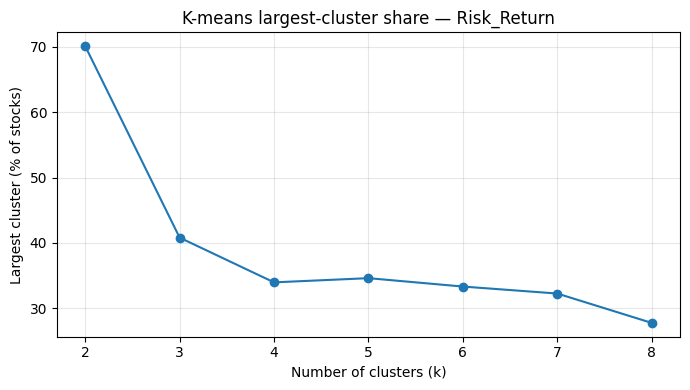

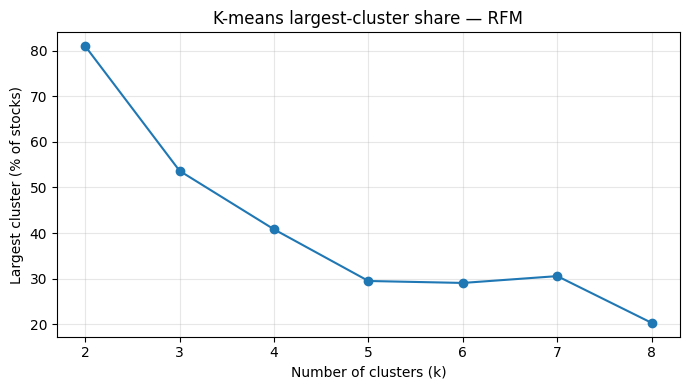

In [ ]:
# Plot largest-cluster proportions
for name in kmeans_matrices:
    results = kmeans_diagnostics[kmeans_diagnostics["Matrix"] == name]

    plt.figure(figsize=(7, 4))
    plt.plot(results["k"], results["Largest_Cluster_Percent"], marker="o")
    plt.xticks(list(k_values))
    plt.title("K-means largest-cluster share — " + name)
    plt.xlabel("Number of clusters (k)")
    plt.ylabel("Largest cluster (% of stocks)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("kmeans_largest_cluster_" + name.lower() + ".png", dpi=200)
    plt.show()

In [ ]:
# Profiling candidate values of k in original units
def kmeans_profile(name, k):
    original = kmeans_original[name].copy()
    original["Cluster"] = kmeans_labels_by_k[name][k]
    groups = original.groupby("Cluster")
    sizes = groups.size()

    profile = pd.DataFrame({
        "Stocks": sizes,
        "Stock_Percent": 100 * sizes / len(original)
    })

    if name == "Risk_Return":
        profile["Median_Weekly_Return_Percent"] = (
            groups["Mean_Weekly_Return"].median() * 100
        )
        profile["Median_Beta"] = groups["Weekly_Beta"].median()
    else:
        profile["Median_R_Days"] = groups["R"].median()
        profile["Median_F_Events"] = groups["F"].median()
        profile["Median_M_USD_Billions"] = (
            groups["M"].median() / 1e9
        )

    return profile.round(3)

In [ ]:
#Inspecting the strongest cluster candidates
kmeans_shortlist = {}

for name in kmeans_matrices:
    results = kmeans_diagnostics[kmeans_diagnostics["Matrix"] == name]
    top_three = results.sort_values(
        "Silhouette", ascending=False
    )["k"].head(3).tolist()

    candidates = sorted(set(top_three + [3, 4]))
    kmeans_shortlist[name] = candidates

    print("\n", name, "— candidate k values:", candidates)
    for k in candidates:
        print("\n", name, "cluster profiles for k =", k)
        display(kmeans_profile(name, k))


 Risk_Return — candidate k values: [2, 3, 4, 6, 8]

 Risk_Return cluster profiles for k = 2


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,328,70.085,0.192,0.844
2,140,29.915,0.484,1.278



 Risk_Return cluster profiles for k = 3


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,161,34.402,0.136,1.081
2,116,24.786,0.520,1.224
3,191,40.812,0.270,0.628



 Risk_Return cluster profiles for k = 4


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,128,27.350,0.127,1.146
2,40,8.547,0.701,1.681
3,159,33.974,0.431,0.967
4,141,30.128,0.181,0.575


... (8 outputs left out)


 RFM cluster profiles for k = 4


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,191,40.812,11.0,2.0,13.131
2,85,18.162,54.0,2.0,21.242
3,79,16.880,11.0,3.0,68.033
4,113,24.145,11.0,4.0,12.866



 RFM cluster profiles for k = 5


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,82,17.521,54.0,2.0,20.950
2,116,24.786,11.0,4.0,13.109
3,99,21.154,11.0,2.0,34.172
4,33,7.051,11.0,4.0,115.874
5,138,29.487,11.0,3.0,10.139


In [ ]:
#Selecting and recording the two final K means solutions
selected_kmeans_risk = 5
selected_kmeans_rfm = 4

kmeans_selected_labels = None

if selected_kmeans_risk is None or selected_kmeans_rfm is None:
    print("Choose both K-means k values after reviewing Steps 2–4.")
else:
    assert selected_kmeans_risk in k_values
    assert selected_kmeans_rfm in k_values

    kmeans_risk_labels = pd.Series(
        kmeans_labels_by_k["Risk_Return"][selected_kmeans_risk],
        index=risk_return_scaled.index,
        name="KMeans_Risk_Cluster"
    )
    kmeans_rfm_labels = pd.Series(
        kmeans_labels_by_k["RFM"][selected_kmeans_rfm],
        index=rfm_scaled.index,
        name="KMeans_RFM_Cluster"
    )
    kmeans_selected_labels = pd.concat(
        [kmeans_risk_labels, kmeans_rfm_labels], axis=1
    )

    print("Selected Risk–Return k:", selected_kmeans_risk)
    print("Selected RFM k:", selected_kmeans_rfm)
    print("\nFinal Risk–Return cluster sizes:")
    display(kmeans_risk_labels.value_counts().sort_index().to_frame("Stocks"))
    print("\nFinal RFM cluster sizes:")
    display(kmeans_rfm_labels.value_counts().sort_index().to_frame("Stocks"))
    print("\nOriginal-unit profile: Risk–Return")
    display(kmeans_profile("Risk_Return", selected_kmeans_risk))
    print("\nOriginal-unit profile: RFM")
    display(kmeans_profile("RFM", selected_kmeans_rfm))

Selected Risk–Return k: 5
Selected RFM k: 4

Final Risk–Return cluster sizes:


,Stocks
KMeans_Risk_Cluster,
1,27
2,120
3,108
4,51
5,162



Final RFM cluster sizes:


,Stocks
KMeans_RFM_Cluster,
1,191
2,85
3,79
4,113



Original-unit profile: Risk–Return


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,27,5.769,0.831,1.450
2,120,25.641,0.195,0.532
3,108,23.077,0.078,1.036
4,51,10.897,0.268,1.533
5,162,34.615,0.415,0.982



Original-unit profile: RFM


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,191,40.812,11.0,2.0,13.131
2,85,18.162,54.0,2.0,21.242
3,79,16.880,11.0,3.0,68.033
4,113,24.145,11.0,4.0,12.866


In [ ]:
#Check sensitivity to starting centres
if kmeans_selected_labels is not None:
    seed_checks = []

    selected_pairs = {
        "Risk_Return": selected_kmeans_risk,
        "RFM": selected_kmeans_rfm
    }

    for name, k in selected_pairs.items():
        baseline_labels = kmeans_labels_by_k[name][k]
        x = kmeans_matrices[name].to_numpy()

        for seed in [0, 10, 21, 42, 99]:
            check_model = KMeans(
                n_clusters=k,
                init="k-means++",
                n_init=kmeans_n_init,
                random_state=seed,
                max_iter=300
            )
            check_labels = check_model.fit_predict(x) + 1

            seed_checks.append({
                "Matrix": name,
                "k": k,
                "Seed": seed,
                "Inertia": check_model.inertia_,
                "ARI_vs_Selected": adjusted_rand_score(
                    baseline_labels, check_labels
                )
            })

    kmeans_seed_check = pd.DataFrame(seed_checks)
    print("K-means initialisation sensitivity:")
    display(kmeans_seed_check.round(3))
else:
    print("Run this check after setting both selected k values.")


K-means initialisation sensitivity:


,Matrix,k,Seed,Inertia,ARI_vs_Selected
0,Risk_Return,5,0,298.062,0.960
1,Risk_Return,5,10,298.042,0.946
2,Risk_Return,5,21,297.986,0.983
3,Risk_Return,5,42,298.031,1.000
4,Risk_Return,5,99,298.057,0.960
5,RFM,4,0,539.109,1.000
6,RFM,4,10,539.109,1.000
7,RFM,4,21,539.109,1.000
8,RFM,4,42,539.109,1.000
9,RFM,4,99,539.109,1.000


In [ ]:
#Validating and Saving outputs
# Preserve evidence for all k from 2 to 8
kmeans_diagnostics.to_csv("kmeans_k_selection_diagnostics.csv", index=False)

# Save original-unit candidate profiles for reporting
candidate_profiles = []
for name in kmeans_matrices:
    for k in kmeans_shortlist[name]:
        table = kmeans_profile(name, k).reset_index()
        table.insert(0, "k", k)
        table.insert(0, "Matrix", name)
        candidate_profiles.append(table)

pd.concat(candidate_profiles, ignore_index=True).to_csv(
    "kmeans_candidate_original_unit_profiles.csv", index=False
)

if kmeans_selected_labels is not None:
    assert kmeans_selected_labels.index.equals(risk_return_scaled.index)
    assert not kmeans_selected_labels.isna().any().any()
    assert kmeans_risk_labels.nunique() == selected_kmeans_risk
    assert kmeans_rfm_labels.nunique() == selected_kmeans_rfm

    kmeans_selected_labels.to_csv("kmeans_selected_cluster_labels.csv")
    kmeans_profile("Risk_Return", selected_kmeans_risk).to_csv(
        "kmeans_risk_final_profile.csv"
    )
    kmeans_profile("RFM", selected_kmeans_rfm).to_csv(
        "kmeans_rfm_final_profile.csv"
    )

    pd.DataFrame({
        "Matrix": ["Risk_Return", "RFM"],
        "Selected_k": [selected_kmeans_risk, selected_kmeans_rfm],
        "Method": ["KMeans", "KMeans"],
        "Seed": [kmeans_seed, kmeans_seed],
        "Initialisations": [kmeans_n_init, kmeans_n_init],
        "Stocks": [len(risk_return_scaled), len(rfm_scaled)]
    }).to_csv("kmeans_selected_settings.csv", index=False)

    if "kmeans_seed_check" in locals():
        kmeans_seed_check.to_csv(
            "kmeans_initialisation_sensitivity.csv", index=False
        )

    print("Final K-means assignments, profiles and settings saved.")
else:
    print("Candidate evidence saved. Final labels await the selected k values.")

Final K-means assignments, profiles and settings saved.


###2.4 Cluster Profiles and algorithm comparison

In [ ]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Confirm all previous tasks produced final assignments
assert isinstance(ward_selected_labels, pd.DataFrame)
assert isinstance(kmeans_selected_labels, pd.DataFrame)
assert rfm_scaled.columns.tolist() == ["Log_R", "F", "Log_M"]

# Same stocks, same row ordering, no missing labels
stock_index = risk_return_original.index
for table in [rfm_original, risk_return_scaled, rfm_scaled,
              ward_selected_labels, kmeans_selected_labels]:
    assert table.index.equals(stock_index), "Different stock sets or row order"
    assert table.index.is_unique

assert ward_selected_labels.columns.tolist() == [
    "Ward_Risk_Cluster", "Ward_RFM_Cluster"
]
assert kmeans_selected_labels.columns.tolist() == [
    "KMeans_Risk_Cluster", "KMeans_RFM_Cluster"
]
assert not ward_selected_labels.isna().any().any()
assert not kmeans_selected_labels.isna().any().any()
assert np.isfinite(risk_return_original.to_numpy()).all()
assert np.isfinite(rfm_original.to_numpy()).all()

print("Common stocks:", len(stock_index))
print("Ward cluster counts:", selected_k_risk, selected_k_rfm)
print("K-means cluster counts:", selected_kmeans_risk, selected_kmeans_rfm)
print("Both methods use identical stock order:",
      ward_selected_labels.index.equals(kmeans_selected_labels.index))
print("Final label columns:",
      ward_selected_labels.columns.tolist() + kmeans_selected_labels.columns.tolist())

Common stocks: 468
Ward cluster counts: 3 4
K-means cluster counts: 5 4
Both methods use identical stock order: True
Final label columns: ['Ward_Risk_Cluster', 'Ward_RFM_Cluster', 'KMeans_Risk_Cluster', 'KMeans_RFM_Cluster']


In [ ]:
#Comparing the four selected cluster profiles in original units
# Match final label columns to the two feature matrices
cluster_inputs = {
    "Risk_Return": {
        "original": risk_return_original,
        "Ward": ward_selected_labels["Ward_Risk_Cluster"],
        "KMeans": kmeans_selected_labels["KMeans_Risk_Cluster"]
    },
    "RFM": {
        "original": rfm_original,
        "Ward": ward_selected_labels["Ward_RFM_Cluster"],
        "KMeans": kmeans_selected_labels["KMeans_RFM_Cluster"]
    }
}

# Produce comparable original-unit tables for the four final solutions
cluster_profiles = {}

for matrix_name, item in cluster_inputs.items():
    for method in ["Ward", "KMeans"]:
        original = item["original"].copy()
        original["Cluster"] = item[method]
        groups = original.groupby("Cluster")

        profile = pd.DataFrame({
            "Stocks": groups.size(),
            "Stock_Percent": 100 * groups.size() / len(original)
        })

        if matrix_name == "Risk_Return":
            profile["Median_Weekly_Return_Percent"] = (
                groups["Mean_Weekly_Return"].median() * 100
            )
            profile["Median_Beta"] = groups["Weekly_Beta"].median()
        else:
            profile["Median_R_Days"] = groups["R"].median()
            profile["Median_F_Events"] = groups["F"].median()
            profile["Median_M_USD_Billions"] = groups["M"].median() / 1e9

        cluster_profiles[(matrix_name, method)] = profile.round(3)

        print("\n", matrix_name, "—", method, "final cluster profiles:")
        display(profile.round(3))


 Risk_Return — Ward final cluster profiles:


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,317,67.735,0.199,0.824
2,56,11.966,0.267,1.554
3,95,20.299,0.547,1.179



 Risk_Return — KMeans final cluster profiles:


,Stocks,Stock_Percent,Median_Weekly_Return_Percent,Median_Beta
Cluster,,,,
1,27,5.769,0.831,1.450
2,120,25.641,0.195,0.532
3,108,23.077,0.078,1.036
4,51,10.897,0.268,1.533
5,162,34.615,0.415,0.982



 RFM — Ward final cluster profiles:


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,216,46.154,11.0,3.0,10.791
2,124,26.496,11.0,3.0,35.824
3,28,5.983,11.0,5.0,61.087
4,100,21.368,46.5,2.0,19.886



 RFM — KMeans final cluster profiles:


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions
Cluster,,,,,
1,191,40.812,11.0,2.0,13.131
2,85,18.162,54.0,2.0,21.242
3,79,16.880,11.0,3.0,68.033
4,113,24.145,11.0,4.0,12.866


In [ ]:
#Cross tabulation agglomerative against K means for each matrix
#Comparing cluster memberships on exactly the same stocks
algorithm_agreement = []
cluster_crosstabs = {}

for matrix_name, item in cluster_inputs.items():
    ward_labels = item["Ward"]
    kmeans_labels = item["KMeans"]

    counts = pd.crosstab(
        ward_labels, kmeans_labels,
        rownames=["Ward"], colnames=["KMeans"]
    )
    ward_row_percent = counts.div(counts.sum(axis=1), axis=0) * 100

    cluster_crosstabs[matrix_name] = counts
    ari = adjusted_rand_score(ward_labels, kmeans_labels)

    algorithm_agreement.append({
        "Matrix": matrix_name,
        "Ward_k": ward_labels.nunique(),
        "KMeans_k": kmeans_labels.nunique(),
        "Stocks": len(ward_labels),
        "ARI_Selected_Solutions": ari
    })

    print("\n", matrix_name, "— cross-tabulation (number of stocks):")
    display(counts)
    print("Ward-row percentages (where each Ward group goes):")
    display(ward_row_percent.round(1))
    print("ARI:", round(ari, 3))

algorithm_agreement = pd.DataFrame(algorithm_agreement)
print("\nSelected-model algorithm comparison:")
display(algorithm_agreement.round(3))


 Risk_Return — cross-tabulation (number of stocks):


KMeans,1,2,3,4,5
Ward,,,,,
1,0,120,105,0,92
2,4,0,3,49,0
3,23,0,0,2,70


Ward-row percentages (where each Ward group goes):


KMeans,1,2,3,4,5
Ward,,,,,
1,0.0,37.9,33.1,0.0,29.0
2,7.1,0.0,5.4,87.5,0.0
3,24.2,0.0,0.0,2.1,73.7


ARI: 0.234

 RFM — cross-tabulation (number of stocks):


KMeans,1,2,3,4
Ward,,,,
1,143,0,0,73
2,46,0,62,16
3,0,0,15,13
4,2,85,2,11


Ward-row percentages (where each Ward group goes):


KMeans,1,2,3,4
Ward,,,,
1,66.2,0.0,0.0,33.8
2,37.1,0.0,50.0,12.9
3,0.0,0.0,53.6,46.4
4,2.0,85.0,2.0,11.0


ARI: 0.4

Selected-model algorithm comparison:


,Matrix,Ward_k,KMeans_k,Stocks,ARI_Selected_Solutions
0,Risk_Return,3,5,468,0.234
1,RFM,4,4,468,0.400


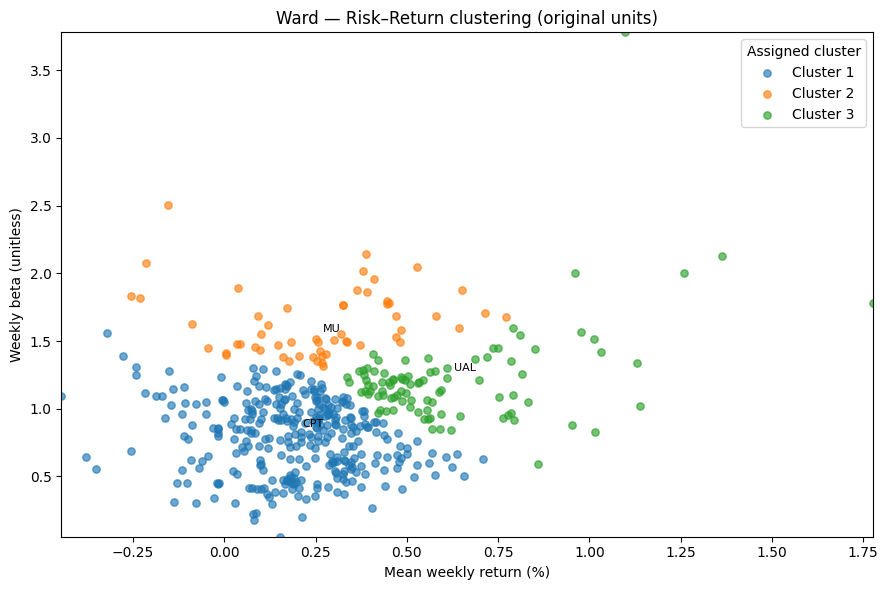

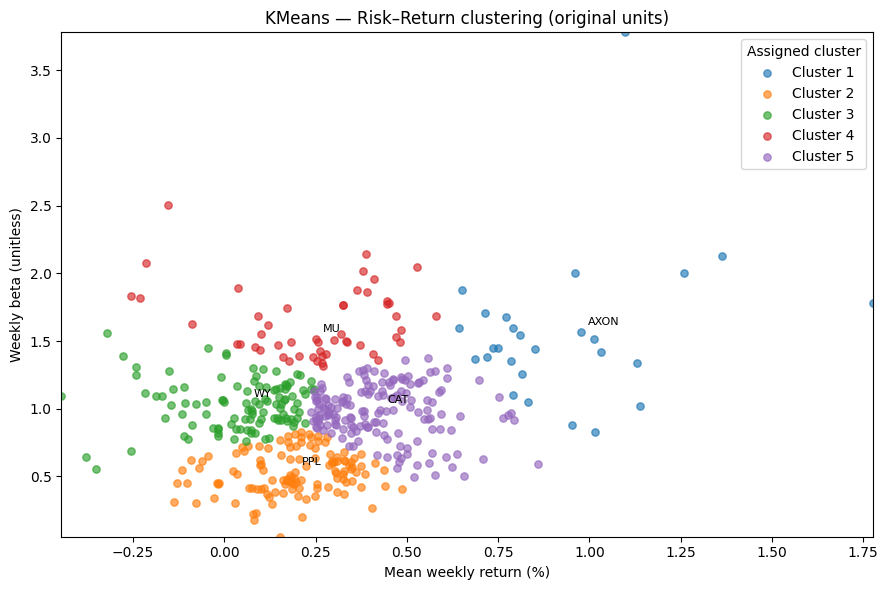

In [ ]:
#Labelled two-dimensional visualisation of Risk–Return clusters
#Plotting Ward and K-means on the same original-unit axes

risk_plot = pd.DataFrame(index=stock_index)
risk_plot["Weekly_Return_Percent"] = (
    risk_return_original["Mean_Weekly_Return"] * 100
)
risk_plot["Weekly_Beta"] = risk_return_original["Weekly_Beta"]

# Same axes for a fair visual comparison
x_limits = (risk_plot["Weekly_Return_Percent"].min(),
            risk_plot["Weekly_Return_Percent"].max())
y_limits = (risk_plot["Weekly_Beta"].min(),
            risk_plot["Weekly_Beta"].max())

for method in ["Ward", "KMeans"]:
    labels = cluster_inputs["Risk_Return"][method]
    plt.figure(figsize=(9, 6))

    for cluster in sorted(labels.unique()):
        tickers = labels.index[labels == cluster]
        plt.scatter(
            risk_plot.loc[tickers, "Weekly_Return_Percent"],
            risk_plot.loc[tickers, "Weekly_Beta"],
            s=28, alpha=0.65, label="Cluster " + str(cluster)
        )

        # Label one representative stock per cluster, not all 468 tickers
        members = risk_return_scaled.loc[tickers]
        centre = members.mean(axis=0)
        representative = ((members - centre) ** 2).sum(axis=1).idxmin()
        plt.annotate(
            representative,
            (risk_plot.loc[representative, "Weekly_Return_Percent"],
             risk_plot.loc[representative, "Weekly_Beta"]),
            xytext=(5, 5), textcoords="offset points", fontsize=8
        )

    plt.xlabel("Mean weekly return (%)")
    plt.ylabel("Weekly beta (unitless)")
    plt.title(method + " — Risk–Return clustering (original units)")
    plt.xlim(x_limits)
    plt.ylim(y_limits)
    plt.legend(title="Assigned cluster", loc="best")
    plt.tight_layout()
    plt.savefig("task2.4_risk_return_" + method.lower() + ".png", dpi=200)
    plt.show()

In [ ]:
#Labelled two-dimensional RFM visualisation using PCA
#Fit one shared PCA projection for both algorithms

assert rfm_scaled.columns.tolist() == ["Log_R", "F", "Log_M"]

rfm_pca = PCA(n_components=2)
rfm_pc_values = rfm_pca.fit_transform(rfm_scaled)

rfm_pca_coordinates = pd.DataFrame(
    rfm_pc_values, index=rfm_scaled.index, columns=["PC1", "PC2"]
)

pca_variance = pd.Series(
    rfm_pca.explained_variance_ratio_, index=["PC1", "PC2"]
)
pca_loadings = pd.DataFrame(
    rfm_pca.components_.T,
    index=rfm_scaled.columns,
    columns=["PC1", "PC2"]
)

print("Explained variance by each component (%):")
display((100 * pca_variance).round(2))
print("Total variance represented in 2D (%):",
      round(100 * pca_variance.sum(), 2))
print("PCA loadings (on standardised Log_R, F, Log_M):")
display(pca_loadings.round(3))

Explained variance by each component (%):


PC1    43.97
PC2    33.73
dtype: float64

Total variance represented in 2D (%): 77.7
PCA loadings (on standardised Log_R, F, Log_M):


,PC1,PC2
Log_R,0.713,0.033
F,-0.649,0.409
Log_M,0.265,0.912


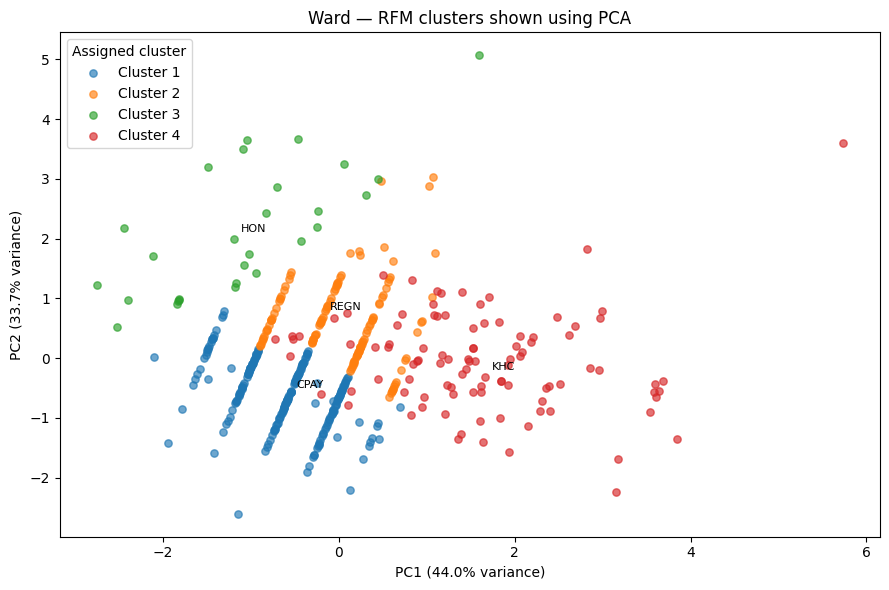

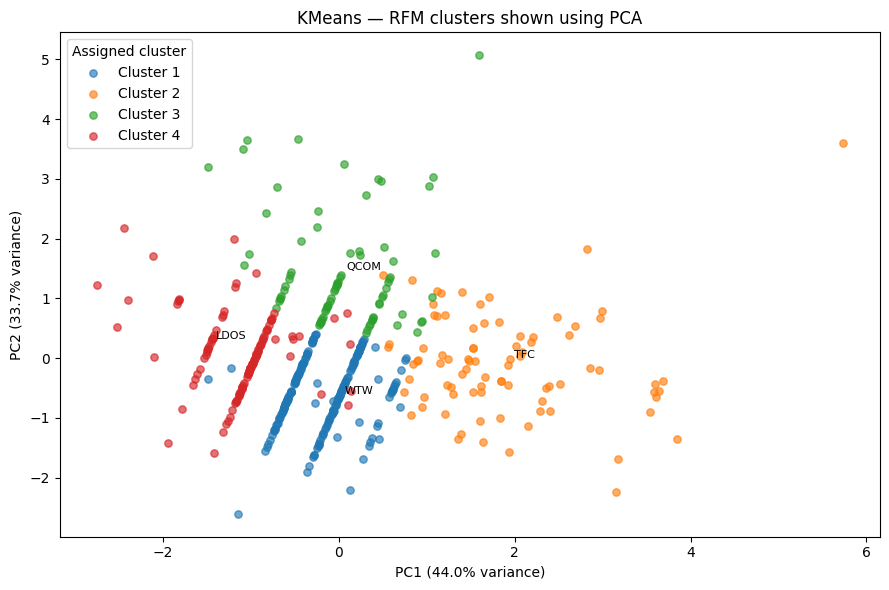

In [ ]:
for method in ["Ward", "KMeans"]:
    labels = cluster_inputs["RFM"][method]
    plt.figure(figsize=(9, 6))

    for cluster in sorted(labels.unique()):
        tickers = labels.index[labels == cluster]
        plt.scatter(
            rfm_pca_coordinates.loc[tickers, "PC1"],
            rfm_pca_coordinates.loc[tickers, "PC2"],
            s=28, alpha=0.65, label="Cluster " + str(cluster)
        )

        # Identify one representative stock per cluster in original 3D input
        members = rfm_scaled.loc[tickers]
        centre = members.mean(axis=0)
        representative = ((members - centre) ** 2).sum(axis=1).idxmin()
        plt.annotate(
            representative,
            (rfm_pca_coordinates.loc[representative, "PC1"],
             rfm_pca_coordinates.loc[representative, "PC2"]),
            xytext=(5, 5), textcoords="offset points", fontsize=8
        )

    plt.xlabel("PC1 (" + str(round(100 * pca_variance["PC1"], 1)) + "% variance)")
    plt.ylabel("PC2 (" + str(round(100 * pca_variance["PC2"], 1)) + "% variance)")
    plt.title(method + " — RFM clusters shown using PCA")
    plt.legend(title="Assigned cluster", loc="best")
    plt.tight_layout()
    plt.savefig("task2.4_rfm_pca_" + method.lower() + ".png", dpi=200)
    plt.show()

In [ ]:
#Comparing the selected solutions silhouette scores and sizes
comparison_records = []

for matrix_name, ward_k, km_k in [
    ("Risk_Return", selected_k_risk, selected_kmeans_risk),
    ("RFM", selected_k_rfm, selected_kmeans_rfm)
]:
    for method, k, diagnostics in [
        ("Ward", ward_k, ward_diagnostics),
        ("KMeans", km_k, kmeans_diagnostics)
    ]:
        row = diagnostics.loc[
            (diagnostics["Matrix"] == matrix_name) &
            (diagnostics["k"] == k)
        ]
        assert len(row) == 1

        comparison_records.append({
            "Matrix": matrix_name,
            "Method": method,
            "k": k,
            "Silhouette": row["Silhouette"].iloc[0],
            "Smallest_Cluster": row["Smallest_Cluster"].iloc[0],
            "Largest_Cluster_Percent": row["Largest_Cluster_Percent"].iloc[0]
        })

cluster_method_summary = pd.DataFrame(comparison_records)
print("Selected models — diagnostic summary:")
display(cluster_method_summary.round(3))

Selected models — diagnostic summary:


,Matrix,Method,k,Silhouette,Smallest_Cluster,Largest_Cluster_Percent
0,Risk_Return,Ward,3,0.361,56,67.735
1,Risk_Return,KMeans,5,0.338,27,34.615
2,RFM,Ward,4,0.326,28,46.154
3,RFM,KMeans,4,0.360,79,40.812


In [ ]:
#Saving the findings and evidence

cluster_comparison_master = pd.concat([
    risk_return_original,
    rfm_original,
    ward_selected_labels,
    kmeans_selected_labels
], axis=1)

assert cluster_comparison_master.index.equals(stock_index)
assert len(cluster_comparison_master) == len(stock_index)
assert not cluster_comparison_master.isna().any().any()

cluster_comparison_master.to_csv(
    "task2.4_stock_memberships_and_original_features.csv"
)

# Save comparable original-unit profiles
profile_exports = []
for (matrix_name, method), profile in cluster_profiles.items():
    table = profile.reset_index()
    table.insert(0, "Method", method)
    table.insert(0, "Matrix", matrix_name)
    profile_exports.append(table)

pd.concat(profile_exports, ignore_index=True).to_csv(
    "task24_four_original_unit_profiles.csv", index=False
)

algorithm_agreement.to_csv("task24_algorithm_ari.csv", index=False)
cluster_method_summary.to_csv("task24_selected_model_diagnostics.csv", index=False)
rfm_pca_coordinates.to_csv("task24_rfm_pca_coordinates.csv")
pca_loadings.to_csv("task24_rfm_pca_loadings.csv")

for matrix_name, counts in cluster_crosstabs.items():
    counts.to_csv("task24_crosstab_" + matrix_name.lower() + ".csv")

print("Task 2.4 original-unit profiles, assignments, comparisons and charts saved.")
print("Common stocks saved:", len(cluster_comparison_master))

Task 2.4 original-unit profiles, assignments, comparisons and charts saved.
Common stocks saved: 468


###2.5 RFM sensitivity and correlated inputs

####2.5.1 Correlation analysis

In [ ]:
#Verify existing RFM Baseline

from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

# Original, interpretable R, F and M data
assert rfm_original.columns.tolist() == ["R", "F", "M"]
assert rfm_scaled.columns.tolist() == ["Log_R", "F", "Log_M"]
assert rfm_original.index.equals(rfm_scaled.index)
assert rfm_original.index.equals(ward_selected_labels.index)
assert rfm_original.index.is_unique
assert np.isfinite(rfm_original.to_numpy()).all()
assert np.isfinite(rfm_scaled.to_numpy()).all()
assert (rfm_original[["R", "F", "M"]] >= 0).all().all()

ward_rfm_baseline = ward_selected_labels["Ward_RFM_Cluster"].copy()
assert ward_rfm_baseline.notna().all()
assert ward_rfm_baseline.nunique() == selected_k_rfm
assert selected_k_rfm == 4, "Check the selected Ward RFM k from Task 2.2"

print("Common stocks:", len(rfm_original))
print("Baseline clustering features:", rfm_scaled.columns.tolist())
print("Baseline Ward RFM k:", selected_k_rfm)
print("Baseline cluster sizes:")
display(ward_rfm_baseline.value_counts().sort_index().to_frame("Stocks"))

Common stocks: 468
Baseline clustering features: ['Log_R', 'F', 'Log_M']
Baseline Ward RFM k: 4
Baseline cluster sizes:


,Stocks
Ward_RFM_Cluster,
1,216
2,124
3,28
4,100


Pearson correlations required by Task 2.5.1:


,R,F,Log_M
R,1.000,-0.354,0.158
F,-0.354,1.000,0.016
Log_M,0.158,0.016,1.000


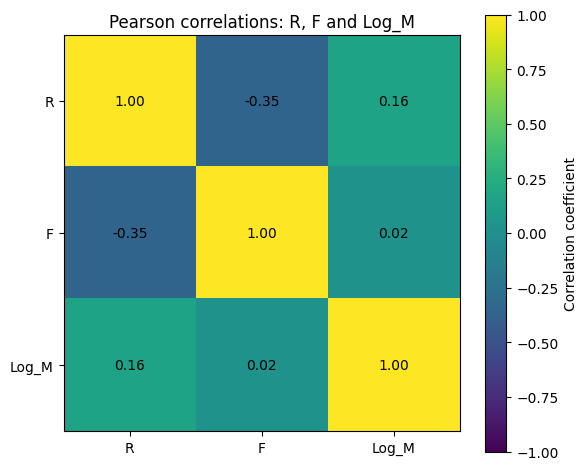

In [ ]:
# Calculating the required correlations

rfm_correlation_input = pd.DataFrame({
    "R": rfm_original["R"],
    "F": rfm_original["F"],
    "Log_M": np.log1p(rfm_original["M"])
}, index=rfm_original.index)

rfm_correlations = rfm_correlation_input.corr(method="pearson")

print("Pearson correlations required by Task 2.5.1:")
display(rfm_correlations.round(3))

# correlation heatmap
fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(rfm_correlations.to_numpy(), vmin=-1, vmax=1)
ax.set_xticks(range(3), labels=rfm_correlations.columns)
ax.set_yticks(range(3), labels=rfm_correlations.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{rfm_correlations.iloc[i, j]:.2f}",
                ha="center", va="center")
ax.set_title("Pearson correlations: R, F and Log_M")
fig.colorbar(heatmap, ax=ax, label="Correlation coefficient")
plt.tight_layout()
plt.savefig("rfm_required_correlation_heatmap.png", dpi=200)
plt.show()

In [ ]:
#Connecting correlations to the actual clustering distances
# Extra diagnostic: actual input variables before standardisation
rfm_model_input = pd.DataFrame({
    "Log_R": np.log1p(rfm_original["R"]),
    "F": rfm_original["F"],
    "Log_M": np.log1p(rfm_original["M"])
}, index=rfm_original.index)

assert np.allclose(rfm_model_input["Log_R"], np.log1p(rfm_original["R"]))
assert np.allclose(rfm_model_input["Log_M"], np.log1p(rfm_original["M"]))

rfm_model_correlations = rfm_model_input.corr(method="pearson")

print("Pearson correlations of actual Ward RFM input variables:")
display(rfm_model_correlations.round(3))

print("Compare original R vs Log_R correlations:")
display(pd.DataFrame({
    "R_with_F": [rfm_correlations.loc["R", "F"]],
    "Log_R_with_F": [rfm_model_correlations.loc["Log_R", "F"]],
    "R_with_Log_M": [rfm_correlations.loc["R", "Log_M"]],
    "Log_R_with_Log_M": [rfm_model_correlations.loc["Log_R", "Log_M"]]
}).round(3))

Pearson correlations of actual Ward RFM input variables:


,Log_R,F,Log_M
Log_R,1.000,-0.296,0.133
F,-0.296,1.000,0.016
Log_M,0.133,0.016,1.000


Compare original R vs Log_R correlations:


,R_with_F,Log_R_with_F,R_with_Log_M,Log_R_with_Log_M
0,-0.354,-0.296,0.158,0.133


####2.5.2 Removal of Monetary

In [ ]:
#Removing Monetary and refitting standardscaler to the retained features

rf_without_m_input = rfm_model_input[["Log_R", "F"]].copy()

# Fit a new scaler
rf_without_m_scaler = StandardScaler()
rf_without_m_scaled = pd.DataFrame(
    rf_without_m_scaler.fit_transform(rf_without_m_input),
    index=rf_without_m_input.index,
    columns=rf_without_m_input.columns
)

# comparison checks
assert rf_without_m_scaled.index.equals(rfm_scaled.index)
assert rf_without_m_scaled.columns.tolist() == ["Log_R", "F"]
assert np.isfinite(rf_without_m_scaled.to_numpy()).all()
assert np.allclose(rf_without_m_scaled.mean(), 0, atol=1e-10)
assert np.allclose(rf_without_m_scaled.std(ddof=0), 1, atol=1e-10)
assert (rf_without_m_input["F"] == rfm_original["F"]).all()

print("Original RFM dimensions:", rfm_scaled.shape)
print("Reduced model dimensions:", rf_without_m_scaled.shape)
print("Reduced model features:", rf_without_m_scaled.columns.tolist())
print("Refitted scaling check:")
display(pd.DataFrame({
    "Mean_after_scaling": rf_without_m_scaled.mean(),
    "Std_after_scaling": rf_without_m_scaled.std(ddof=0)
}).round(3))

Original RFM dimensions: (468, 3)
Reduced model dimensions: (468, 2)
Reduced model features: ['Log_R', 'F']
Refitted scaling check:


,Mean_after_scaling,Std_after_scaling
Log_R,-0.0,1.0
F,-0.0,1.0


In [ ]:
#Refit Ward at the same k and membership cross-tabulation

rf_without_m_k = selected_k_rfm

rf_without_m_linkage = linkage(
    rf_without_m_scaled.to_numpy(),
    method="ward",
    metric="euclidean"
)

rf_without_m_labels = pd.Series(
    cut_tree(rf_without_m_linkage, n_clusters=rf_without_m_k).ravel() + 1,
    index=rf_without_m_scaled.index,
    name="Ward_RF_Without_M"
)

assert rf_without_m_labels.index.equals(ward_rfm_baseline.index)
assert len(rf_without_m_labels) == len(ward_rfm_baseline)
assert rf_without_m_labels.nunique() == rf_without_m_k
assert rf_without_m_labels.notna().all()

rf_without_m_ari = adjusted_rand_score(
    ward_rfm_baseline.to_numpy(),
    rf_without_m_labels.to_numpy()
)

print("Same stocks:", len(rf_without_m_labels))
print("Fixed number of clusters:", rf_without_m_k)
print("Ward baseline vs Ward without M — ARI:", round(rf_without_m_ari, 3))
print("Original Ward RFM sizes:")
display(ward_rfm_baseline.value_counts().sort_index().to_frame("Stocks"))
print("Ward without M sizes:")
display(rf_without_m_labels.value_counts().sort_index().to_frame("Stocks"))

rf_without_m_crosstab = pd.crosstab(
    ward_rfm_baseline, rf_without_m_labels
)
print("Membership cross-tabulation (counts):")
display(rf_without_m_crosstab)
print("Within each original Ward cluster — row percentages:")
display((100 * rf_without_m_crosstab.div(
    rf_without_m_crosstab.sum(axis=1), axis=0
)).round(1))

Same stocks: 468
Fixed number of clusters: 4
Ward baseline vs Ward without M — ARI: 0.278
Original Ward RFM sizes:


,Stocks
Ward_RFM_Cluster,
1,216
2,124
3,28
4,100


Ward without M sizes:


,Stocks
Ward_RF_Without_M,
1,123
2,230
3,58
4,57


Membership cross-tabulation (counts):


Ward_RF_Without_M,1,2,3,4
Ward_RFM_Cluster,,,,
1,64,147,5,0
2,59,61,4,0
3,0,22,6,0
4,0,0,43,57


Within each original Ward cluster — row percentages:


Ward_RF_Without_M,1,2,3,4
Ward_RFM_Cluster,,,,
1,29.6,68.1,2.3,0.0
2,47.6,49.2,3.2,0.0
3,0.0,78.6,21.4,0.0
4,0.0,0.0,43.0,57.0


In [ ]:
#Comparing original unit traded value profiles
#Build original-unit profiles separately
def rfm_sensitivity_profile(cluster_labels):
    values = rfm_original[["R", "F", "M"]].copy()
    values["Cluster"] = cluster_labels
    groups = values.groupby("Cluster")
    sizes = groups.size()

    return pd.DataFrame({
        "Stocks": sizes,
        "Stock_Percent": 100 * sizes / len(values),
        "Median_R_Days": groups["R"].median(),
        "Median_F_Events": groups["F"].median(),
        "Median_M_USD_Billions": groups["M"].median() / 1e9,
        "Q1_M_USD_Billions": groups["M"].quantile(0.25) / 1e9,
        "Q3_M_USD_Billions": groups["M"].quantile(0.75) / 1e9
    }).round(3)

rfm_baseline_profile = rfm_sensitivity_profile(ward_rfm_baseline)
rf_without_m_profile = rfm_sensitivity_profile(rf_without_m_labels)

print("Original selected Ward RFM — profiles in original units:")
display(rfm_baseline_profile)

print("Ward using Log_R and F ONLY — evaluated in original units:")
display(rf_without_m_profile)

print("Note: M is displayed for BOTH solutions, but is not an input in the reduced model.")

Original selected Ward RFM — profiles in original units:


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions,Q1_M_USD_Billions,Q3_M_USD_Billions
Cluster,,,,,,,
1,216,46.154,11.0,3.0,10.791,7.656,14.290
2,124,26.496,11.0,3.0,35.824,26.317,58.042
3,28,5.983,11.0,5.0,61.087,26.866,188.693
4,100,21.368,46.5,2.0,19.886,13.386,32.805


Ward using Log_R and F ONLY — evaluated in original units:


,Stocks,Stock_Percent,Median_R_Days,Median_F_Events,Median_M_USD_Billions,Q1_M_USD_Billions,Q3_M_USD_Billions
Cluster,,,,,,,
1,123,26.282,11.0,2.0,18.375,10.541,32.085
2,230,49.145,11.0,4.0,14.715,9.378,27.292
3,58,12.393,36.0,3.0,20.191,12.474,41.612
4,57,12.179,55.0,2.0,21.242,13.410,30.361


Note: M is displayed for BOTH solutions, but is not an input in the reduced model.


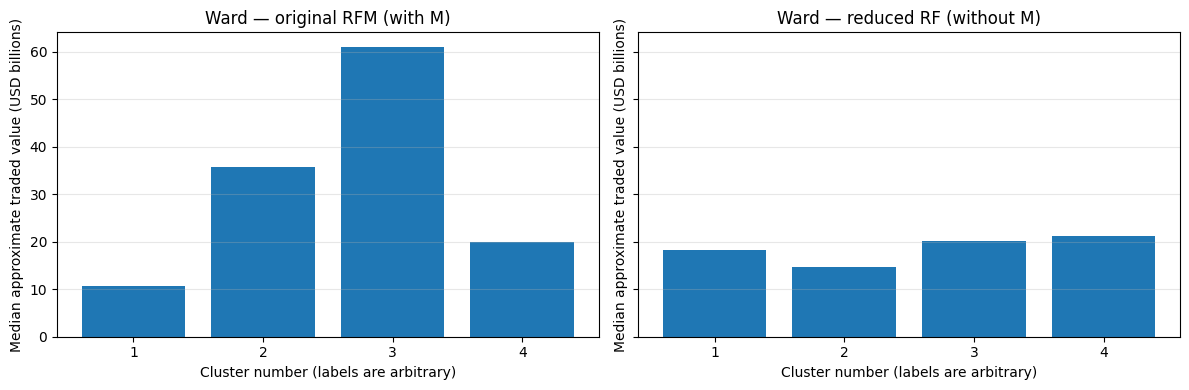

In [ ]:
#Comparison between traded value profiles
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

profile_plots = [
    ("Ward — original RFM (with M)", rfm_baseline_profile),
    ("Ward — reduced RF (without M)", rf_without_m_profile)
]

for ax, (title, profile) in zip(axes, profile_plots):
    ax.bar(profile.index.astype(str), profile["Median_M_USD_Billions"])
    ax.set_title(title)
    ax.set_xlabel("Cluster number (labels are arbitrary)")
    ax.set_ylabel("Median approximate traded value (USD billions)")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("ward_monetary_removal_profile_comparison.png", dpi=200)
plt.show()

In [ ]:
#Saving and verifying evidence

assert rf_without_m_scaled.index.equals(rfm_scaled.index)
assert rf_without_m_labels.index.equals(ward_rfm_baseline.index)
assert len(rf_without_m_labels) == len(rfm_original)
assert rf_without_m_labels.nunique() == selected_k_rfm
assert np.isfinite(rf_without_m_ari)
assert "Log_M" not in rf_without_m_scaled.columns

# Save correlation evidence
rfm_correlations.to_csv("rfm_correlations_required.csv")
rfm_model_correlations.to_csv("rfm_correlations_model_inputs.csv")

# Save reduced feature matrix and cluster assignments
rf_without_m_scaled.to_csv("ward_rf_without_m_scaled.csv")
pd.DataFrame({
    "Ward_RFM_Baseline": ward_rfm_baseline,
    "Ward_RF_Without_M": rf_without_m_labels
}).to_csv("ward_monetary_removal_memberships.csv")
rf_without_m_crosstab.to_csv("ward_monetary_removal_crosstab.csv")

# Save traded-value profiles and a short comparison summary
rfm_baseline_profile.to_csv("ward_rfm_baseline_traded_value_profile.csv")
rf_without_m_profile.to_csv("ward_rf_without_m_traded_value_profile.csv")

rf_sensitivity_summary = pd.DataFrame({
    "Common_Stocks": [len(rfm_original)],
    "Selected_Ward_k": [selected_k_rfm],
    "Original_Features": ["Log_R, F, Log_M"],
    "Reduced_Features": ["Log_R, F"],
    "ARI_With_Vs_Without_M": [rf_without_m_ari]
})
rf_sensitivity_summary.to_csv("ward_monetary_removal_summary.csv", index=False)

display(rf_sensitivity_summary.round(3))
print("Task 2.5 correlations, reduced Ward results, membership comparison and profiles saved.")

,Common_Stocks,Selected_Ward_k,Original_Features,Reduced_Features,ARI_With_Vs_Without_M
0,468,4,"Log_R, F, Log_M","Log_R, F",0.278


Task 2.5 correlations, reduced Ward results, membership comparison and profiles saved.


#3.2 Review of Results and Visualisations

###3.2.1 Cluster profiles and sector composition

In [ ]:
#Join sector metadata to the same 468 shares
import os
if os.path.exists("sp500_tickers.csv"):
    sector_source = pd.read_csv("sp500_tickers.csv")
elif "sp500_df" in globals():
    sector_source = sp500_df.copy()
else:
    raise FileNotFoundError(
        "Original sector metadata missing: restore sp500_tickers.csv "
        "or the sp500_df from your original acquisition cell."
    )

assert {"Symbol", "GICS Sector"}.issubset(sector_source.columns)

sector_lookup = sector_source[["Symbol", "GICS Sector"]].copy()
sector_lookup["Ticker"] = (
    sector_lookup["Symbol"].astype(str).str.strip().str.upper()
    .str.replace(".", "-", regex=False)
)
sector_lookup["Sector"] = sector_lookup["GICS Sector"].astype("string").str.strip()
sector_lookup = sector_lookup[["Ticker", "Sector"]]
assert sector_lookup["Ticker"].is_unique, "Duplicated constituent tickers"

analysis_index = common_features.index
for table in [risk_return_original, rfm_original,
              ward_selected_labels, kmeans_selected_labels]:
    assert table.index.equals(analysis_index), "Different shares or share order"
assert len(analysis_index) == 468, "Expected 468 stocks in this saved notebook"

sector_members = pd.concat([ward_selected_labels, kmeans_selected_labels], axis=1)
sector_members = sector_members.join(
    sector_lookup.set_index("Ticker")["Sector"], how="left"
)

missing = sector_members.index[sector_members["Sector"].isna()].tolist()
assert not missing, f"Resolve missing GICS sectors before analysis: {missing}"
assert sector_members["Sector"].ne("").all()
assert not sector_members.isna().any().any()
assert len(sector_members) == 468

print("Stocks matched to a GICS sector:", len(sector_members))
print("Number of distinct sectors:", sector_members["Sector"].nunique())
print("Sector representation in the 468-stock analysis set:")
sector_baseline = sector_members["Sector"].value_counts().rename_axis("Sector")
sector_baseline_pct = (100 * sector_baseline / len(sector_members)).rename("Overall_Percent")
display(pd.concat([sector_baseline.rename("Stocks"), sector_baseline_pct], axis=1).round(2))

Stocks matched to a GICS sector: 468
Number of distinct sectors: 11
Sector representation in the 468-stock analysis set:


,Stocks,Overall_Percent
Sector,,
Industrials,75,16.03
Financials,72,15.38
Information Technology,71,15.17
Health Care,53,11.32
Consumer Discretionary,47,10.04
Consumer Staples,32,6.84
Real Estate,29,6.2
Utilities,27,5.77
Materials,22,4.7


In [ ]:
#Calculate cluster-sector composition and representation
solution_columns = {
    "Ward — Risk–Return": "Ward_Risk_Cluster",
    "Ward — RFM": "Ward_RFM_Cluster",
    "K-means — Risk–Return": "KMeans_Risk_Cluster",
    "K-means — RFM": "KMeans_RFM_Cluster"
}

sectors = sector_baseline.index.tolist()  # common consistent order
sector_counts = {}
sector_percentages = {}
records = []

for solution, column in solution_columns.items():
    counts = pd.crosstab(sector_members[column], sector_members["Sector"])
    counts = counts.reindex(columns=sectors, fill_value=0).sort_index()
    percents = 100 * counts.div(counts.sum(axis=1), axis=0)
    sector_counts[solution] = counts
    sector_percentages[solution] = percents

    assert counts.to_numpy().sum() == 468
    assert np.allclose(percents.sum(axis=1).to_numpy(), 100)
    for cluster in counts.index:
        for sector in sectors:
            n = int(counts.loc[cluster, sector])
            cluster_pct = float(percents.loc[cluster, sector])
            baseline_pct = float(sector_baseline_pct.loc[sector])
            records.append({
                "Solution": solution,
                "Cluster": int(cluster),
                "Sector": sector,
                "Cluster_Stocks": int(counts.loc[cluster].sum()),
                "Sector_Stocks_in_Cluster": n,
                "Within_Cluster_Percent": cluster_pct,
                "Overall_Sector_Percent": baseline_pct,
                "Representation_Ratio": cluster_pct / baseline_pct
            })

sector_comparison = pd.DataFrame(records)
assert len(sector_comparison) > 0

print("Sector counts — Ward Risk–Return:")
display(sector_counts["Ward — Risk–Return"])
print("Sector counts — Ward RFM:")
display(sector_counts["Ward — RFM"])


# per cluster; a >=5-stock filter avoids overinterpreting 1–2 tiny observations.
reliable_lifts = sector_comparison.loc[
    sector_comparison["Sector_Stocks_in_Cluster"] >= 5
].copy()
sector_top_lifts = (
    reliable_lifts.sort_values(
        ["Solution", "Cluster", "Representation_Ratio", "Sector_Stocks_in_Cluster"],
        ascending=[True, True, False, False]
    )
    .groupby(["Solution", "Cluster"], sort=False)
    .head(2)
    .sort_values(["Solution", "Cluster", "Representation_Ratio"],
                 ascending=[True, True, False])
)

print("Up to two leading sector representation ratios per cluster (min 5 stocks):")
display(sector_top_lifts.round(2))

Sector counts — Ward Risk–Return:


Sector,Industrials,Financials,Information Technology,Health Care,Consumer Discretionary,Consumer Staples,Real Estate,Utilities,Materials,Energy,Communication Services
Ward_Risk_Cluster,,,,,,,,,,,
1,47,54,20,47,23,31,26,25,17,13,14
2,5,7,27,4,10,0,0,0,2,0,1
3,23,11,24,2,14,1,3,2,3,8,4


Sector counts — Ward RFM:


Sector,Industrials,Financials,Information Technology,Health Care,Consumer Discretionary,Consumer Staples,Real Estate,Utilities,Materials,Energy,Communication Services
Ward_RFM_Cluster,,,,,,,,,,,
1,44,35,21,21,16,12,25,16,12,8,6
2,17,20,19,17,16,11,4,1,3,10,6
3,4,2,8,6,3,1,0,1,0,0,3
4,10,15,23,9,12,8,0,9,7,3,4


Up to two leading sector representation ratios per cluster (min 5 stocks):


,Solution,Cluster,Sector,Cluster_Stocks,Sector_Stocks_in_Cluster,Within_Cluster_Percent,Overall_Sector_Percent,Representation_Ratio
141,K-means — RFM,1,Energy,191,14,7.33,4.49,1.63
138,K-means — RFM,1,Real Estate,191,17,8.90,6.20,1.44
150,K-means — RFM,2,Utilities,85,8,9.41,5.77,1.63
145,K-means — RFM,2,Information Technology,85,20,23.53,15.17,1.55
164,K-means — RFM,3,Communication Services,79,7,8.86,4.06,2.18
156,K-means — RFM,3,Information Technology,79,20,25.32,15.17,1.67
171,K-means — RFM,4,Real Estate,113,12,10.62,6.20,1.71
175,K-means — RFM,4,Communication Services,113,6,5.31,4.06,1.31
79,K-means — Risk–Return,1,Information Technology,27,10,37.04,15.17,2.44
77,K-means — Risk–Return,1,Industrials,27,6,22.22,16.03,1.39


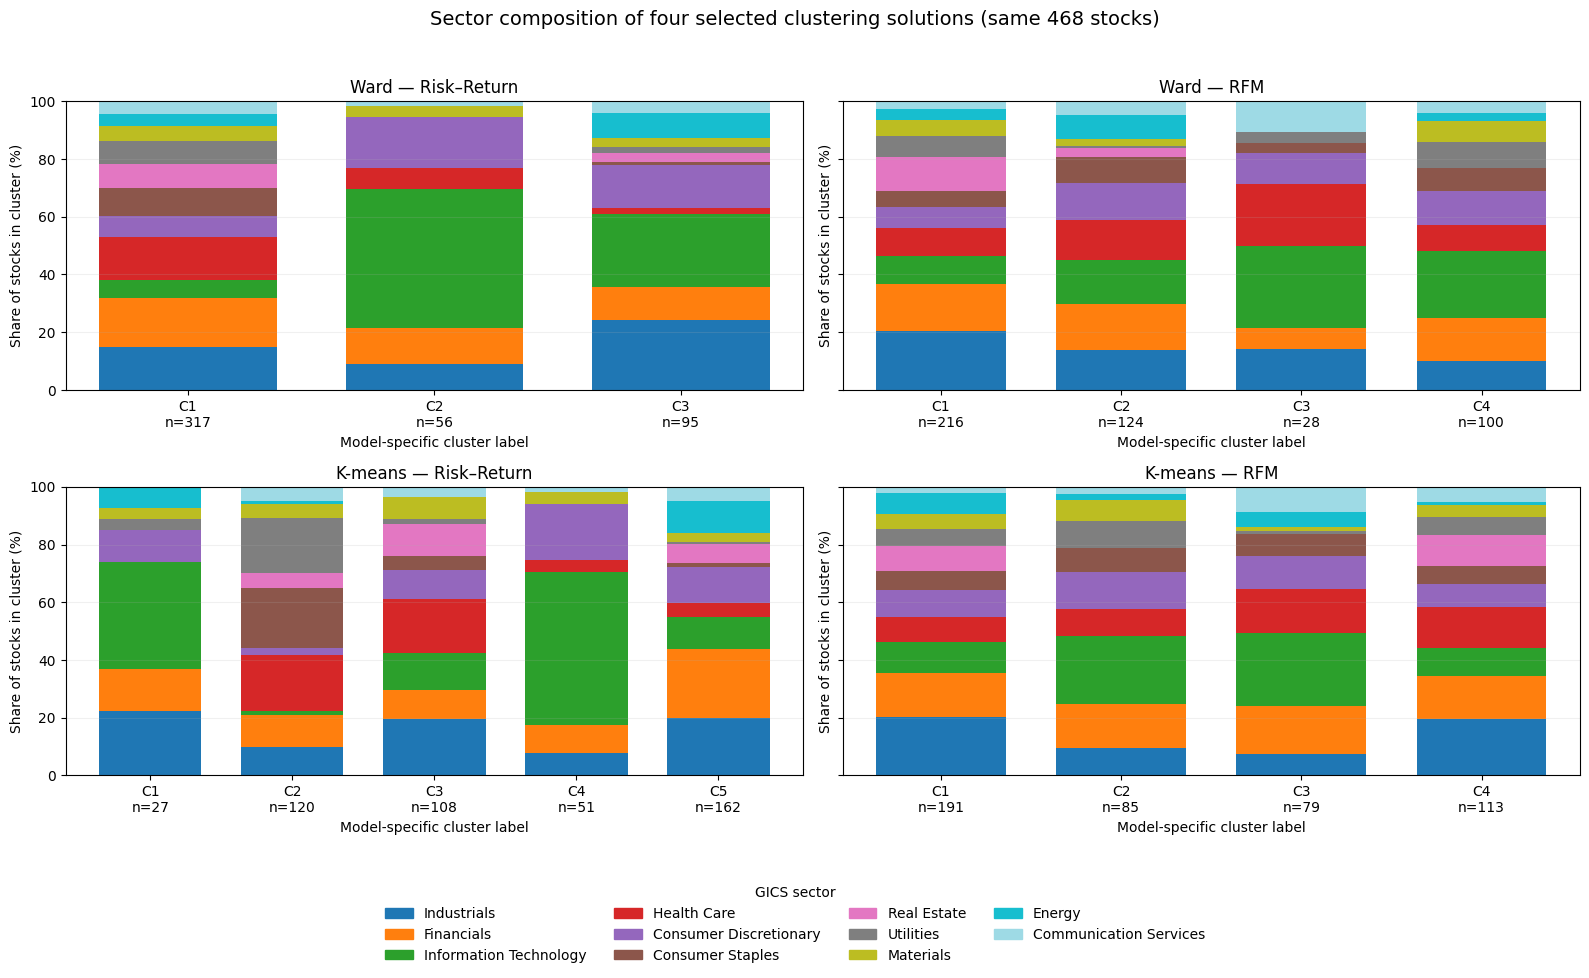

In [ ]:
#compare sector composition for all four cluster solutions
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
palette = plt.get_cmap("tab20")(np.linspace(0, 1, len(sectors)))

for ax, (solution, col) in zip(axes.flat, solution_columns.items()):
    counts = sector_counts[solution]
    percents = sector_percentages[solution]
    x = np.arange(len(percents))
    bottom = np.zeros(len(percents))

    for i, sector in enumerate(sectors):
        values = percents[sector].to_numpy()
        ax.bar(x, values, bottom=bottom, color=palette[i], width=0.72)
        bottom += values

    ax.set_xticks(x)
    ax.set_xticklabels([
        f"C{cluster}\nn={int(counts.loc[cluster].sum())}"
        for cluster in counts.index
    ])
    ax.set_ylim(0, 100)
    ax.set_title(solution)
    ax.set_ylabel("Share of stocks in cluster (%)")
    ax.set_xlabel("Model-specific cluster label")
    ax.grid(axis="y", alpha=0.18)

handles = [plt.Rectangle((0, 0), 1, 1, color=palette[i])
           for i in range(len(sectors))]
fig.legend(handles, sectors, title="GICS sector", loc="lower center",
           bbox_to_anchor=(0.5, 0.015), ncol=4, frameon=False)
fig.suptitle("Sector composition of four selected clustering solutions (same 468 stocks)",
             fontsize=14)
fig.tight_layout(rect=[0, 0.14, 1, 0.96])
fig.savefig("task3_2_1_four_model_sector_composition.png", dpi=220,
            bbox_inches="tight")
plt.show()

Cross-domain Ward membership counts:


Ward_RFM_Cluster,1,2,3,4
Ward_Risk_Cluster,,,,
1,165,78,12,62
2,14,17,9,16
3,37,29,7,22


Percent of each Ward Risk–Return group assigned to each Ward RFM group:


Ward_RFM_Cluster,1,2,3,4
Ward_Risk_Cluster,,,,
1,52.1,24.6,3.8,19.6
2,25.0,30.4,16.1,28.6
3,38.9,30.5,7.4,23.2


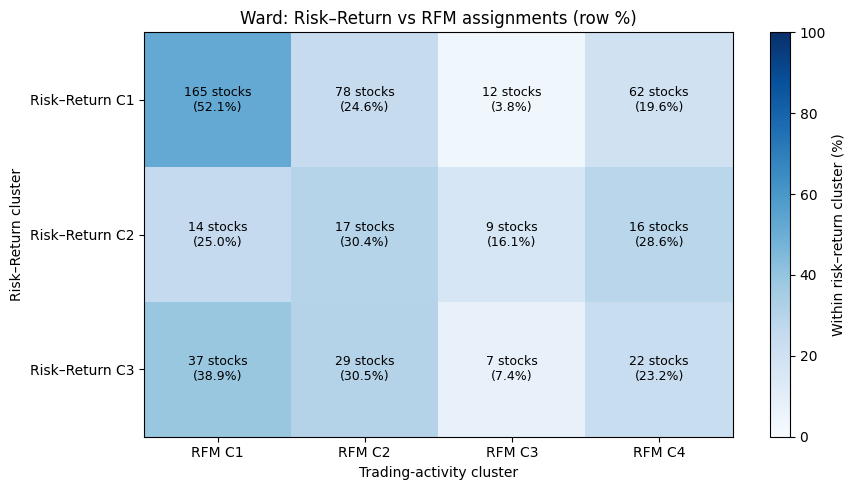

Higher-beta Ward C2 AND frequent/high-value Ward RFM C3: 9 stocks
Examples from this actual intersection (up to 8): ['AMD', 'AMZN', 'BX', 'MRVL', 'MPWR', 'TSLA', 'UBER', 'WDC']


In [ ]:
#Figure 2: compare Ward Risk–Return against Ward RFM membership

ward_cross_counts = pd.crosstab(
    sector_members["Ward_Risk_Cluster"],
    sector_members["Ward_RFM_Cluster"]
)
ward_cross_pct = (100 * ward_cross_counts.div(
    ward_cross_counts.sum(axis=1), axis=0
)).round(1)

assert ward_cross_counts.to_numpy().sum() == 468
assert ward_cross_counts.sum(axis=1).tolist() == [317, 56, 95]
assert ward_cross_counts.sum(axis=0).tolist() == [216, 124, 28, 100]

print("Cross-domain Ward membership counts:")
display(ward_cross_counts)
print("Percent of each Ward Risk–Return group assigned to each Ward RFM group:")
display(ward_cross_pct)

fig, ax = plt.subplots(figsize=(9, 5))
img = ax.imshow(ward_cross_pct.to_numpy(), cmap="Blues", vmin=0, vmax=100,
                aspect="auto")
ax.set_xticks(np.arange(len(ward_cross_pct.columns)))
ax.set_xticklabels([f"RFM C{x}" for x in ward_cross_pct.columns])
ax.set_yticks(np.arange(len(ward_cross_pct.index)))
ax.set_yticklabels([f"Risk–Return C{x}" for x in ward_cross_pct.index])

for i in range(len(ward_cross_pct.index)):
    for j in range(len(ward_cross_pct.columns)):
        n = int(ward_cross_counts.iloc[i, j])
        pct = float(ward_cross_pct.iloc[i, j])
        ax.text(j, i, f"{n} stocks\n({pct:.1f}%)", ha="center", va="center",
                color="white" if pct >= 55 else "black", fontsize=9)

ax.set_title("Ward: Risk–Return vs RFM assignments (row %)")
ax.set_xlabel("Trading-activity cluster")
ax.set_ylabel("Risk–Return cluster")
fig.colorbar(img, ax=ax, label="Within risk–return cluster (%)")
fig.tight_layout()
fig.savefig("task3_2_1_ward_risk_vs_rfm_overlap.png", dpi=220,
            bbox_inches="tight")
plt.show()

# Concrete stock names, but only AFTER observing their true memberships.
overlap_tickers = sector_members.index[
    (sector_members["Ward_Risk_Cluster"] == 2) &
    (sector_members["Ward_RFM_Cluster"] == 3)
].tolist()
print("Higher-beta Ward C2 AND frequent/high-value Ward RFM C3:",
      len(overlap_tickers), "stocks")
print("Examples from this actual intersection (up to 8):",
      overlap_tickers[:8])

In [ ]:
#Save evidence and check its consistency
# Task 3.2.1 — Step 5: preserve reproducible evidence
sector_members.to_csv("task3_2_1_stock_sector_and_four_assignments.csv")
sector_comparison.to_csv("task3_2_1_sector_composition_and_lift.csv", index=False)
sector_top_lifts.to_csv("task3_2_1_leading_sector_ratios.csv", index=False)
ward_cross_counts.to_csv("task3_2_1_ward_risk_rfm_overlap_counts.csv")
ward_cross_pct.to_csv("task3_2_1_ward_risk_rfm_overlap_percent.csv")

assert len(sector_members) == 468
assert all(c.to_numpy().sum() == 468 for c in sector_counts.values())
assert ward_cross_counts.to_numpy().sum() == 468
assert len(sector_members.index.unique()) == 468

print("Task 3.2.1 sector membership, representation tables, Ward overlap and figures saved.")
print("Same 468 stocks retained in all four solutions.")


Task 3.2.1 sector membership, representation tables, Ward overlap and figures saved.
Same 468 stocks retained in all four solutions.


###3.2.2 Sensitivity Findings and Business Uses

In [ ]:
#inspect the nine-stock dual-criterion watchlist
# Task 3.2.2 — optional stakeholder example (no model refitting)
import pandas as pd

watchlist_base = pd.concat([
    rfm_original[["R", "F", "M"]],
    risk_return_original[["Mean_Weekly_Return", "Weekly_Beta"]],
    ward_selected_labels[["Ward_Risk_Cluster", "Ward_RFM_Cluster"]],
    rf_without_m_labels.rename("Ward_RF_Without_M")
], axis=1, join="inner")

assert watchlist_base.shape[0] == 468
assert watchlist_base.index.is_unique
assert watchlist_base.notna().all().all()

historical_review_list = watchlist_base.loc[
    (watchlist_base["Ward_Risk_Cluster"] == 2) &
    (watchlist_base["Ward_RFM_Cluster"] == 3)
].copy()

historical_review_list["M_USD_Billions"] = historical_review_list["M"] / 1e9
historical_review_list["Mean_Weekly_Return_Pct"] = (
    100 * historical_review_list["Mean_Weekly_Return"]
)
historical_review_list = historical_review_list.sort_values(
    ["F", "M"], ascending=[False, False]
)

assert len(historical_review_list) == 9, "Check your saved Ward assignments"
print("Dual-criterion historical review list:", len(historical_review_list))
display(historical_review_list[[
    "R", "F", "M_USD_Billions", "Weekly_Beta", "Mean_Weekly_Return_Pct",
    "Ward_Risk_Cluster", "Ward_RFM_Cluster", "Ward_RF_Without_M"
]].round(3))

historical_review_list.to_csv("task_3_2_2_historical_review_list.csv")

Dual-criterion historical review list: 9


,R,F,M_USD_Billions,Weekly_Beta,Mean_Weekly_Return_Pct,Ward_Risk_Cluster,Ward_RFM_Cluster,Ward_RF_Without_M
Ticker,,,,,,,,
WDC,11,6.0,21.159,1.494,0.257,2,3,2
TSLA,50,5.0,1847.697,2.046,0.528,2,3,3
AMZN,11,5.0,468.177,1.387,0.268,2,3,2
UBER,20,5.0,97.586,1.316,0.271,2,3,3
MRVL,18,5.0,77.284,1.873,0.650,2,3,3
WDAY,11,5.0,51.704,1.392,0.205,2,3,2
MPWR,11,5.0,38.187,1.794,0.445,2,3,2
BX,11,5.0,35.382,1.704,0.714,2,3,2
AMD,18,4.0,313.166,1.878,0.362,2,3,3
